# 02 — Quality-Aware Preprocessing, Domain EDA, Features, and Evaluation Splits

**Purpose:** turn raw scientific records into one leakage-safe modeling dataset. **Main outputs:** quality diagnostics, non-duplicative domain visualizations, normalized features, and reproducible train/validation/test/external-test assignments.

This project follows the experimental protocol defined in Tasks_for_Codex.md.

> **Authoritative scientific scope (2026-07-21).** The prediction-time evidence is title, abstract, proxy-safe lexical/contextual/concept features, and audited publication metadata; exact target-generating taxonomy fields are excluded. The authoritative manuscript name is **MASSK — Multilevel Adaptive Semantic Scientific Knowledge Model**. Any older expansion stored in an executed lock is a legacy lineage alias, not a second model. Existing embedding caches are reused when hashes match; CUDA encoding is not repeated for documentation-only changes.

**Notebook status:** `PASS` for the frozen modeling table, leakage checks, development views, and hashed feature caches.

This notebook builds the reusable modeling corpus after the protocol reset. It removes non-article/junk records, cross-label duplicate components, and high-similarity near-duplicates before assigning temporal and source-aware partitions. Label-dependent EDA is restricted to train/validation; test and external-test are used only for label-free drift and quality diagnostics here. The primary benchmark uses title and abstract only; OpenAlex keywords are held out as concept supervision. Modern frozen encoders are pinned and executed sequentially on CUDA.

<style>
.jp-RenderedHTMLCommon, .jp-RenderedMarkdown, .rendered_html {
  font-size: 18px !important;
  line-height: 1.58 !important;
  max-width: none !important;
}
.jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe {
  font-size: 18px !important;
  line-height: 1.42 !important;
  border-collapse: collapse !important;
  width: auto !important;
  max-width: 100% !important;
}
.jp-RenderedHTMLCommon th, .jp-RenderedHTMLCommon td,
.rendered_html th, .rendered_html td {
  padding: 0.45em 0.65em !important;
  vertical-align: top !important;
}
.jp-OutputArea-output, .output_subarea { overflow-x: auto !important; }
.jp-RenderedHTMLCommon pre, .rendered_html pre { font-size: 17px !important; }
</style>

> **Publication display standard.** Narrative and tables are rendered at 18 px screen text with 18 pt figure labels or larger. Publication figures use Times New Roman at 18–20 pt and 350 dpi. Wide metric sets are split into logically grouped tables instead of being compressed into unreadable canvases.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib
import html
import json
import math
import os
import platform
import re
import subprocess
import sys
import time
import unicodedata
import warnings

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
from scipy.spatial.distance import jensenshannon
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from IPython.display import Markdown, display

mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 19,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.unicode_minus": True,
        "savefig.dpi": 350,
        "figure.dpi": 350,
    }
)
mpl.set_loglevel("error")
PALETTE = {
    "blue": "#2F6B8F",
    "orange": "#C77C2B",
    "green": "#4F7F3A",
    "purple": "#6D5A8D",
    "red": "#B45A55",
    "gray": "#6E7378",
    "light_gray": "#E7EAED",
    "teal": "#4A8C8A",
    "gold": "#C9A227",
    "black": "#222222",
    "white": "#FFFFFF",
}
RANDOM_SEED = 20260716
HF_LOCAL_ONLY = (
    os.getenv("HF_HUB_OFFLINE", "0") == "1" or os.getenv("TRANSFORMERS_OFFLINE", "0") == "1"
)
rng = np.random.default_rng(RANDOM_SEED)

In [2]:
cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "multilevel_semantic_knowledge_structuring", cwd.parent]
PROJECT_ROOT = next(
    candidate
    for candidate in candidates
    if (candidate / "Tasks_for_Codex.md").exists() and (candidate / "dataset").exists()
)
DATASET = PROJECT_ROOT / "dataset"
TABLES = PROJECT_ROOT / "results/tables"
REPORTS = PROJECT_ROOT / "results/reports"
MODELS = PROJECT_ROOT / "results/models/preprocessing_artifacts"
MODELS.mkdir(parents=True, exist_ok=True)

import torch

assert torch.cuda.is_available()
device = torch.device("cuda")

## Load the four pre-declared raw cohorts

In [3]:
openalex_development = pd.read_parquet(DATASET / "processed/openalex_records.parquet").assign(
    cohort="development_2018_2024"
)
arxiv_validation = pd.read_parquet(DATASET / "external_test/arxiv_external_records.parquet").assign(
    cohort="source_shift_validation"
)
openalex_test = pd.read_parquet(
    DATASET / "processed/openalex_confirmatory_2025_records.parquet"
).assign(cohort="confirmatory_test_2025")
arxiv_external = pd.read_parquet(
    DATASET / "external_test/arxiv_external_confirmatory_records.parquet"
).assign(cohort="external_test_arxiv_hosted_2024_2025")

raw_cohorts = pd.concat(
    [openalex_development, arxiv_validation, openalex_test, arxiv_external],
    ignore_index=True,
    sort=False,
)
cohort_ledger = raw_cohorts.groupby(["cohort", "source"], as_index=False).agg(
    records=("paper_id", "size"),
    classes=("thematic_class", "nunique"),
    earliest_year=("publication_year", "min"),
    latest_year=("publication_year", "max"),
)
with pd.option_context(
    "display.max_rows", None, "display.max_colwidth", None, "display.width", 180
):
    display(cohort_ledger)

,cohort,source,records,classes,earliest_year,latest_year
0,confirmatory_test_2025,openalex,2000,8,2025,2025
1,development_2018_2024,openalex,10000,8,2018,2024
2,external_test_arxiv_hosted_2024_2025,arxiv,1200,8,2024,2025
3,source_shift_validation,arxiv,1193,8,2026,2026


## Transparent scientific-text normalization

In [4]:
LATEX_COMMAND = re.compile(r"\\[a-zA-Z]+(?:\[[^]]*\])?(?:\{([^{}]*)\})?")
TAG_PATTERN = re.compile(r"<[^>]+>")
SPACE_PATTERN = re.compile(r"\s+")


def clean_scientific_text(value):
    text = html.unescape("" if value is None else str(value))
    text = unicodedata.normalize("NFKC", text)
    text = TAG_PATTERN.sub(" ", text)
    for _ in range(2):
        text = LATEX_COMMAND.sub(lambda match: f" {match.group(1) or ''} ", text)
    text = text.replace("\x00", " ")
    return SPACE_PATTERN.sub(" ", text).strip()


def normalize_identifier(value):
    text = clean_scientific_text(value).lower()
    return re.sub(r"^https?://(dx\.)?doi\.org/", "", text).strip()


def normalize_title(value):
    text = clean_scientific_text(value).lower()
    return re.sub(r"[^a-z0-9]+", " ", text).strip()


working = raw_cohorts.copy()
working["title_raw"] = working["title"].fillna("")
working["abstract_raw"] = working["abstract"].fillna("")
working["title_clean"] = working["title_raw"].map(clean_scientific_text)
working["abstract_clean"] = working["abstract_raw"].map(clean_scientific_text)
working["normalized_title"] = working["title_clean"].map(normalize_title)
working["normalized_doi"] = working["doi"].map(normalize_identifier)
working["abstract_sha256"] = working["abstract_clean"].map(
    lambda value: hashlib.sha256(value.encode("utf-8")).hexdigest() if value else ""
)
print("Normalized records:", f"{len(working):,}")

Normalized records: 14,393


## Scholarly-work and junk filtering

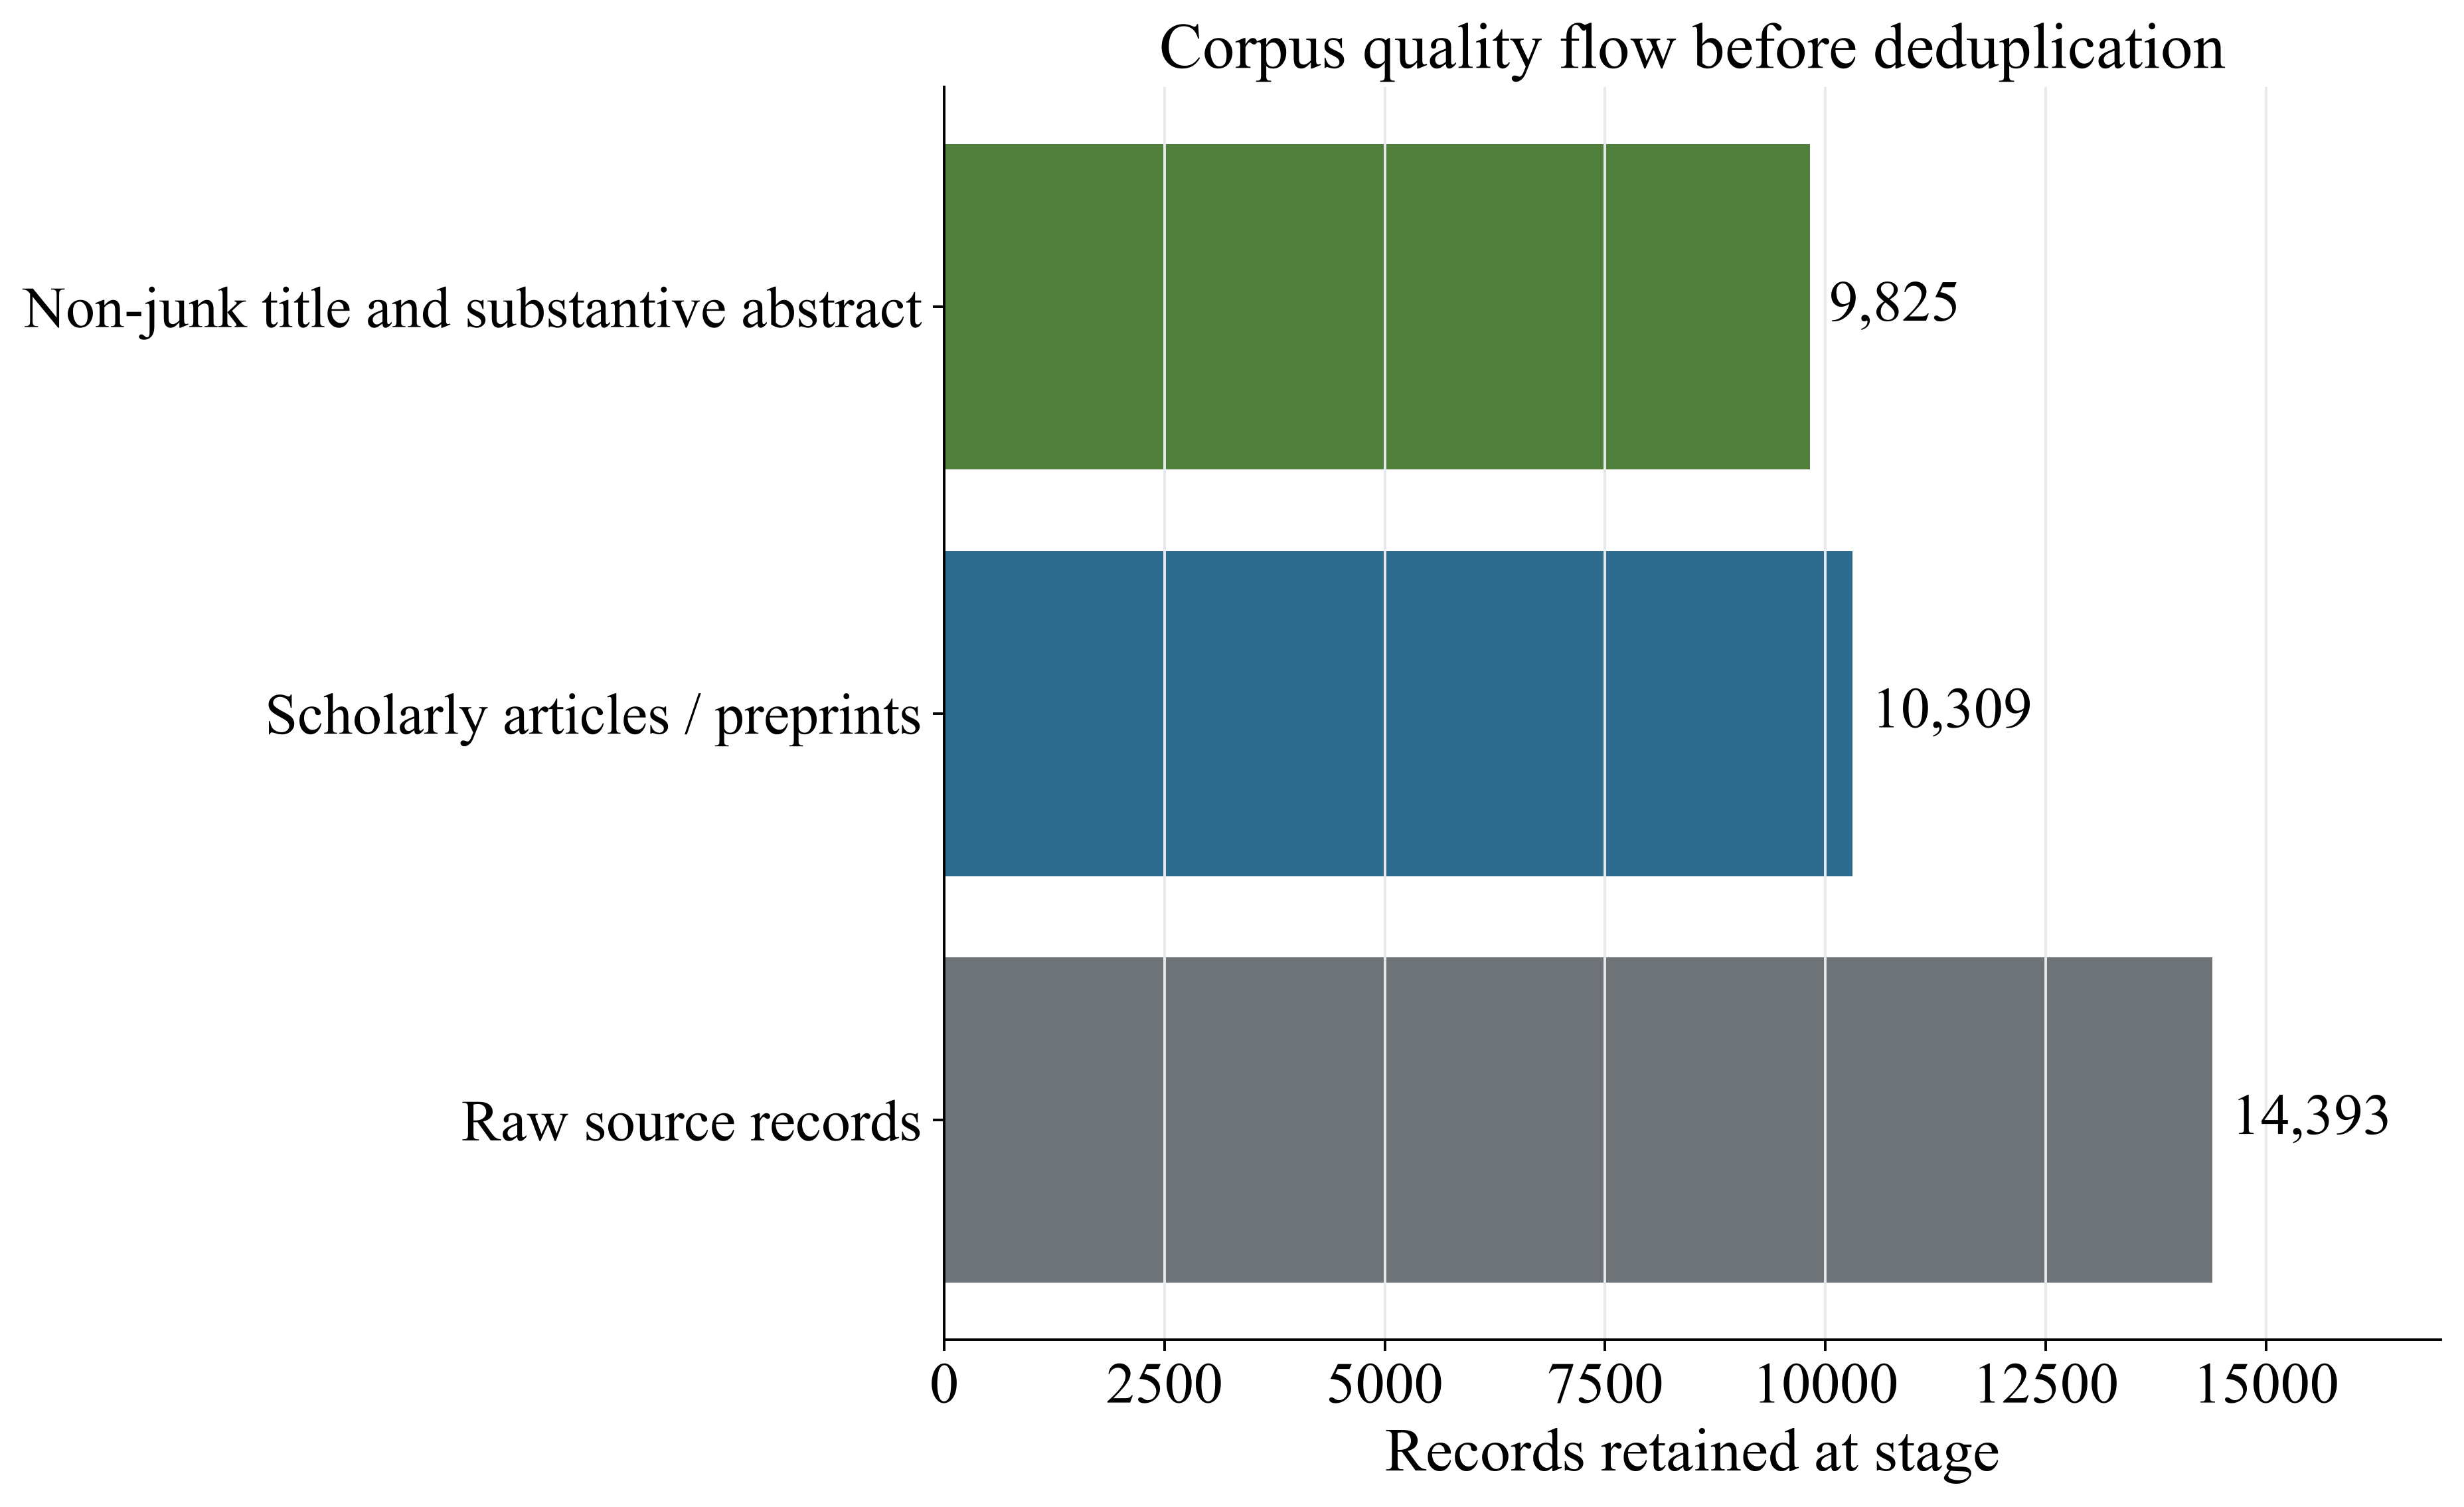

In [5]:
def json_list(value):
    try:
        parsed = json.loads(value) if isinstance(value, str) else value
        return parsed if isinstance(parsed, list) else []
    except Exception:
        return []


working["title_tokens"] = working["title_clean"].str.findall(r"[A-Za-z]{2,}").str.len()
working["abstract_tokens"] = working["abstract_clean"].str.findall(r"[A-Za-z]{2,}").str.len()
working["source_article"] = (
    working["source"].eq("openalex") & working["work_type"].eq("article")
) | working["source"].eq("arxiv")
junk_pattern = re.compile(
    r"(?i)(occurrence download|supporting information|supplementary material|"
    r"graphical abstract|table of contents|\.jpe?g$|\.png$|^untitled$)"
)
working["junk_title"] = working["title_clean"].str.contains(junk_pattern, na=False)
working["content_valid"] = (
    working["title_tokens"].ge(4) & working["abstract_tokens"].ge(30) & ~working["junk_title"]
)
quality_flow = pd.DataFrame(
    [
        ("Raw source records", len(working)),
        ("Scholarly articles / preprints", int(working["source_article"].sum())),
        (
            "Non-junk title and substantive abstract",
            int((working["source_article"] & working["content_valid"]).sum()),
        ),
    ],
    columns=["stage", "records"],
)
working = working[working["source_article"] & working["content_valid"]].copy()

fig, ax = plt.subplots(figsize=(11.5, 7))
bars = ax.barh(
    quality_flow["stage"],
    quality_flow["records"],
    color=[PALETTE["gray"], PALETTE["blue"], PALETTE["green"]],
)
ax.set_title("Corpus quality flow before deduplication")
ax.set_xlabel("Records retained at stage")
ax.set_ylabel("")
ax.grid(axis="x", color=PALETTE["light_gray"], linewidth=0.8)
ax.set_xlim(0, quality_flow["records"].max() * 1.18)
for bar, value in zip(bars, quality_flow["records"]):
    ax.text(
        value + quality_flow["records"].max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{int(value):,}",
        va="center",
        fontsize=18,
    )
fig.subplots_adjust(left=0.34)
plt.show()

### Scientific interpretation

The flow chart quantifies retention after scholarly-type and content-quality rules; the direction of interest is transparent retention without admitting obvious junk. **Article-ready conclusion:** quality filtering was rule-based and applied before modelling. **Limitation:** thresholds operationalize document usability and are not claims about scientific merit.


## Target-proxy analysis and primary-input policy

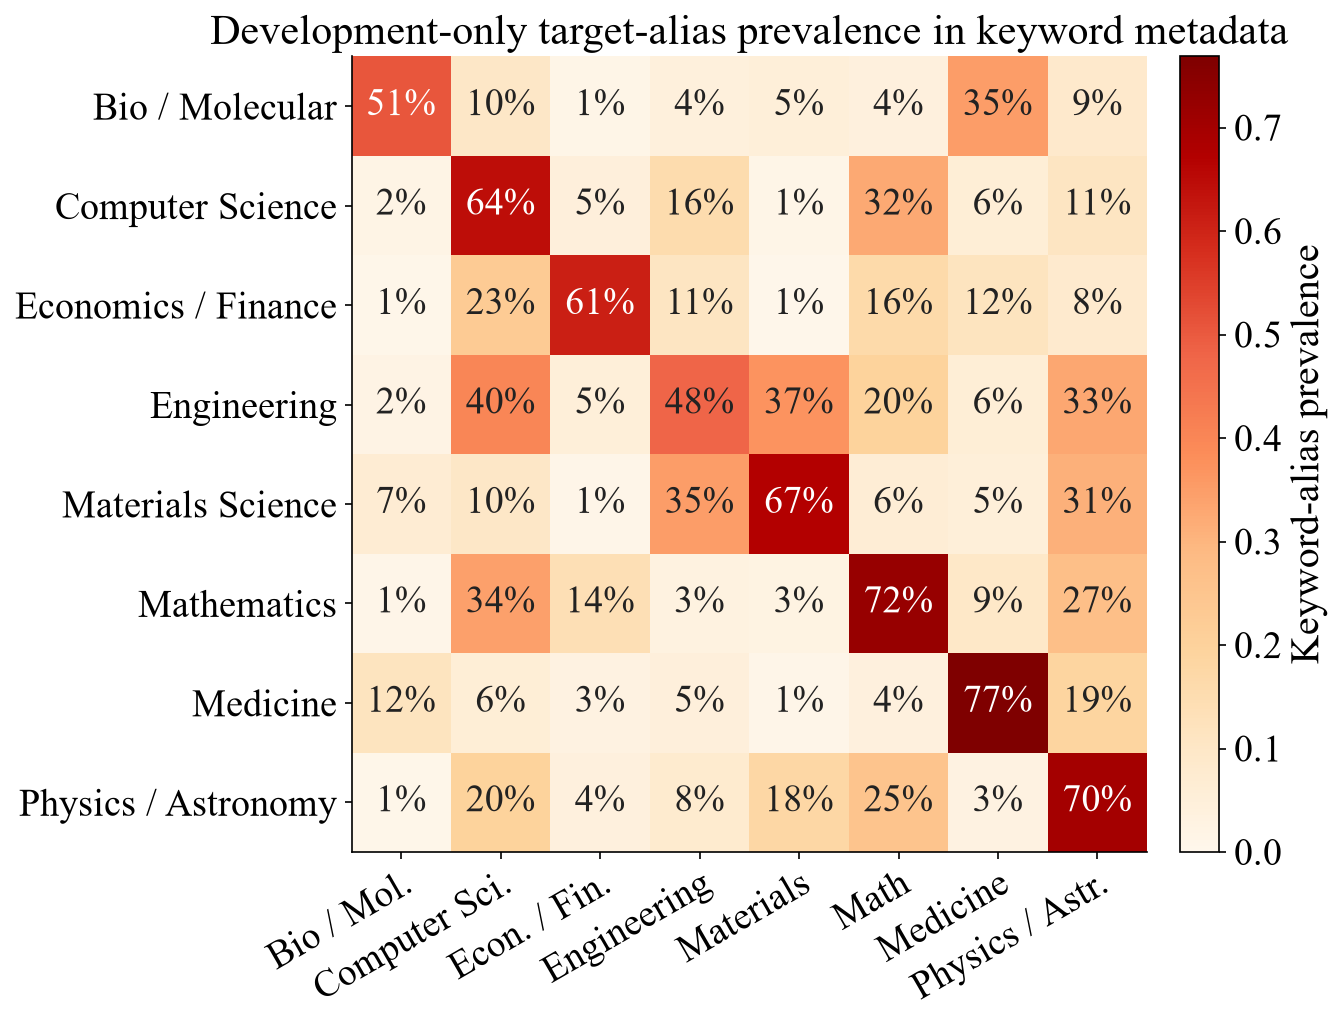

Primary track: title + abstract only. Keywords are reference supervision, not primary predictors.


In [6]:
working["reference_concepts"] = (
    working["keywords_json"]
    .map(json_list)
    .map(lambda values: [clean_scientific_text(value).lower() for value in values if value])
)
class_aliases = {
    "Computer Science": ["computer science", "computing"],
    "Mathematics": ["mathematics", "mathematical"],
    "Physics and Astronomy": ["physics", "astronomy", "astrophysics"],
    "Engineering": ["engineering"],
    "Materials Science": ["materials science"],
    "Economics, Econometrics and Finance": ["economics", "econometrics", "finance"],
    "Biochemistry, Genetics and Molecular Biology": [
        "biochemistry",
        "genetics",
        "molecular biology",
    ],
    "Medicine": ["medicine", "medical"],
}
development_only = working[
    working["cohort"].isin(["development_2018_2024", "source_shift_validation"])
].copy()
proxy_matrix = []
for true_class in sorted(class_aliases):
    subset = development_only[development_only["thematic_class"].eq(true_class)]
    keyword_text = subset["reference_concepts"].map(" ; ".join)
    proxy_matrix.append(
        [
            keyword_text.str.contains(
                "|".join(re.escape(alias) for alias in class_aliases[candidate]),
                regex=True,
                na=False,
            ).mean()
            for candidate in sorted(class_aliases)
        ]
    )
proxy_matrix = np.asarray(proxy_matrix)
class_order = sorted(class_aliases)
short_class_labels = {
    'Biochemistry, Genetics and Molecular Biology': 'Bio / Molecular',
    'Economics, Econometrics and Finance': 'Economics / Finance',
    'Physics and Astronomy': 'Physics / Astronomy',
}
display_classes = [short_class_labels.get(name, name) for name in class_order]
x_axis_classes = [
    'Bio / Mol.',
    'Computer Sci.',
    'Econ. / Fin.',
    'Engineering',
    'Materials',
    'Math',
    'Medicine',
    'Physics / Astr.',
]
fig, ax = plt.subplots(figsize=(12.0, 7.8))
image = ax.imshow(proxy_matrix, cmap='OrRd', vmin=0, vmax=max(0.25, proxy_matrix.max()))
ax.set_title('Development-only target-alias prevalence in keyword metadata')
ax.set_xticks(range(8), x_axis_classes, rotation=30, ha='right', rotation_mode='anchor')
ax.set_yticks(range(8), display_classes)
for i in range(8):
    for j in range(8):
        value = proxy_matrix[i, j]
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            j,
            i,
            f'{value:.0%}',
            ha='center',
            va='center',
            fontsize=18,
            color='white' if luminance < 0.48 else PALETTE['black'],
        )
colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.03)
colorbar.set_label('Keyword-alias prevalence')
fig.subplots_adjust(left=0.22, right=0.94, bottom=0.20, top=0.88)
plt.show()
working["paper_text"] = (working["title_clean"] + " " + working["abstract_clean"]).str.strip()
direct_aliases = sorted({alias for values in class_aliases.values() for alias in values})
working["safe_keyword_text"] = working["reference_concepts"].map(
    lambda values: " ; ".join(
        value for value in values if not any(alias in value for alias in direct_aliases)
    )
)
working["paper_text_enriched"] = (
    working["paper_text"] + " " + working["safe_keyword_text"]
).str.strip()

### Scientific interpretation

The matrix is a development-only weak-label diagnostic: stronger diagonal prevalence is consistent with class-specific keyword metadata, but it is not ground-truth validation. **Article-ready conclusion:** metadata aliases provide partial convergent evidence for the thematic labels. **Limitation:** keyword availability and vocabulary differ by field.


## Connected-component exact deduplication

In [7]:
parent = np.arange(len(working))
rank = np.zeros(len(working), dtype=np.int8)


def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return int(index)


def union(left, right):
    root_left, root_right = find(left), find(right)
    if root_left == root_right:
        return
    if rank[root_left] < rank[root_right]:
        root_left, root_right = root_right, root_left
    parent[root_right] = root_left
    if rank[root_left] == rank[root_right]:
        rank[root_left] += 1


key_columns = ["normalized_doi", "normalized_title", "abstract_sha256", "paper_id"]
for column in key_columns:
    first_seen = {}
    for index, value in enumerate(working[column].fillna("").astype(str)):
        if not value:
            continue
        if value in first_seen:
            union(index, first_seen[value])
        else:
            first_seen[value] = index
working["exact_component"] = [find(index) for index in range(len(working))]
print("Exact duplicate graph components:", working["exact_component"].nunique())

Exact duplicate graph components: 9806


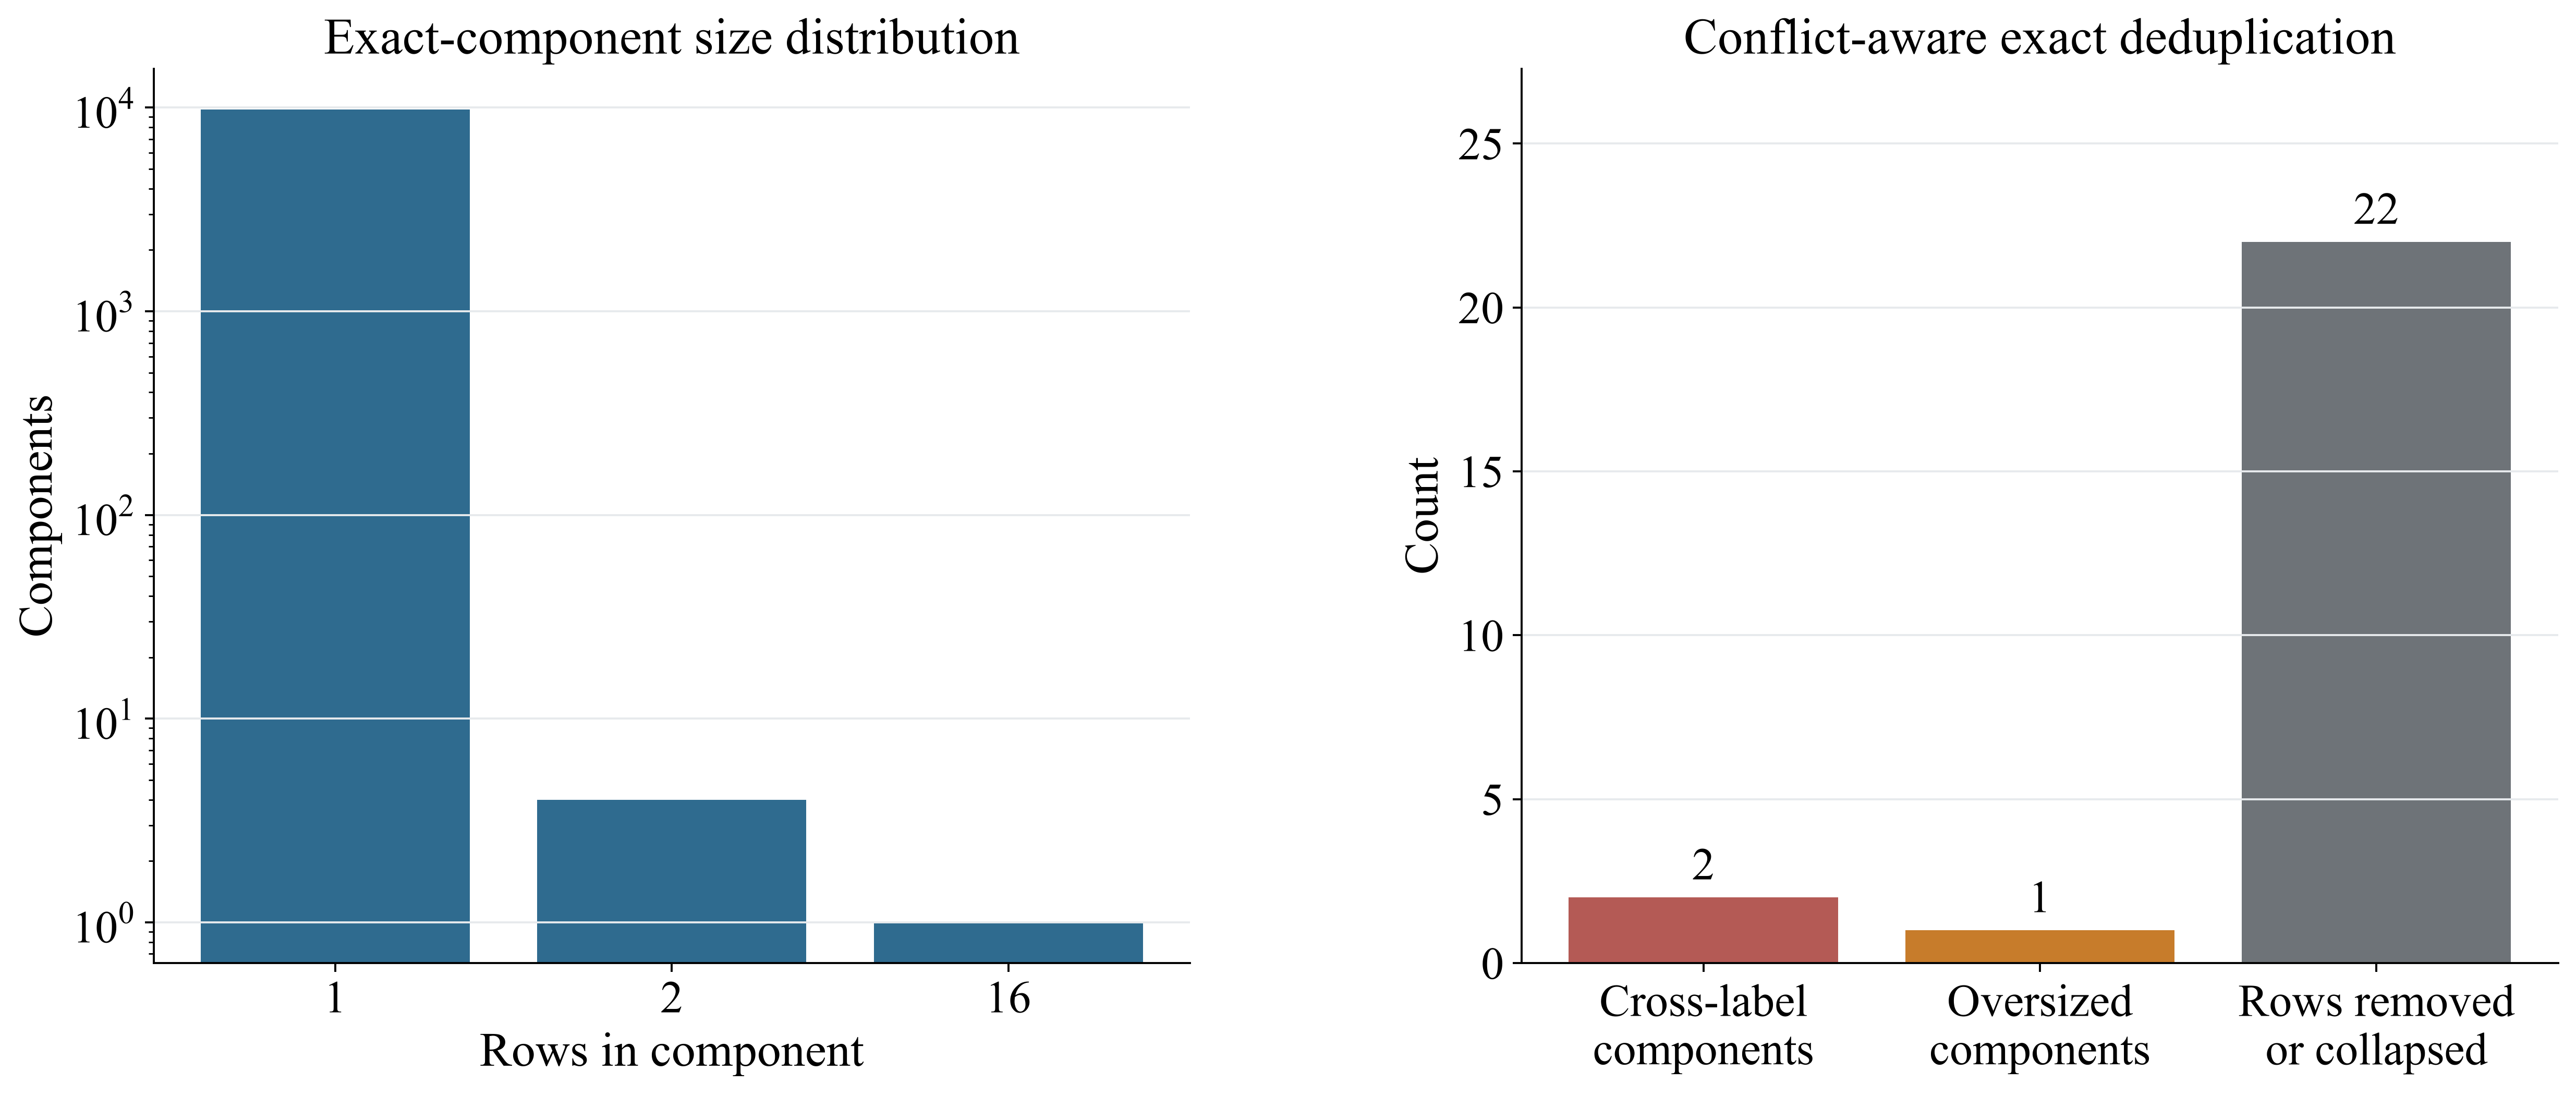

In [8]:
exact_stats = working.groupby("exact_component").agg(
    size=("sample_id", "size"),
    labels=("thematic_class", "nunique"),
    longest_abstract=("abstract_tokens", "max"),
)
conflict_components = exact_stats.index[exact_stats["labels"].gt(1) | exact_stats["size"].gt(10)]
non_conflicting = working[~working["exact_component"].isin(conflict_components)].copy()
non_conflicting = non_conflicting.sort_values(
    ["exact_component", "abstract_tokens", "title_tokens"], ascending=[True, False, False]
).drop_duplicates("exact_component", keep="first")

component_sizes = exact_stats["size"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
axes[0].bar(component_sizes.index.astype(str), component_sizes.values, color=PALETTE["blue"])
axes[0].set_title("Exact-component size distribution")
axes[0].set_xlabel("Rows in component")
axes[0].set_ylabel("Components")
axes[0].set_yscale("log")
axes[0].grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
summary_values = [
    int(exact_stats["labels"].gt(1).sum()),
    int(exact_stats["size"].gt(10).sum()),
    int(len(working) - len(non_conflicting)),
]
labels = ["Cross-label\ncomponents", "Oversized\ncomponents", "Rows removed\nor collapsed"]
bars = axes[1].bar(
    labels, summary_values, color=[PALETTE["red"], PALETTE["orange"], PALETTE["gray"]]
)
axes[1].set_title("Conflict-aware exact deduplication")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
axes[1].set_ylim(0, max(summary_values) * 1.24)
for bar, value in zip(bars, summary_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value + max(summary_values) * 0.025,
        f"{value:,}",
        ha="center",
        fontsize=18,
    )
fig.subplots_adjust(bottom=0.18, wspace=0.32)
plt.show()

### Scientific interpretation

The two panels quantify exact-component sizes and removals caused by conflicts or duplication. **Article-ready conclusion:** exact duplicates and cross-label conflicts were resolved before split construction. **Limitation:** component heuristics may merge unusually similar legitimate records.


## Semantic near-duplicate graph before split assignment

In [9]:
near_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True,
    dtype=np.float32,
)
near_matrix = near_vectorizer.fit_transform(non_conflicting["normalized_title"])
neighbor_model = NearestNeighbors(
    n_neighbors=min(5, len(non_conflicting)), metric="cosine", algorithm="brute", n_jobs=-1
).fit(near_matrix)
distances, neighbors = neighbor_model.kneighbors(near_matrix)

near_pairs = []
for left in range(len(non_conflicting)):
    for distance, right in zip(distances[left, 1:], neighbors[left, 1:]):
        similarity = 1.0 - float(distance)
        if similarity >= 0.94 and left < right:
            near_pairs.append((left, int(right), similarity))
near_pairs_df = pd.DataFrame(near_pairs, columns=["left", "right", "title_cosine"])
print(
    {
        "candidate_pairs_at_0.94": len(near_pairs_df),
        "maximum_nonself_similarity": float((1 - distances[:, 1]).max()),
    }
)

{'candidate_pairs_at_0.94': 0, 'maximum_nonself_similarity': 0.8975199460983276}


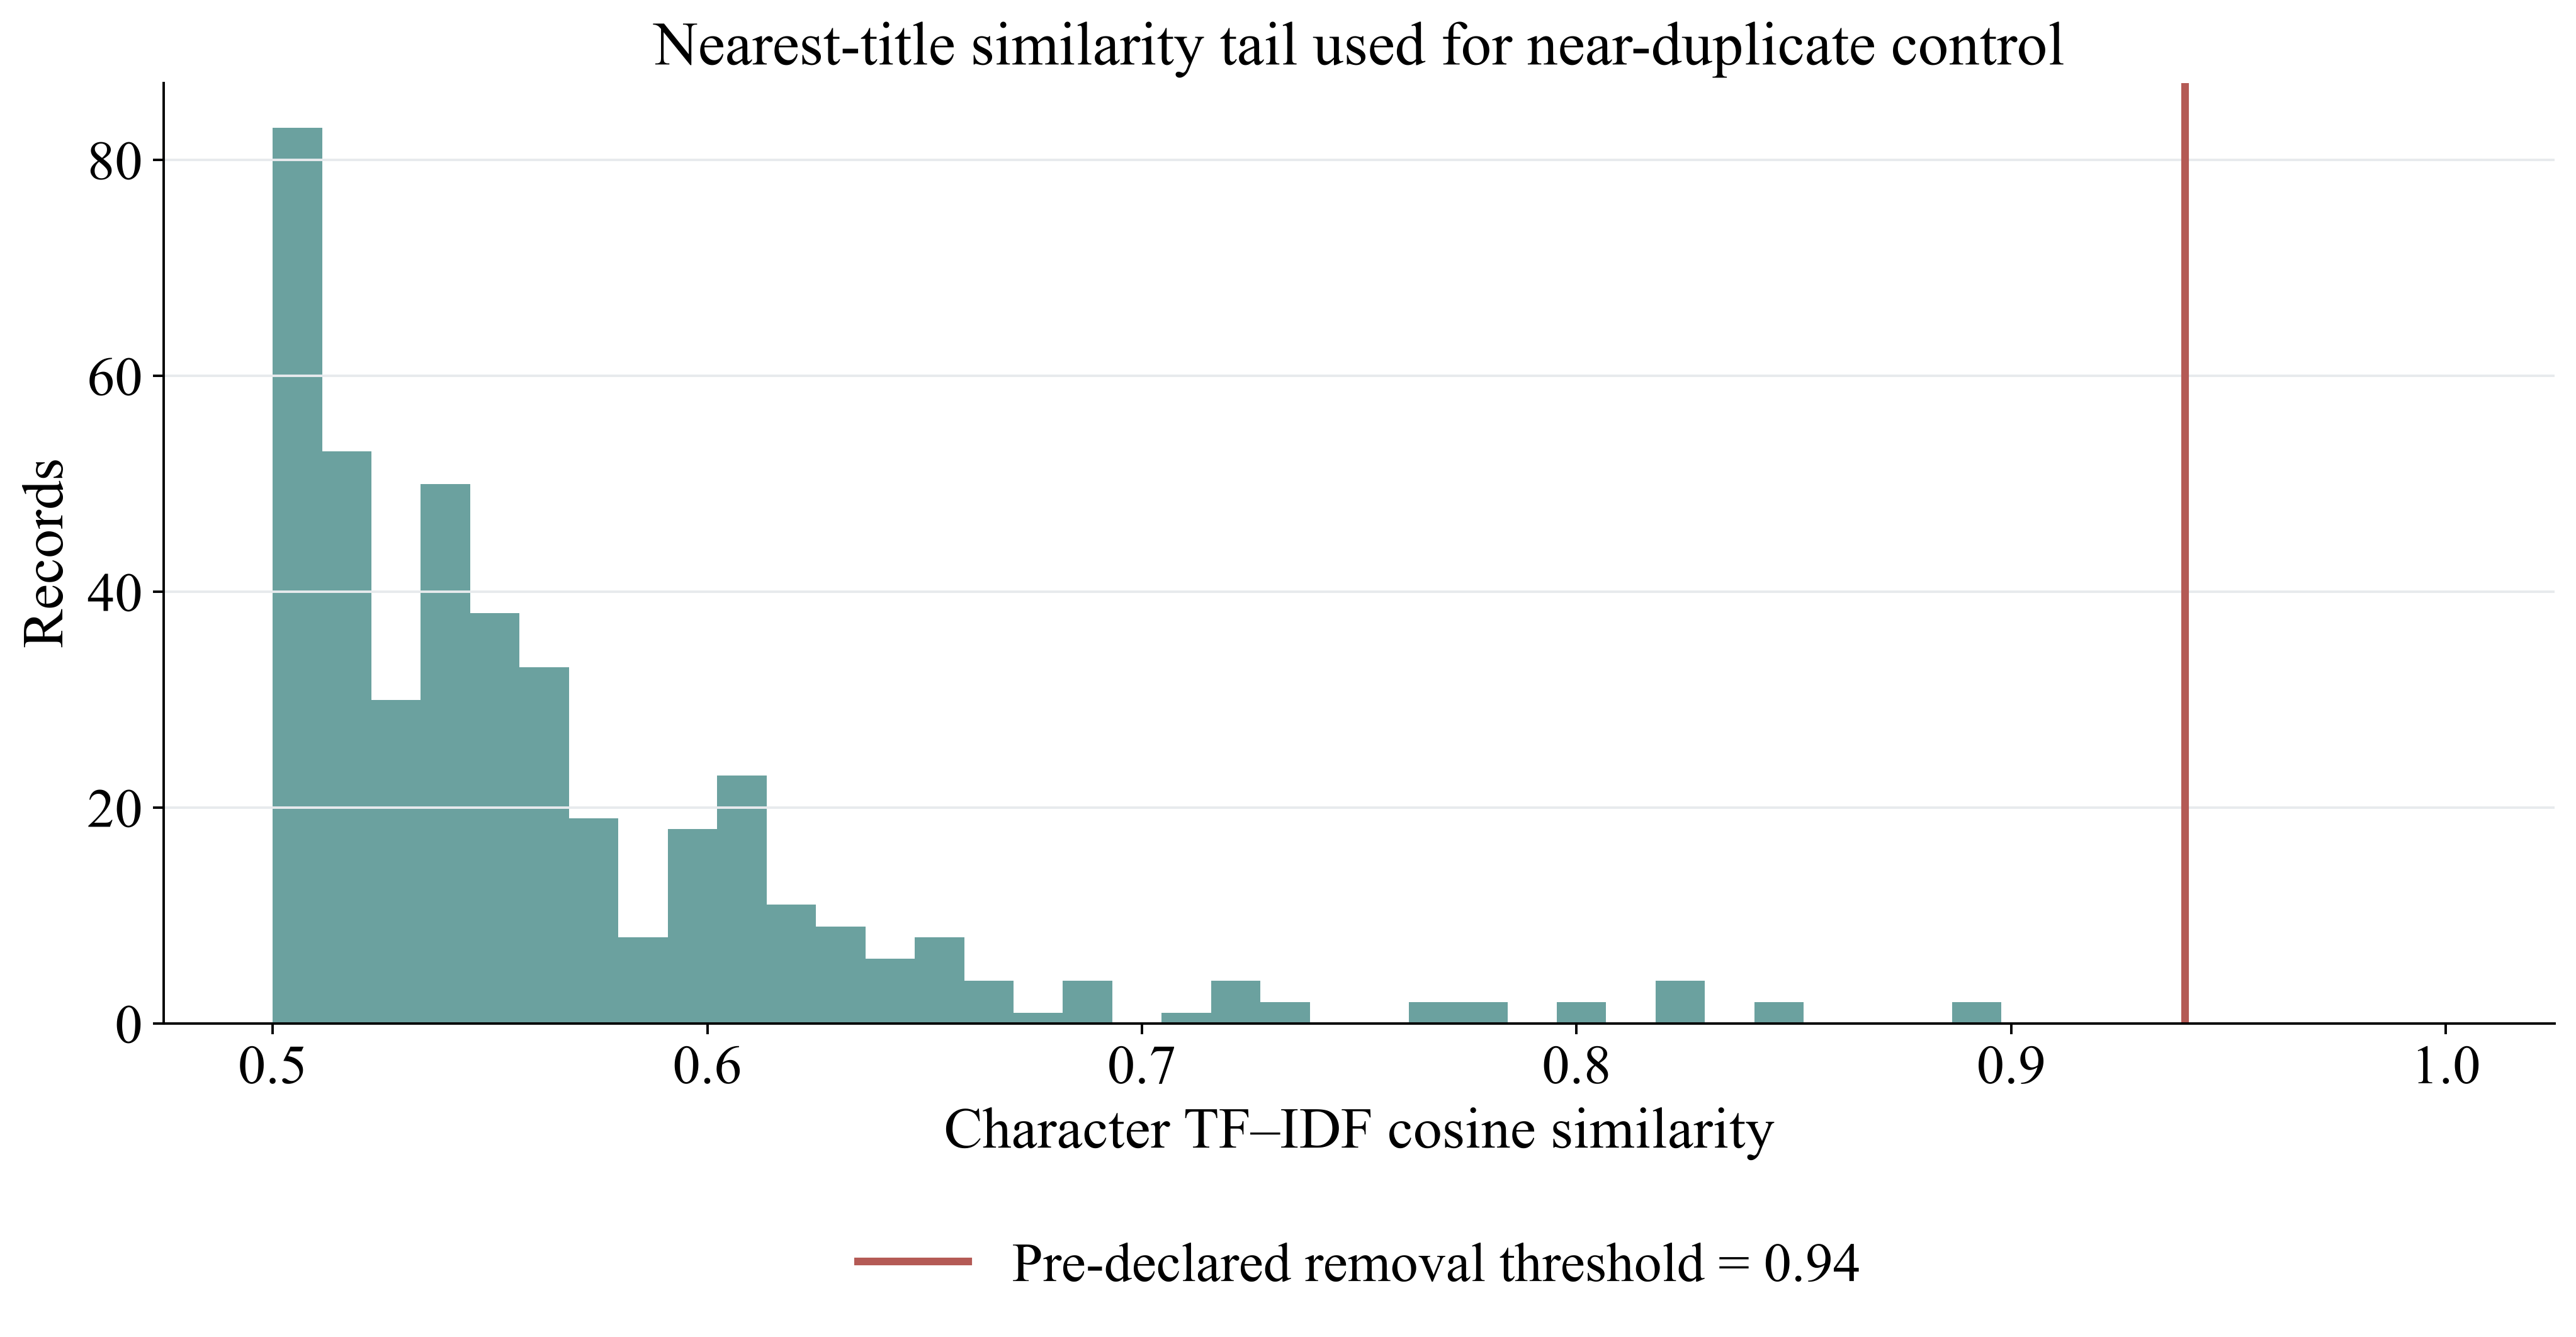

{'near_conflict_components_removed': 0, 'near_duplicate_rows_removed_or_collapsed': 0}


In [10]:
near_parent = np.arange(len(non_conflicting))


def near_find(index):
    while near_parent[index] != index:
        near_parent[index] = near_parent[near_parent[index]]
        index = near_parent[index]
    return int(index)


def near_union(left, right):
    left_root, right_root = near_find(left), near_find(right)
    if left_root != right_root:
        near_parent[right_root] = left_root


for row in near_pairs_df.itertuples(index=False):
    near_union(row.left, row.right)
non_conflicting["near_component"] = [near_find(index) for index in range(len(non_conflicting))]
near_stats = non_conflicting.groupby("near_component").agg(
    size=("sample_id", "size"), labels=("thematic_class", "nunique")
)
near_conflicts = near_stats.index[near_stats["labels"].gt(1)]
near_clean = non_conflicting[~non_conflicting["near_component"].isin(near_conflicts)].copy()
near_clean = near_clean.sort_values(
    ["near_component", "abstract_tokens"], ascending=[True, False]
).drop_duplicates("near_component", keep="first")

fig, ax = plt.subplots(figsize=(14, 7))
tail = 1 - distances[:, 1]
ax.hist(tail, bins=np.linspace(max(0.5, tail.min()), 1.0, 45), color=PALETTE["teal"], alpha=0.82)
ax.axvline(0.94, color=PALETTE["red"], linewidth=2.5, label="Pre-declared removal threshold = 0.94")
ax.set_title("Nearest-title similarity tail used for near-duplicate control")
ax.set_xlabel("Character TF–IDF cosine similarity")
ax.set_ylabel("Records")
ax.grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
fig.subplots_adjust(bottom=0.27)
plt.show()
print(
    {
        "near_conflict_components_removed": len(near_conflicts),
        "near_duplicate_rows_removed_or_collapsed": len(non_conflicting) - len(near_clean),
    }
)

### Scientific interpretation

The distribution shows the similarity tail used by the fixed 0.94 near-duplicate rule; values to the right are the highest-risk pairs. **Article-ready conclusion:** near-duplicate control was thresholded before model fitting. **Limitation:** cosine similarity is a screening proxy, not proof of identity.


## Temporal and source-aware split assignment

In [11]:
deduplicated = near_clean.copy()
deduplicated["publication_year"] = pd.to_numeric(deduplicated["publication_year"], errors="coerce")
deduplicated["split"] = ""
deduplicated["validation_domain"] = ""
development_openalex = deduplicated["cohort"].eq("development_2018_2024") & deduplicated[
    "source"
].eq("openalex")
deduplicated.loc[development_openalex & deduplicated["publication_year"].le(2022), "split"] = (
    "train"
)
deduplicated.loc[
    development_openalex & deduplicated["publication_year"].between(2023, 2024),
    ["split", "validation_domain"],
] = ["validation", "temporal_in_domain"]
deduplicated.loc[
    deduplicated["cohort"].eq("source_shift_validation"), ["split", "validation_domain"]
] = ["validation", "source_shift"]
deduplicated.loc[deduplicated["cohort"].eq("confirmatory_test_2025"), "split"] = "test"
deduplicated.loc[deduplicated["cohort"].eq("external_test_arxiv_hosted_2024_2025"), "split"] = (
    "external_test"
)
assert deduplicated["split"].ne("").all()
deduplicated = deduplicated.reset_index(drop=True)

label_encoder = LabelEncoder().fit(
    deduplicated.loc[deduplicated["split"].eq("train"), "thematic_class"]
)
deduplicated["label_id"] = label_encoder.transform(deduplicated["thematic_class"])
deduplicated["row_index"] = np.arange(len(deduplicated), dtype=np.int64)
joblib.dump(label_encoder, MODELS / "label_encoder.joblib")
print(deduplicated["split"].value_counts().sort_index().to_string())

split
external_test    1181
test             1914
train            3825
validation       2883


## Explicit leakage and source-overlap diagnostics

In [12]:
leakage_rows = []
for column in ["normalized_doi", "normalized_title", "abstract_sha256"]:
    for left, right in [
        ("train", "validation"),
        ("train", "test"),
        ("train", "external_test"),
        ("validation", "test"),
        ("validation", "external_test"),
        ("test", "external_test"),
    ]:
        left_values = set(deduplicated.loc[deduplicated["split"].eq(left), column].dropna()) - {""}
        right_values = set(deduplicated.loc[deduplicated["split"].eq(right), column].dropna()) - {
            ""
        }
        leakage_rows.append(
            {
                "check": column,
                "split_pair": f"{left}↔{right}",
                "violations": len(left_values & right_values),
            }
        )
leakage_check_df = pd.DataFrame(leakage_rows)
assert leakage_check_df["violations"].sum() == 0


def author_set(value):
    return {name.lower().strip() for name in json_list(value) if name}


train_authors = set().union(
    *deduplicated.loc[deduplicated["split"].eq("train"), "authors_json"].map(author_set)
)
test_authors = deduplicated.loc[deduplicated["split"].eq("test"), "authors_json"].map(author_set)
author_overlap_rate = test_authors.map(lambda values: bool(values & train_authors)).mean()
train_venues = set(
    deduplicated.loc[
        deduplicated["split"].eq("train") & deduplicated["source_name"].fillna("").ne(""),
        "source_name",
    ]
)
test_nonempty = deduplicated.loc[
    deduplicated["split"].eq("test") & deduplicated["source_name"].fillna("").ne(""), "source_name"
]
venue_overlap_rate = test_nonempty.isin(train_venues).mean()

overlap_summary = pd.DataFrame(
    [
        ("Exact cross-split duplicate violations", 0.0),
        ("Test author overlap with train", author_overlap_rate),
        ("Test venue overlap among non-empty venues", venue_overlap_rate),
    ],
    columns=["diagnostic", "rate"],
)
with pd.option_context("display.max_rows", None, "display.width", 150):
    display(overlap_summary)

,diagnostic,rate
0,Exact cross-split duplicate violations,0.000000
1,Test author overlap with train,0.129049
2,Test venue overlap among non-empty venues,0.422875


## Decomposed modeling-table inspection

In [13]:
deduplicated["author_count"] = deduplicated["authors_json"].map(json_list).str.len()
deduplicated["title_length"] = deduplicated["title_clean"].str.len()
deduplicated["abstract_length"] = deduplicated["abstract_clean"].str.len()
deduplicated["token_count"] = deduplicated["paper_text"].str.split().str.len()
deduplicated["keyword_count"] = deduplicated["reference_concepts"].str.len()
deduplicated["has_keywords"] = deduplicated["keyword_count"].gt(0)
deduplicated["cited_by_count"] = pd.to_numeric(
    deduplicated["cited_by_count"], errors="coerce"
).clip(lower=0)
deduplicated["citation_age"] = (2026 - deduplicated["publication_year"]).clip(lower=1)
deduplicated["citations_per_year"] = deduplicated["cited_by_count"] / deduplicated["citation_age"]
deduplicated["log_citations_per_year"] = np.log1p(deduplicated["citations_per_year"])
identity_view = deduplicated[
    ["row_index", "sample_id", "source", "split", "validation_domain", "thematic_class"]
].head(6)
text_view = deduplicated[
    ["sample_id", "title_length", "abstract_length", "token_count", "keyword_count", "has_keywords"]
].head(6)
metadata_view = deduplicated[
    [
        "sample_id",
        "publication_year",
        "author_count",
        "cited_by_count",
        "citations_per_year",
        "open_access",
    ]
].head(6)
with pd.option_context(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    48,
    "display.width",
    190,
):
    display(identity_view)
    display(text_view)
    display(metadata_view)

,row_index,sample_id,source,split,validation_domain,thematic_class
0,0,openalex:W3145648318,openalex,train,,Computer Science
1,1,openalex:W2514083242,openalex,train,,Computer Science
2,2,openalex:W4399540505,openalex,validation,temporal_in_domain,Computer Science
3,3,openalex:W4381739746,openalex,validation,temporal_in_domain,Computer Science
4,4,openalex:W4210418796,openalex,train,,Computer Science
5,5,openalex:W2995742292,openalex,train,,Computer Science


,sample_id,title_length,abstract_length,token_count,keyword_count,has_keywords
0,openalex:W3145648318,48,1257,215,13,True
1,openalex:W2514083242,88,1341,210,16,True
2,openalex:W4399540505,97,1313,189,12,True
3,openalex:W4381739746,148,950,159,21,True
4,openalex:W4210418796,79,540,88,16,True
5,openalex:W2995742292,127,1842,266,12,True


,sample_id,publication_year,author_count,cited_by_count,citations_per_year,open_access
0,openalex:W3145648318,2021,3,1.0,0.200000,True
1,openalex:W2514083242,2018,4,2.0,0.250000,True
2,openalex:W4399540505,2024,2,13.0,6.500000,True
3,openalex:W4381739746,2023,2,3.0,1.000000,False
4,openalex:W4210418796,2022,5,7.0,1.750000,True
5,openalex:W2995742292,2019,2,2.0,0.285714,True


## Zipf law with fitted tail slope

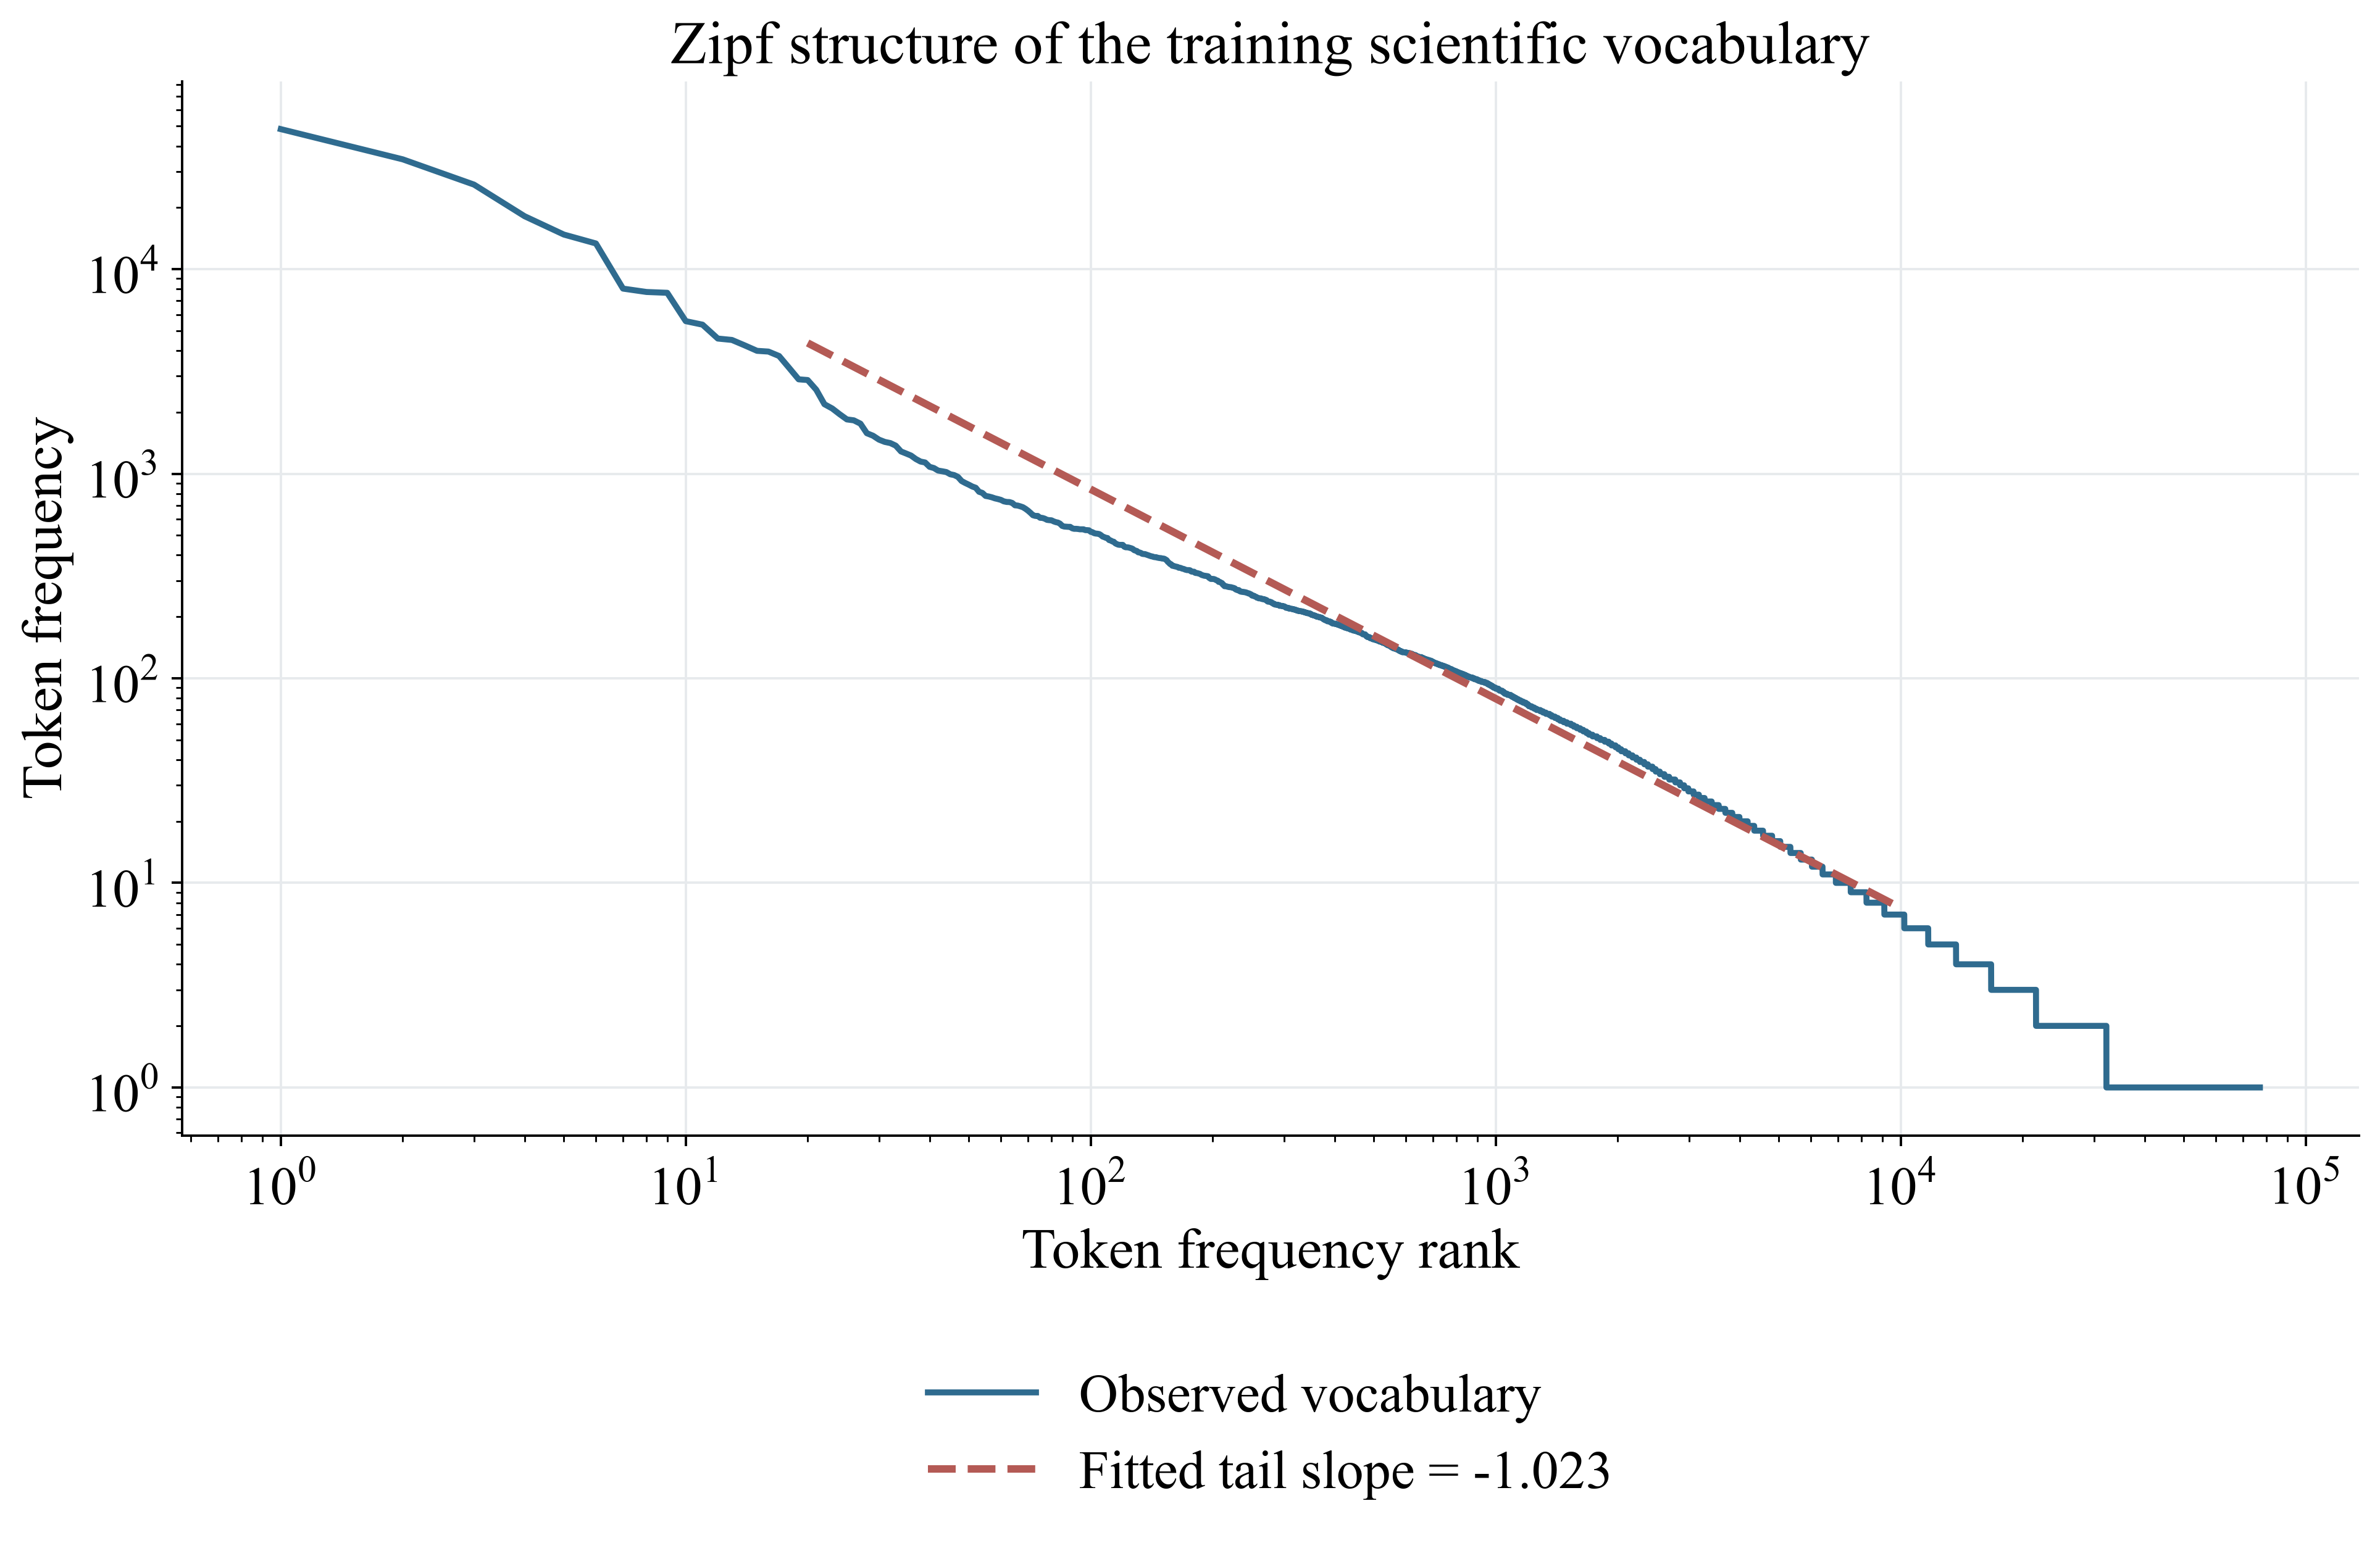

In [14]:
train_tokens = (
    " ".join(deduplicated.loc[deduplicated["split"].eq("train"), "paper_text"]).lower().split()
)
frequency = np.asarray(sorted(Counter(train_tokens).values(), reverse=True))
ranks = np.arange(1, len(frequency) + 1)
tail_mask = (ranks >= 20) & (ranks <= min(10000, len(ranks)))
zipf_slope, zipf_intercept = np.polyfit(
    np.log10(ranks[tail_mask]), np.log10(frequency[tail_mask]), 1
)
fig, ax = plt.subplots(figsize=(13, 8))
ax.loglog(ranks, frequency, color=PALETTE["blue"], linewidth=2, label="Observed vocabulary")
ax.loglog(
    ranks[tail_mask],
    10 ** (zipf_intercept + zipf_slope * np.log10(ranks[tail_mask])),
    color=PALETTE["red"],
    linestyle="--",
    linewidth=2.5,
    label=f"Fitted tail slope = {zipf_slope:.3f}",
)
ax.set_title("Zipf structure of the training scientific vocabulary")
ax.set_xlabel("Token frequency rank")
ax.set_ylabel("Token frequency")
ax.grid(color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
fig.subplots_adjust(bottom=0.27)
plt.show()

### Scientific interpretation

The log-log curve measures the rank-frequency structure of training vocabulary; the fitted slope is descriptive. **Article-ready conclusion:** the corpus exhibits a heavy-tailed scientific vocabulary consistent with sparse lexical modelling. **Limitation:** the slope depends on tokenization and the selected rank interval.


## Heaps law and bootstrap interval

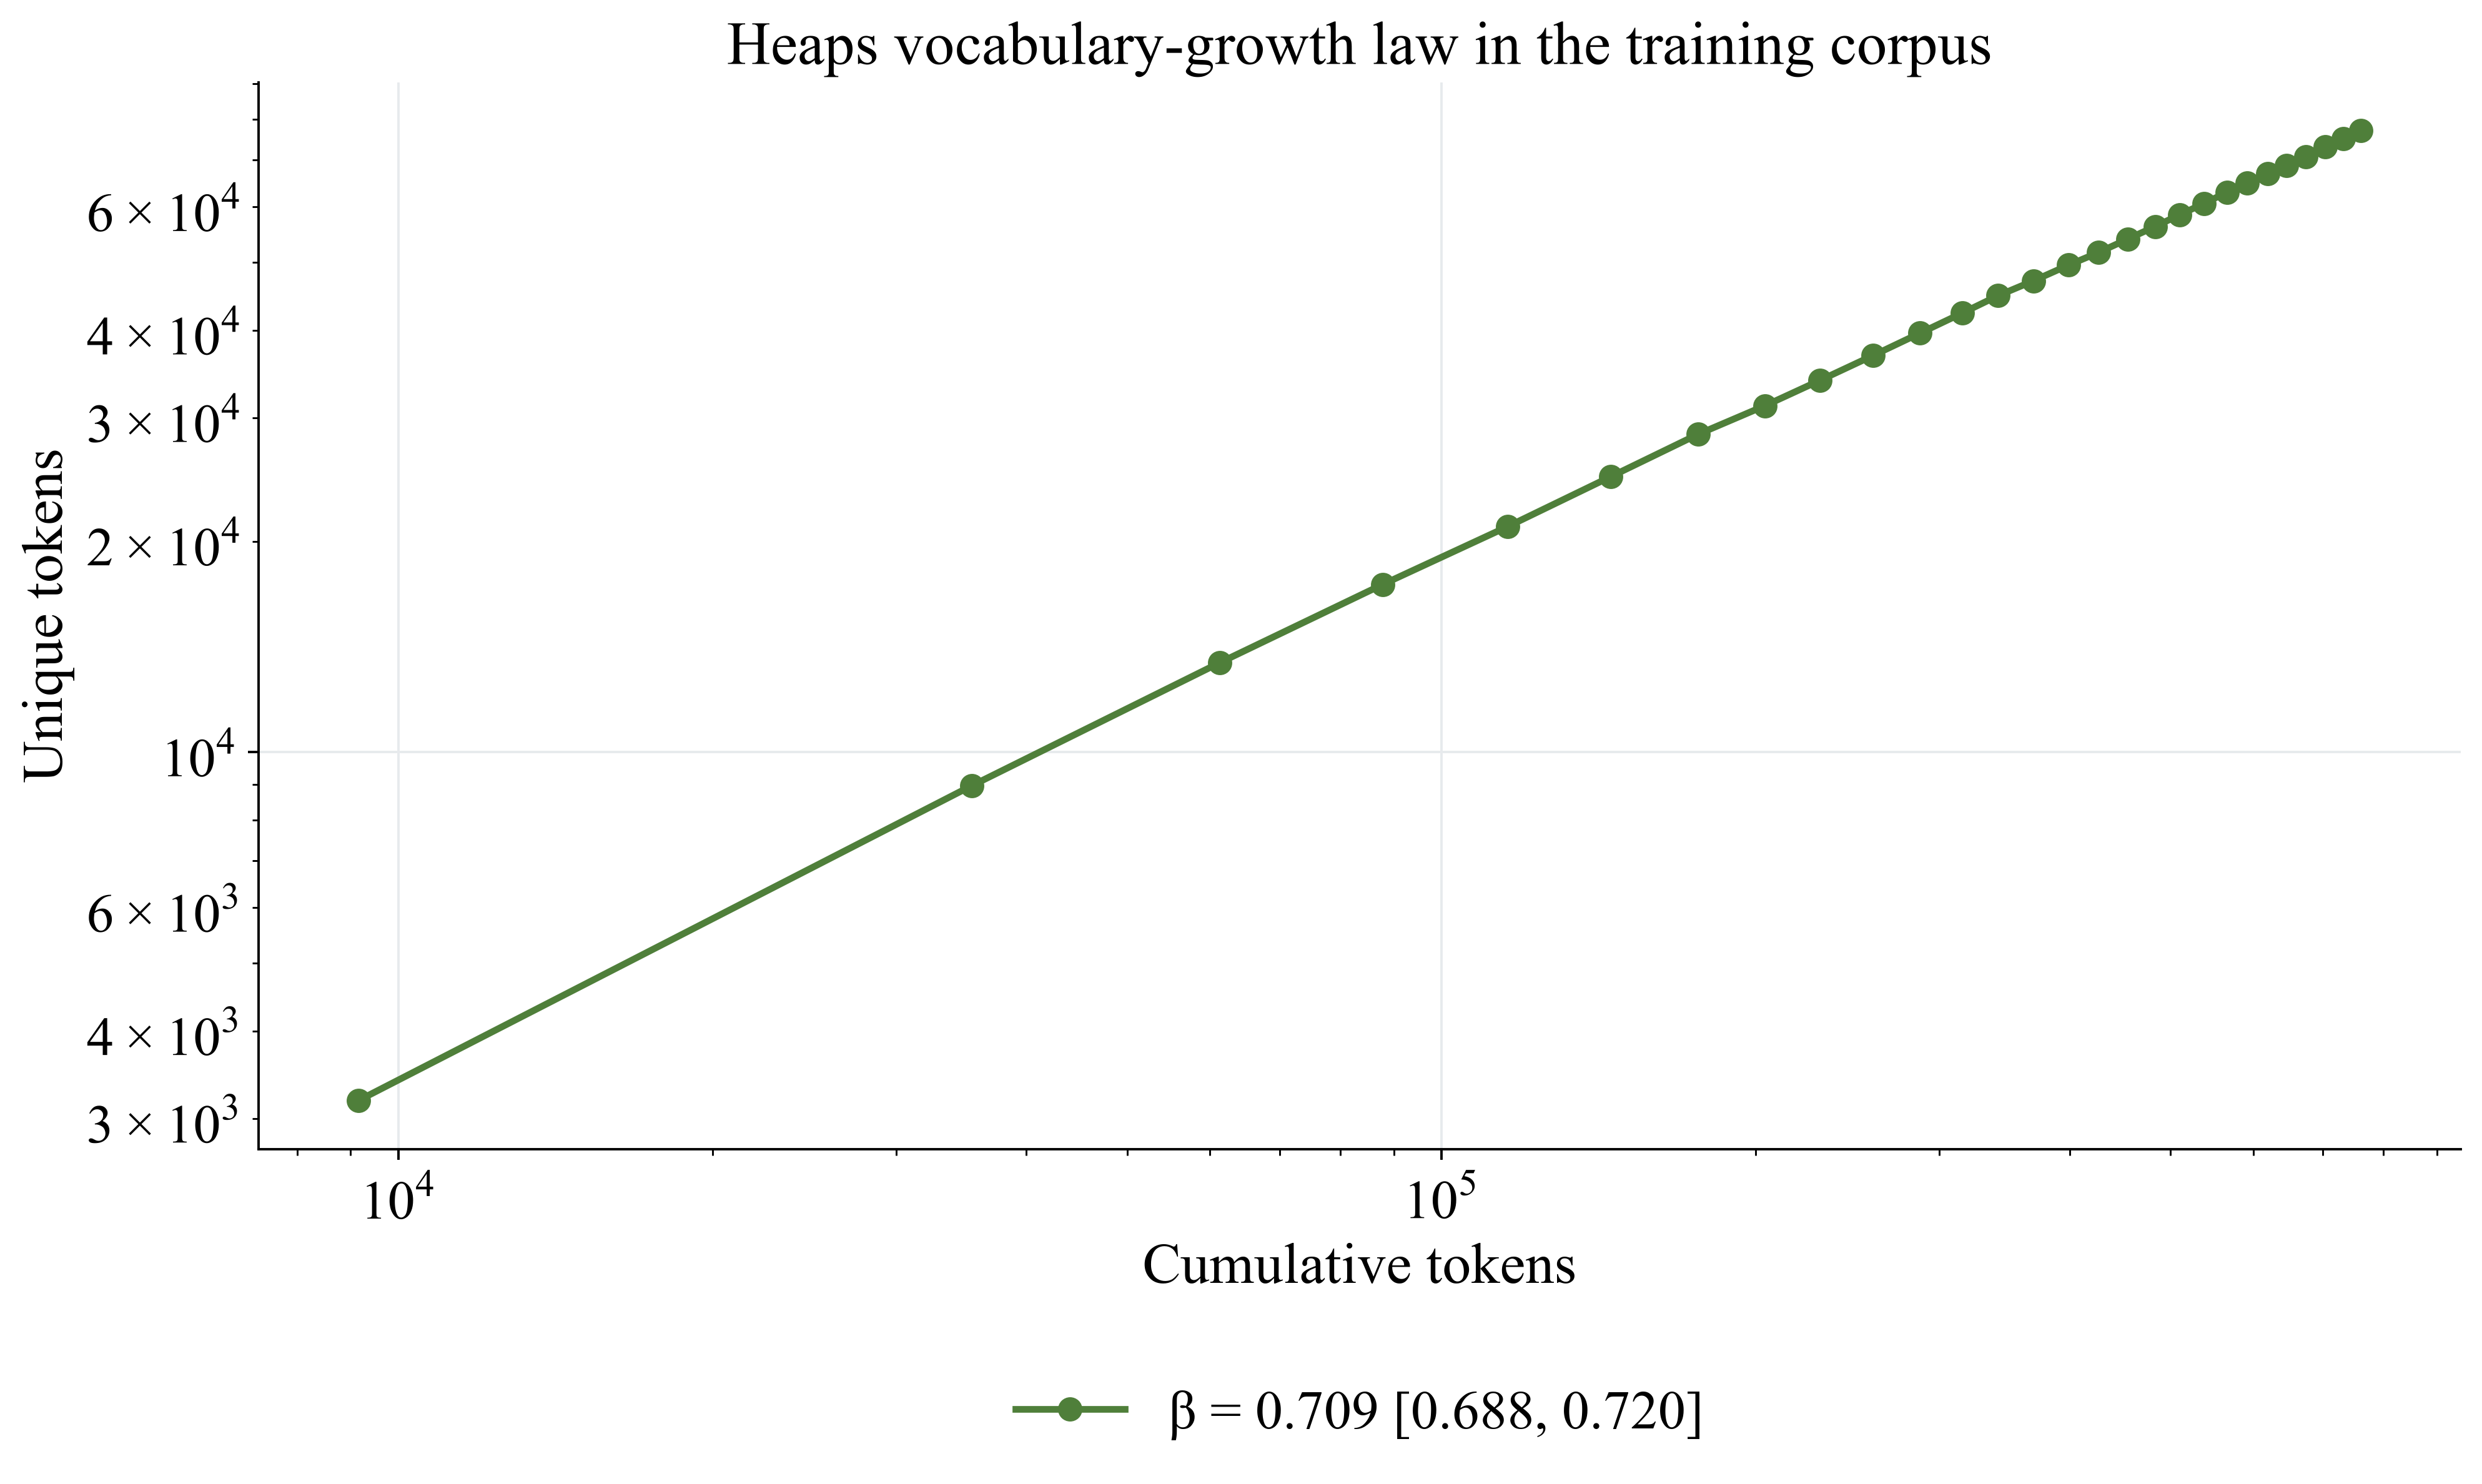

In [15]:
train_documents = deduplicated.loc[deduplicated["split"].eq("train"), "paper_text"].tolist()
sample_order = rng.permutation(len(train_documents))
checkpoints = np.unique(np.linspace(50, len(train_documents), 28).astype(int))
cumulative_tokens, vocabulary_sizes = [], []
vocabulary, token_total = set(), 0
for index, doc_index in enumerate(sample_order, start=1):
    tokens = train_documents[doc_index].lower().split()
    vocabulary.update(tokens)
    token_total += len(tokens)
    if index in checkpoints:
        cumulative_tokens.append(token_total)
        vocabulary_sizes.append(len(vocabulary))
heaps_beta, heaps_intercept = np.polyfit(np.log(cumulative_tokens), np.log(vocabulary_sizes), 1)
bootstrap_beta = []
for _ in range(300):
    selected = rng.choice(len(cumulative_tokens), len(cumulative_tokens), replace=True)
    bootstrap_beta.append(
        np.polyfit(
            np.log(np.asarray(cumulative_tokens)[selected]),
            np.log(np.asarray(vocabulary_sizes)[selected]),
            1,
        )[0]
    )
beta_low, beta_high = np.quantile(bootstrap_beta, [0.025, 0.975])
fig, ax = plt.subplots(figsize=(13, 8))
ax.loglog(
    cumulative_tokens,
    vocabulary_sizes,
    "o-",
    color=PALETTE["green"],
    linewidth=2.2,
    markersize=7,
    label=f"β = {heaps_beta:.3f} [{beta_low:.3f}, {beta_high:.3f}]",
)
ax.set_title("Heaps vocabulary-growth law in the training corpus")
ax.set_xlabel("Cumulative tokens")
ax.set_ylabel("Unique tokens")
ax.grid(color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
fig.subplots_adjust(bottom=0.27)
plt.show()

### Scientific interpretation

The curve measures vocabulary growth with cumulative training tokens; the bootstrap interval describes resampling variability within this corpus. **Article-ready conclusion:** vocabulary continues to expand sublinearly as documents accumulate. **Limitation:** this is not an external confidence interval for all scientific literature.


## Age-normalized citation heavy tail

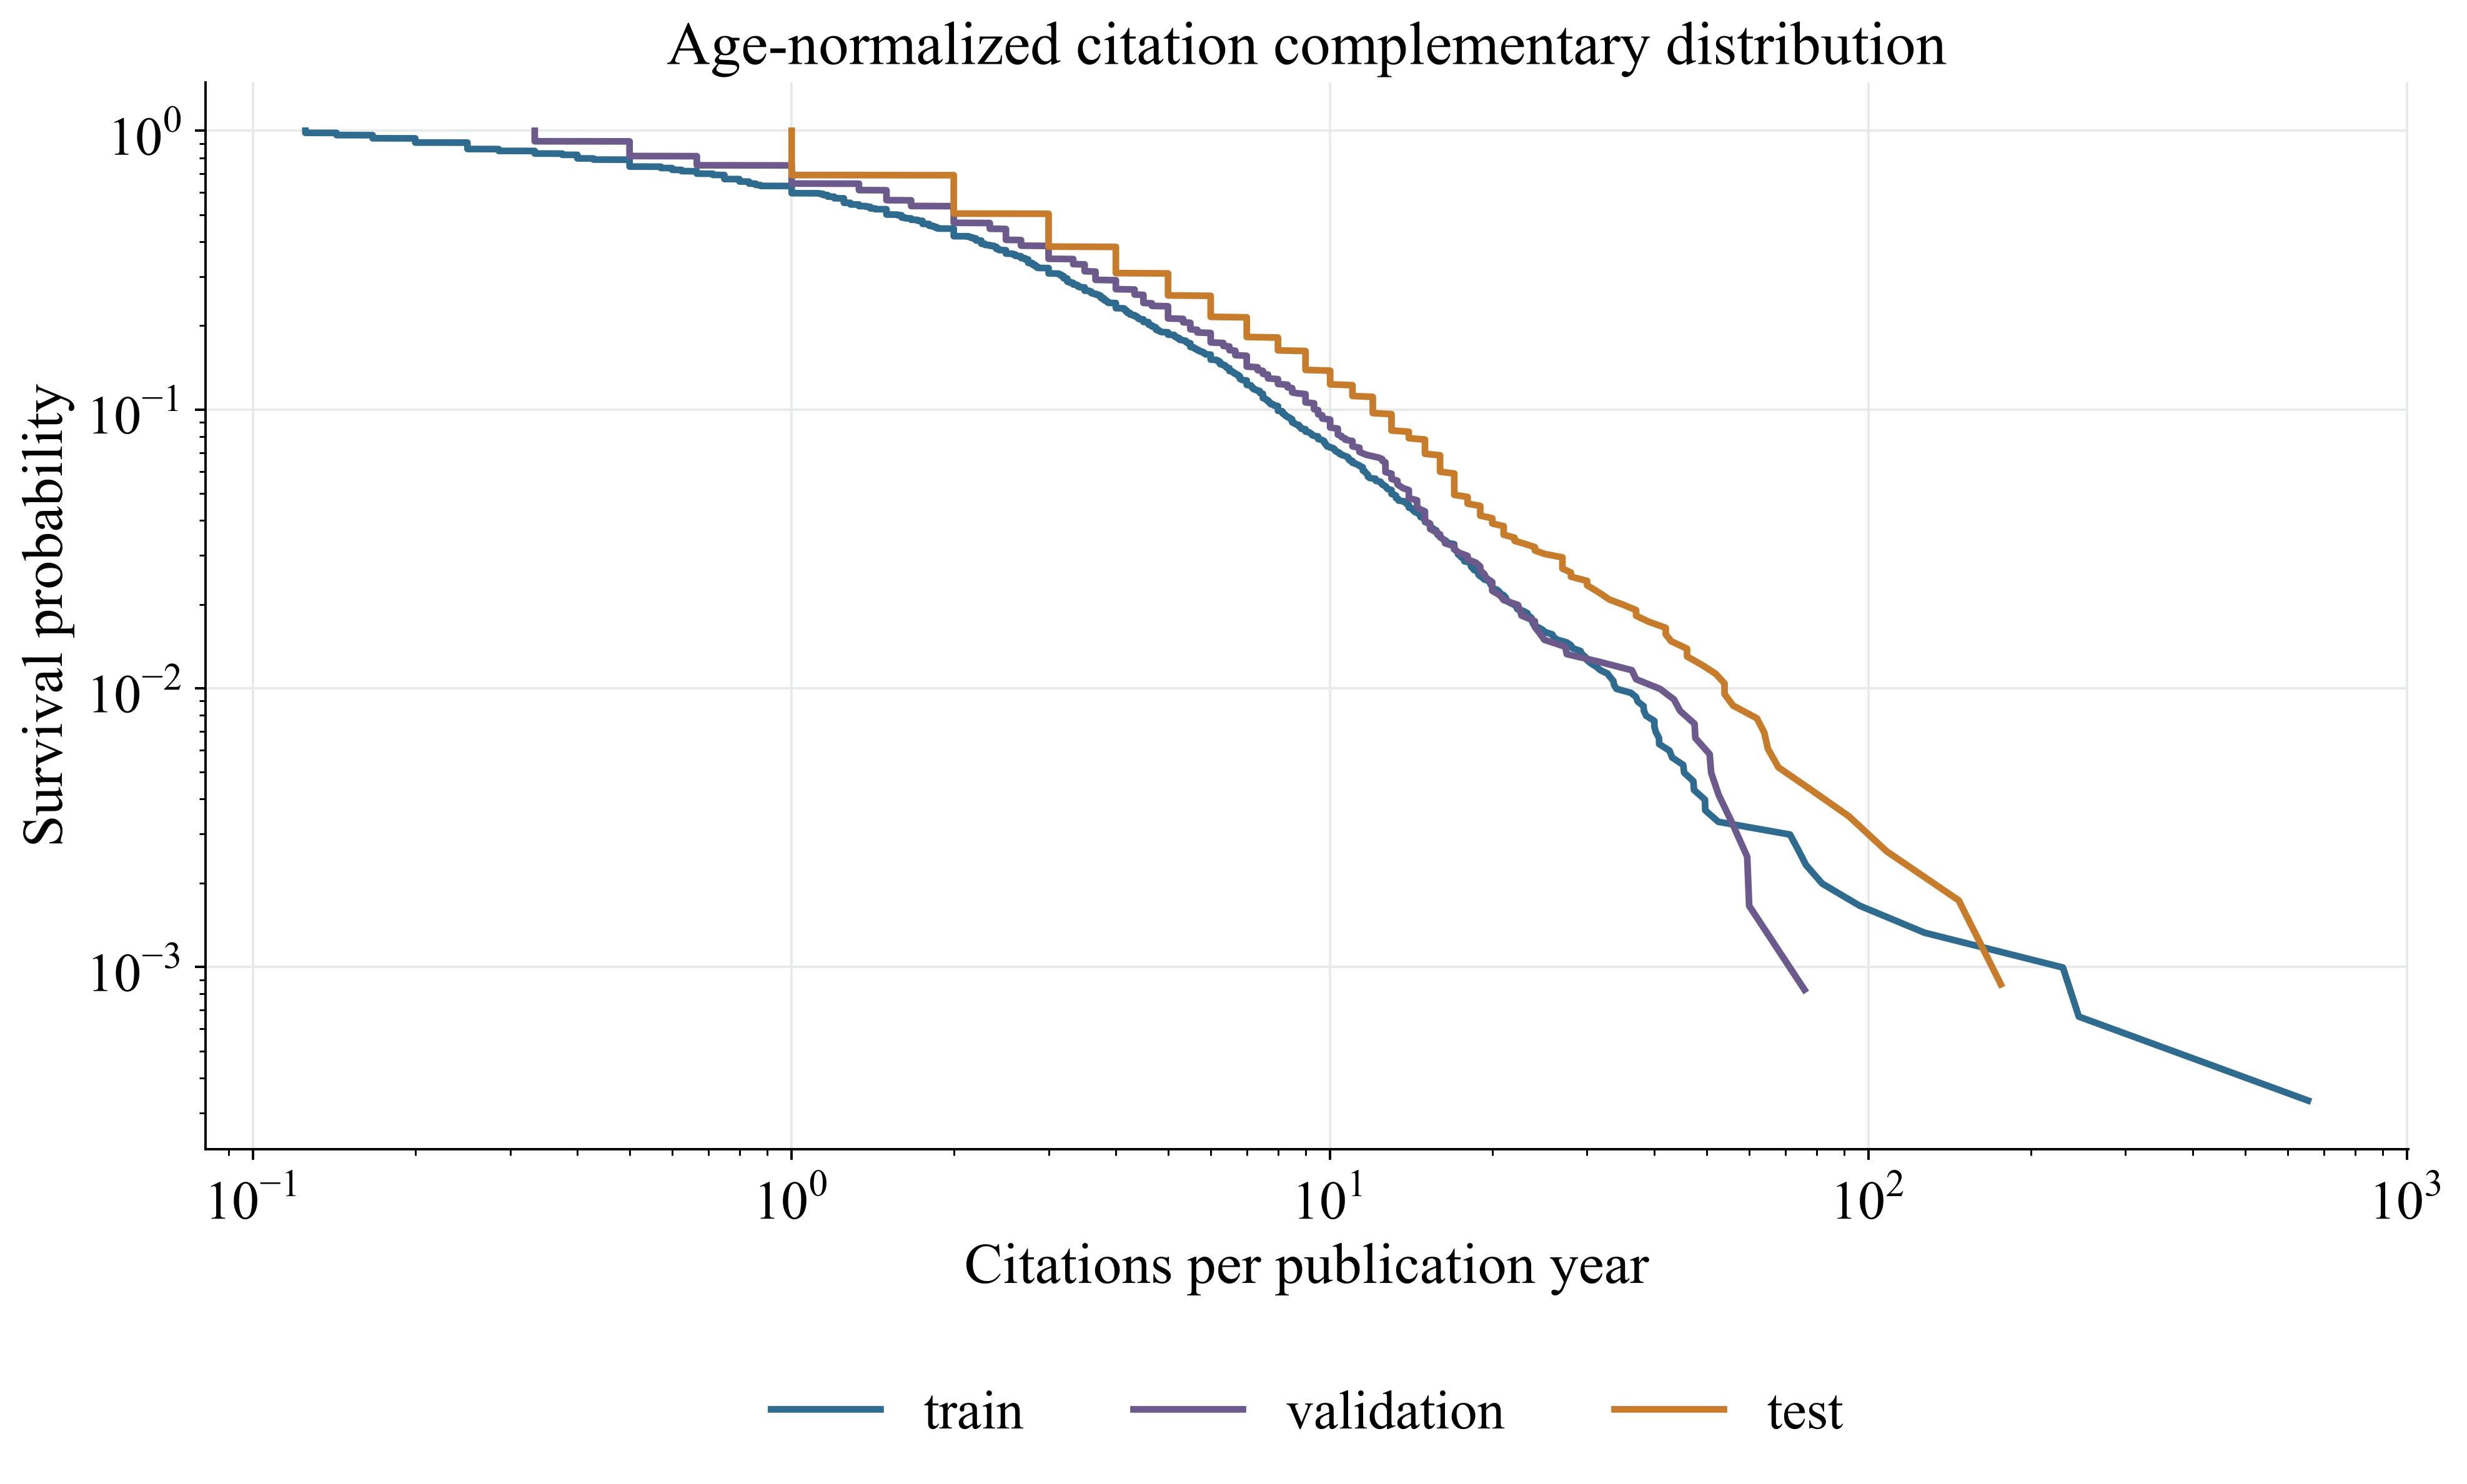

In [16]:
fig, ax = plt.subplots(figsize=(13, 8))
for split_name, color in [
    ("train", PALETTE["blue"]),
    ("validation", PALETTE["purple"]),
    ("test", PALETTE["orange"]),
]:
    values = (
        deduplicated.loc[deduplicated["split"].eq(split_name), "citations_per_year"]
        .dropna()
        .to_numpy()
    )
    positive = np.sort(values[values > 0])
    if len(positive):
        survival = 1 - np.arange(1, len(positive) + 1) / (len(positive) + 1)
        ax.loglog(positive, survival, color=color, linewidth=2.2, label=split_name)
ax.set_title("Age-normalized citation complementary distribution")
ax.set_xlabel("Citations per publication year")
ax.set_ylabel("Survival probability")
ax.grid(color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
fig.subplots_adjust(bottom=0.27)
plt.show()

### Scientific interpretation

The survival curves compare age-normalized citation tails across declared splits. **Article-ready conclusion:** citation distributions are heavy-tailed and split differences remain a possible covariate shift. **Limitation:** citations are field- and age-dependent observational metadata.


## Missingness co-occurrence as φ-correlation

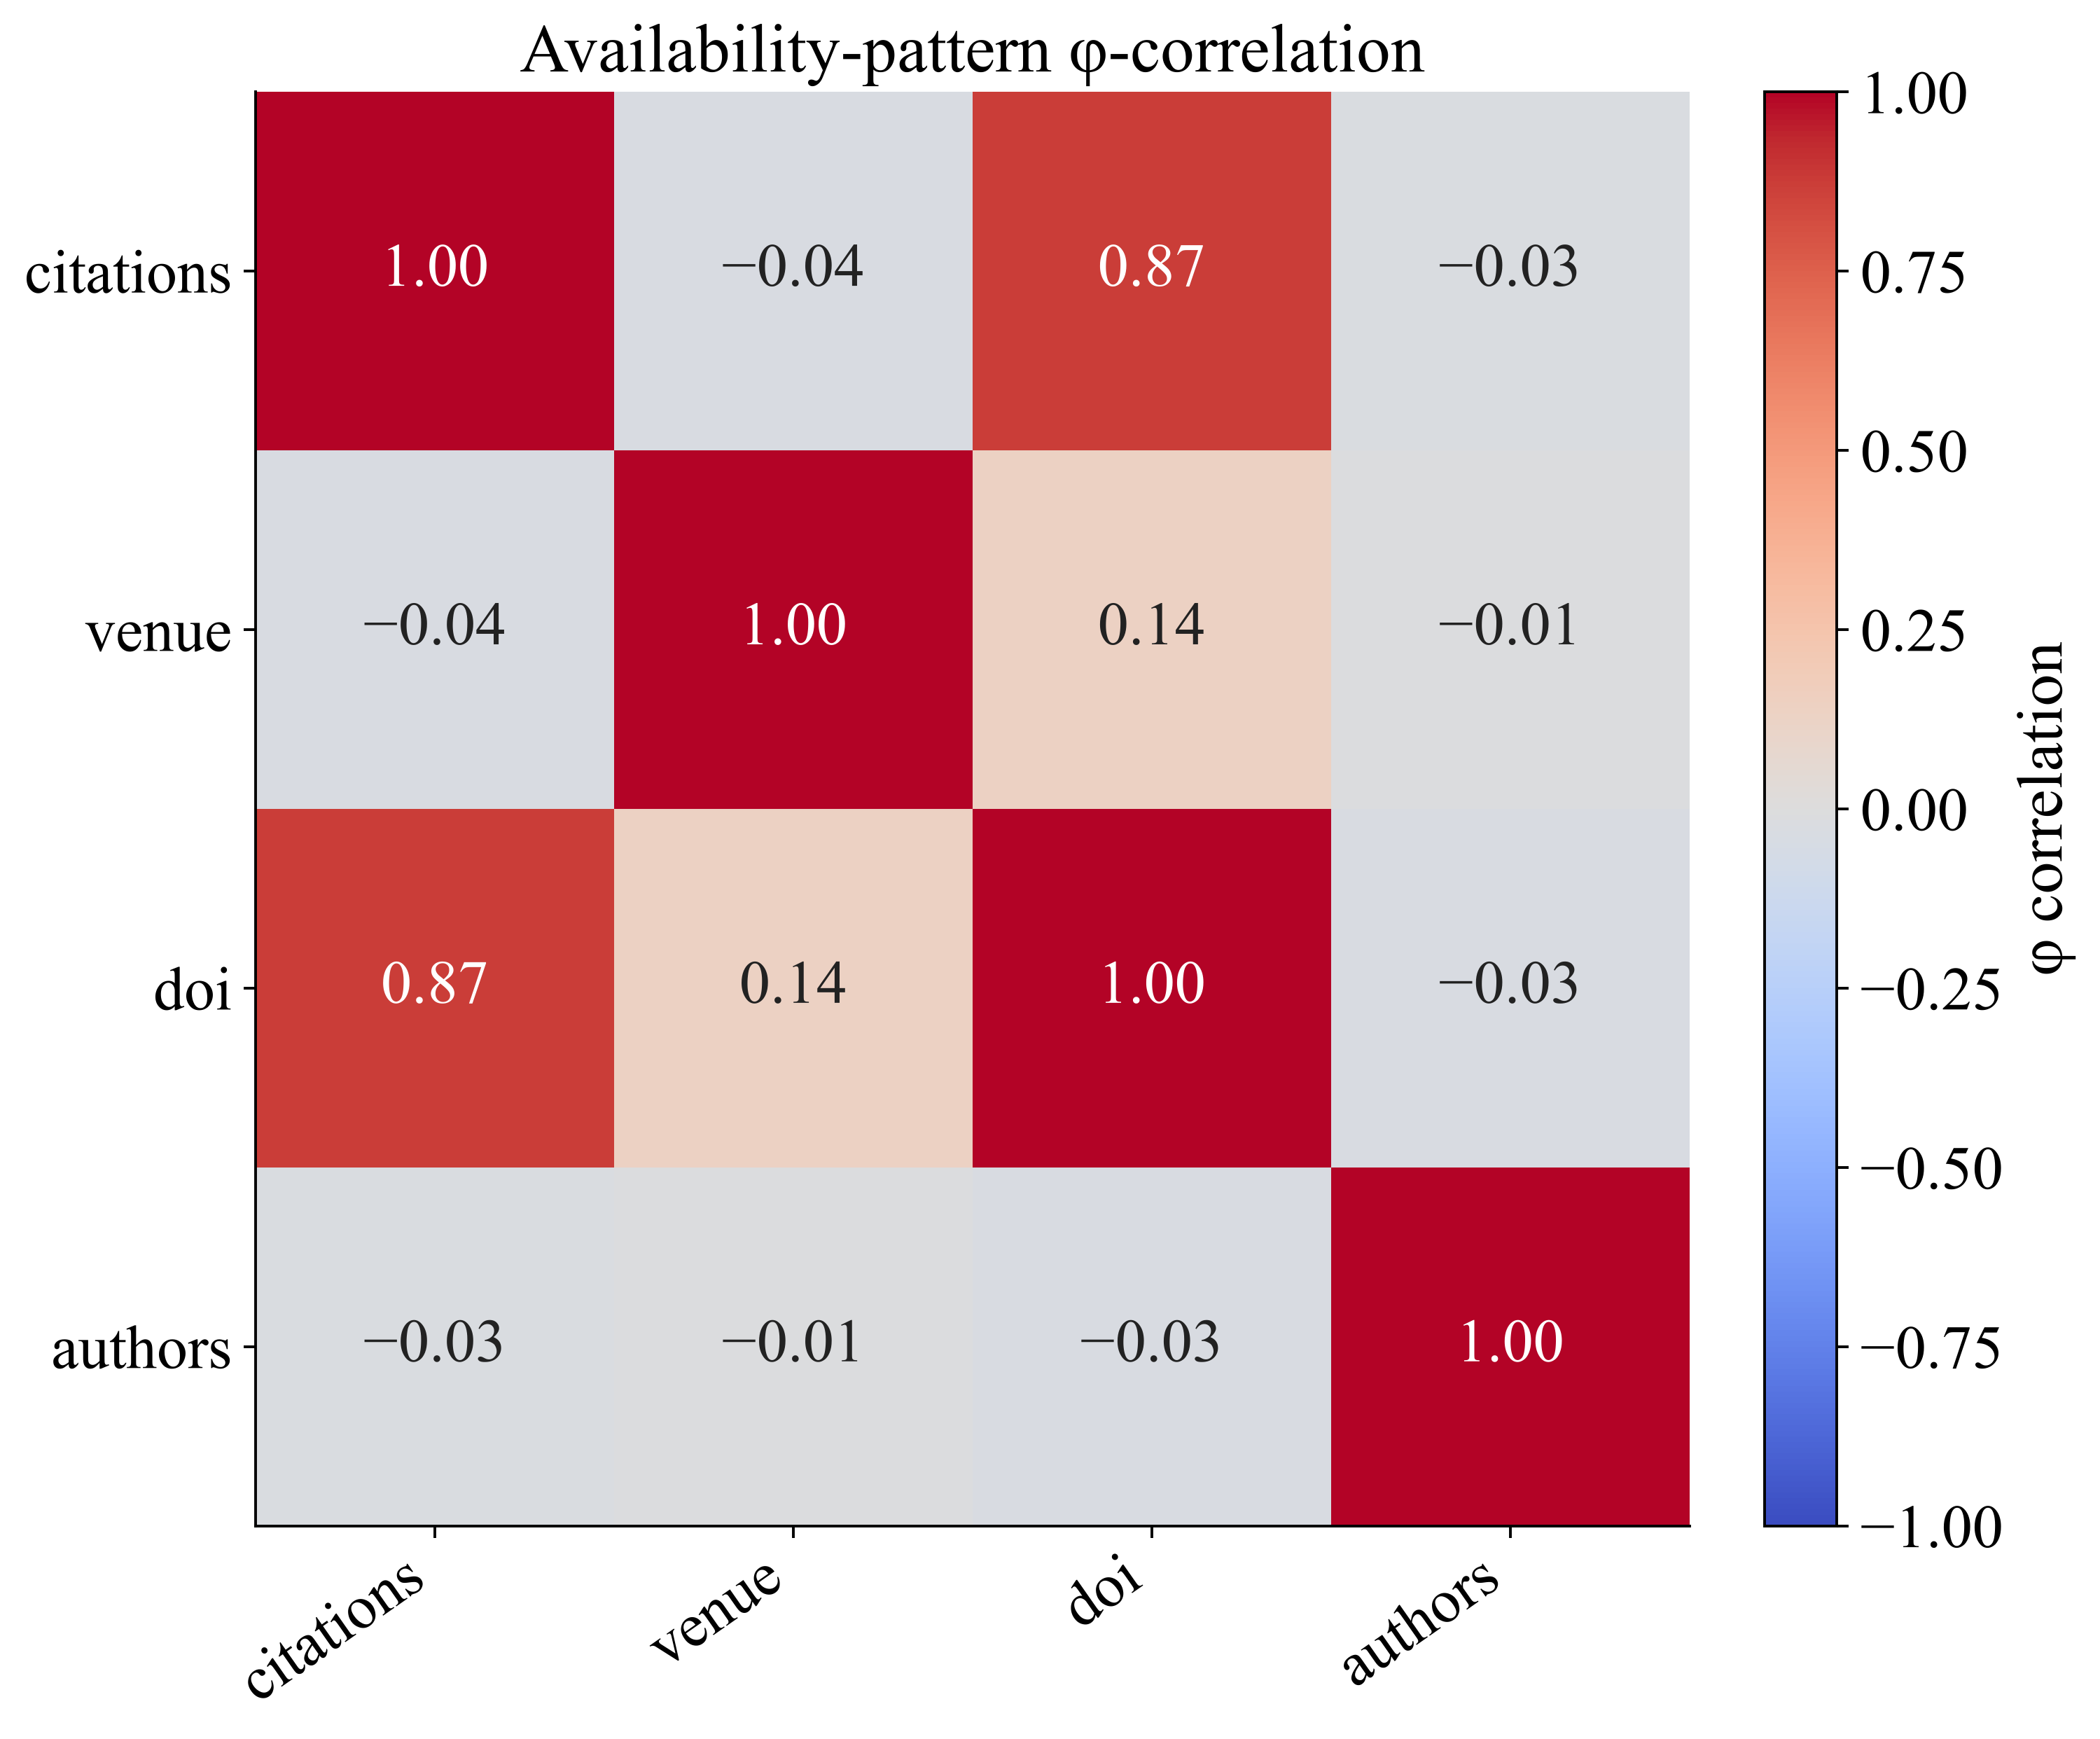

Constant availability indicators excluded from φ estimation: abstract, keywords. Their correlation is undefined, not missing data.


In [17]:
availability = pd.DataFrame(
    {
        "abstract": deduplicated["abstract_clean"].ne(""),
        "keywords": deduplicated["has_keywords"],
        "citations": deduplicated["cited_by_count"].notna(),
        "venue": deduplicated["source_name"].fillna("").ne(""),
        "doi": deduplicated["normalized_doi"].ne(""),
        "authors": deduplicated["author_count"].gt(0),
    }
).astype(int)
constant_fields = availability.columns[availability.nunique(dropna=False).le(1)].tolist()
variable_availability = availability.drop(columns=constant_fields)
phi = variable_availability.corr()
assert np.isfinite(phi.to_numpy()).all(), "Undefined φ values remain after constant-field exclusion"
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(phi, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Availability-pattern φ-correlation")
ax.set_xticks(range(len(phi)), phi.columns, rotation=35, ha="right")
ax.set_yticks(range(len(phi)), phi.index)
for i in range(len(phi)):
    for j in range(len(phi)):
        value = phi.iloc[i, j]
        label = f"{value:.2f}".replace("-", "−")
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            j,
            i,
            label,
            ha="center",
            va="center",
            fontsize=18,
            color="white" if luminance < 0.48 else PALETTE["black"],
        )
colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.04)
colorbar.set_label("φ correlation")
fig.subplots_adjust(bottom=0.23, left=0.20)
plt.show()
print(
    f"Constant availability indicators excluded from φ estimation: "
    f"{', '.join(constant_fields)}. Their correlation is undefined, not missing data."
)

### Scientific interpretation

The heatmap measures association between variable metadata-availability indicators; absolute values nearer one indicate stronger co-occurrence. **Article-ready conclusion:** missingness channels are not assumed independent. **Limitation:** constant indicators are correctly excluded because their correlation is undefined.


## Text-length distribution without clipping

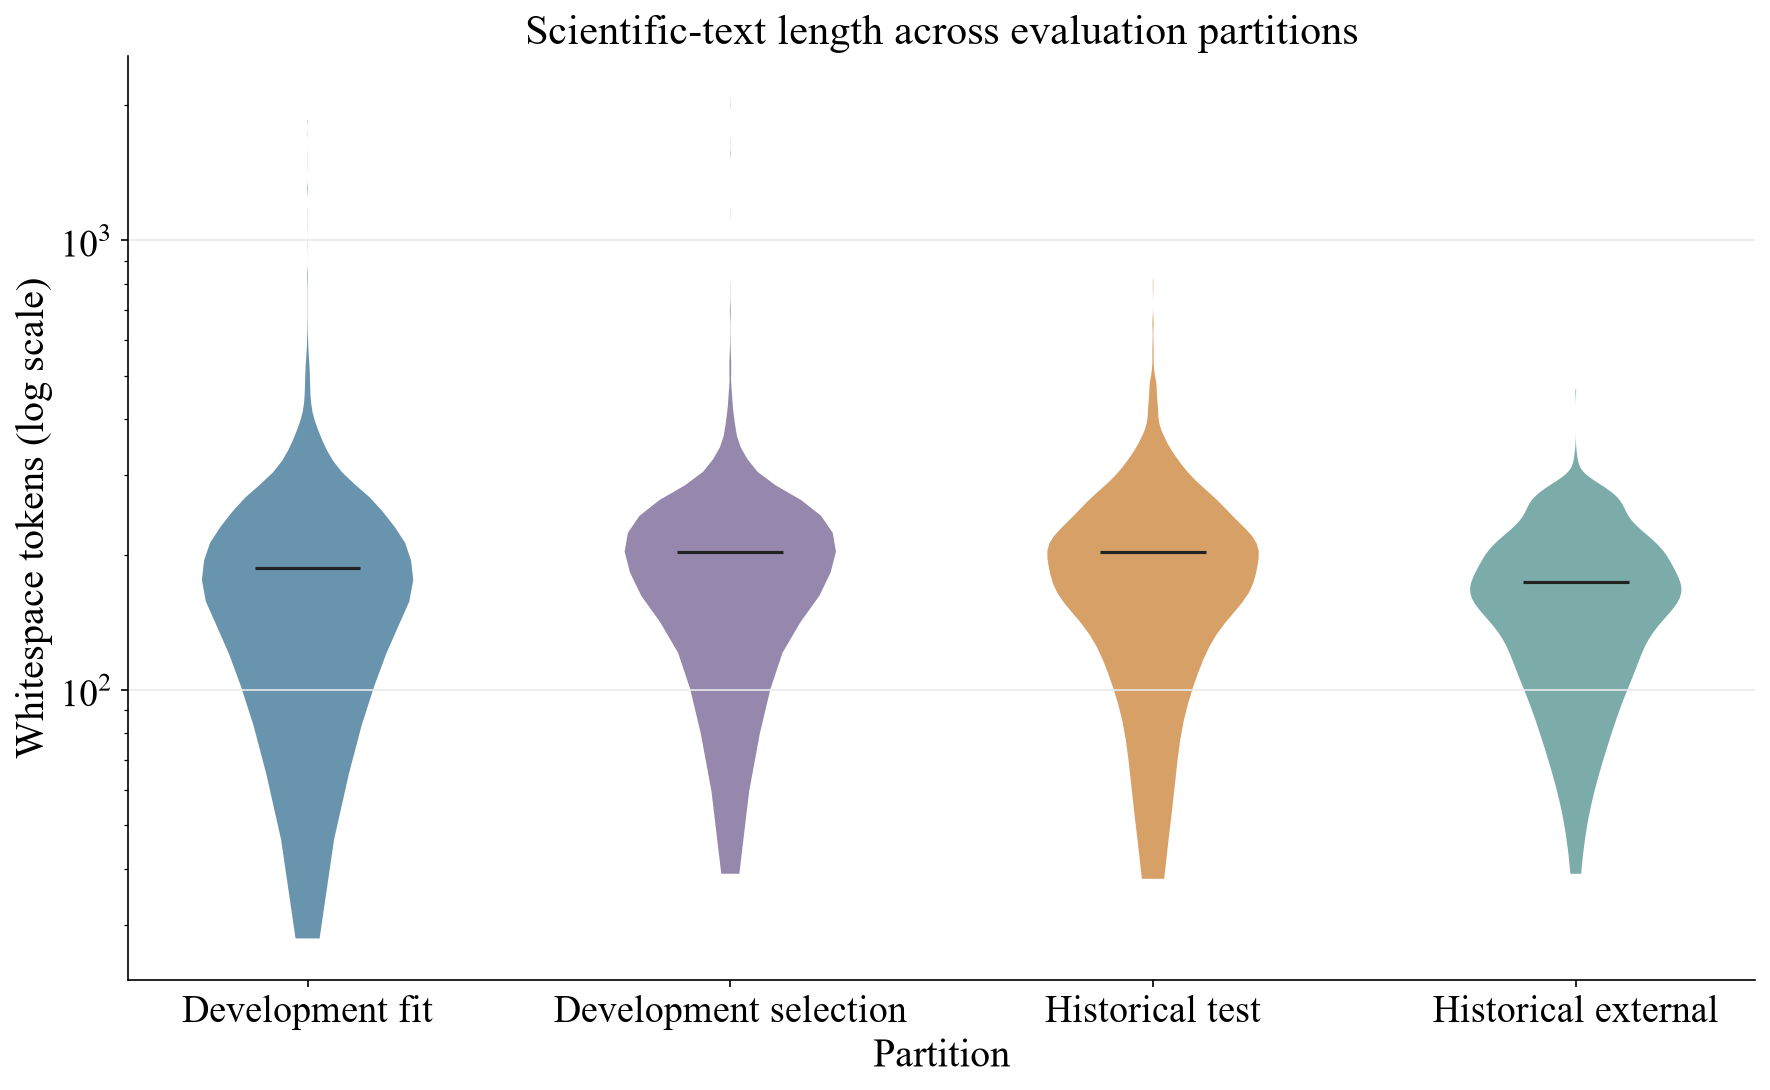

In [18]:
groups = []
labels = []
for split_name in ["train", "validation", "test", "external_test"]:
    values = deduplicated.loc[deduplicated["split"].eq(split_name), "token_count"].to_numpy()
    if len(values):
        groups.append(values)
        labels.append(
            {
                'train': 'Development fit',
                'validation': 'Development selection',
                'test': 'Historical test',
                'external_test': 'Historical external',
            }[split_name]
        )
fig, ax = plt.subplots(figsize=(14, 8))
parts = ax.violinplot(groups, showmedians=True, showextrema=False)
for body, color in zip(
    parts["bodies"], [PALETTE["blue"], PALETTE["purple"], PALETTE["orange"], PALETTE["teal"]]
):
    body.set_facecolor(color)
    body.set_alpha(0.72)
parts["cmedians"].set_color(PALETTE["black"])
ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_yscale("log")
ax.set_title("Scientific-text length across evaluation partitions")
ax.set_xlabel("Partition")
ax.set_ylabel("Whitespace tokens (log scale)")
ax.grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
plt.show()

### Scientific interpretation

The violins compare text-length distributions across splits. **Article-ready conclusion:** length variation is visible and is retained as a documented distributional property. **Limitation:** overlap in distributions does not prove absence of other shifts.


## Split representativeness by class Jensen–Shannon distance

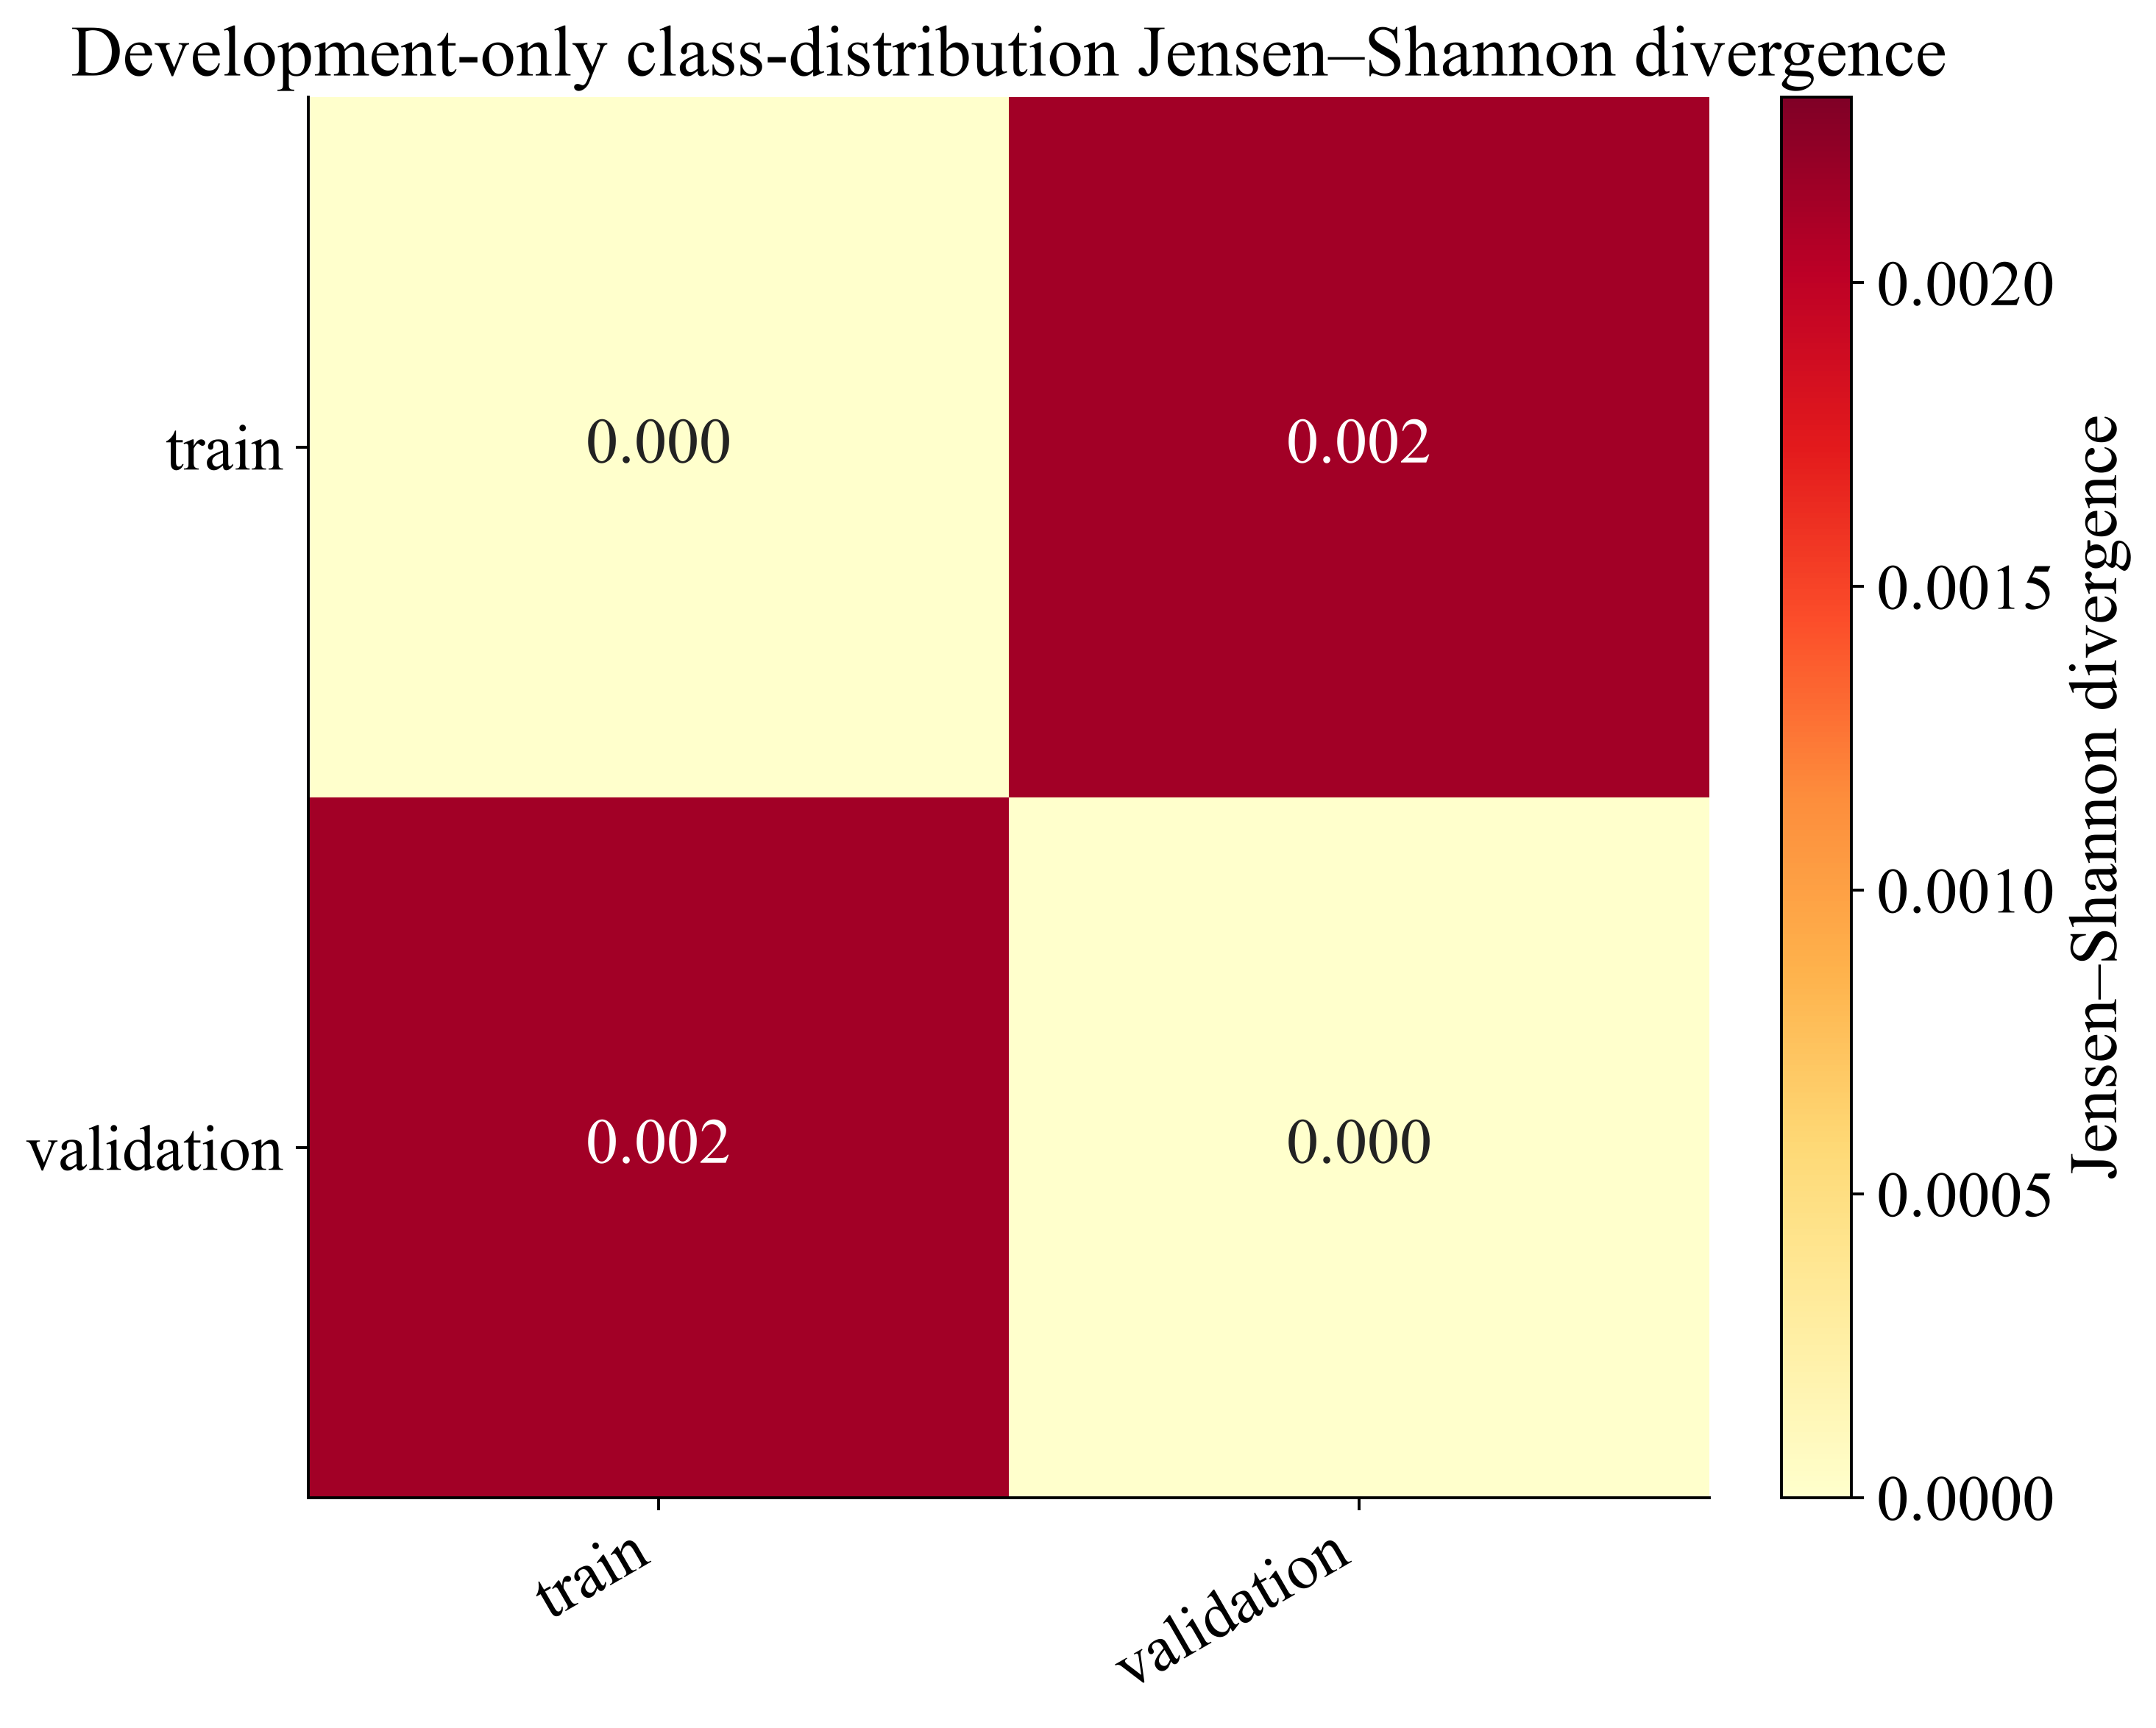

In [19]:
split_order = ["train", "validation"]
class_order = list(label_encoder.classes_)
class_distributions = []
for split_name in split_order:
    counts = (
        deduplicated.loc[deduplicated["split"].eq(split_name), "thematic_class"]
        .value_counts()
        .reindex(class_order, fill_value=0)
        .to_numpy(dtype=float)
    )
    class_distributions.append(counts / counts.sum())
n_splits = len(split_order)
js_matrix = np.zeros((n_splits, n_splits))
for i in range(n_splits):
    for j in range(n_splits):
        js_matrix[i, j] = jensenshannon(class_distributions[i], class_distributions[j]) ** 2
fig, ax = plt.subplots(figsize=(10, 8))
off_diagonal = js_matrix[~np.eye(n_splits, dtype=bool)]
js_vmax = max(0.001, float(off_diagonal.max()) * 1.08)
image = ax.imshow(js_matrix, cmap="YlOrRd", vmin=0, vmax=js_vmax)
ax.set_title("Development-only class-distribution Jensen–Shannon divergence")
ax.set_xticks(range(n_splits), split_order, rotation=30, ha="right")
ax.set_yticks(range(n_splits), split_order)
for i in range(n_splits):
    for j in range(n_splits):
        value = js_matrix[i, j]
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=18,
            color="white" if luminance < 0.48 else PALETTE["black"],
        )
fig.colorbar(image, ax=ax, fraction=0.045, pad=0.04, label="Jensen–Shannon divergence")
fig.subplots_adjust(bottom=0.20, left=0.20)
plt.show()

### Scientific interpretation

This output verifies leakage-sensitive group separation. **Article-ready conclusion:** linked author/institution components are kept within folds, reducing identity leakage. **Limitation:** unobserved affiliations or entity-resolution errors may remain.


## Training-only lexical drift analysis

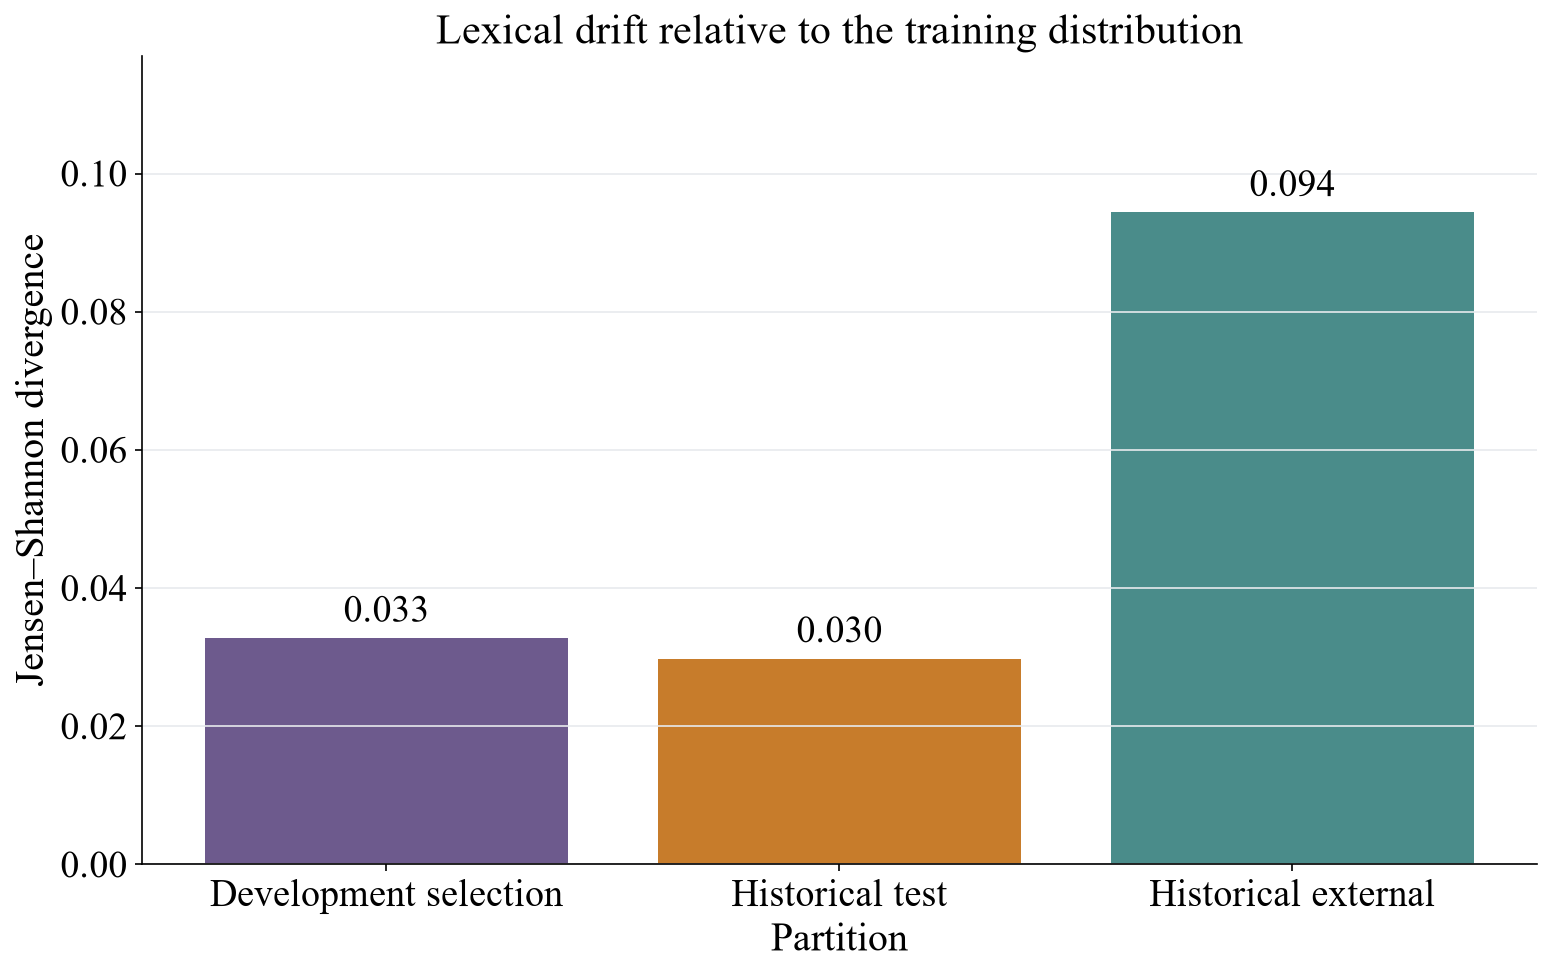

In [20]:
drift_vectorizer = CountVectorizer(max_features=12000, min_df=4, stop_words="english")
train_counts = (
    drift_vectorizer.fit_transform(
        deduplicated.loc[deduplicated["split"].eq("train"), "paper_text"]
    )
    .sum(axis=0)
    .A1
    + 0.5
)
train_distribution = train_counts / train_counts.sum()
drift_rows = []
for split_name in ["validation", "test", "external_test"]:
    counts = (
        drift_vectorizer.transform(
            deduplicated.loc[deduplicated["split"].eq(split_name), "paper_text"]
        )
        .sum(axis=0)
        .A1
        + 0.5
    )
    distribution = counts / counts.sum()
    drift_rows.append((split_name, jensenshannon(train_distribution, distribution) ** 2))
drift_df = pd.DataFrame(drift_rows, columns=["split", "js_divergence"])
fig, ax = plt.subplots(figsize=(12, 7))
colors = [PALETTE["purple"], PALETTE["orange"], PALETTE["teal"]]
drift_df['display_split'] = drift_df['split'].map(
    {
        'validation': 'Development selection',
        'test': 'Historical test',
        'external_test': 'Historical external',
    }
)
bars = ax.bar(drift_df['display_split'], drift_df['js_divergence'], color=colors)
ax.set_title("Lexical drift relative to the training distribution")
ax.set_xlabel("Partition")
ax.set_ylabel("Jensen–Shannon divergence")
ax.grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
ax.set_ylim(0, drift_df["js_divergence"].max() * 1.24)
for bar, value in zip(bars, drift_df["js_divergence"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + drift_df["js_divergence"].max() * 0.025,
        f"{value:.3f}",
        ha="center",
        fontsize=18,
    )
plt.show()

### Scientific interpretation

This audit reports the deterministic split ledger and class counts. **Article-ready conclusion:** each publication has one declared role and the development-validation boundary is explicit. **Limitation:** historically exposed test cohorts are excluded from confirmation.


## Primary and enriched lexical feature groups

In [21]:
train_mask = deduplicated["split"].eq("train").to_numpy()
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=50000,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32,
)
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=4,
    max_features=20000,
    sublinear_tf=True,
    dtype=np.float32,
)
word_vectorizer.fit(deduplicated.loc[train_mask, "paper_text"])
char_vectorizer.fit(deduplicated.loc[train_mask, "paper_text"])
word_matrix = word_vectorizer.transform(deduplicated["paper_text"])
char_matrix = char_vectorizer.transform(deduplicated["paper_text"])
text_statistics = deduplicated[
    ["title_length", "abstract_length", "token_count", "author_count"]
].astype(np.float32)
text_scaler = StandardScaler().fit(text_statistics.loc[train_mask])
scaled_statistics = text_scaler.transform(text_statistics).astype(np.float32)
lexical_matrix = sparse.hstack(
    [word_matrix, char_matrix, sparse.csr_matrix(scaled_statistics)], format="csr", dtype=np.float32
)
sparse.save_npz(DATASET / "unified/lexical_features.npz", lexical_matrix)
joblib.dump(word_vectorizer, MODELS / "word_tfidf.joblib")
joblib.dump(char_vectorizer, MODELS / "char_tfidf.joblib")
joblib.dump(text_scaler, MODELS / "lexical_statistics_scaler.joblib")
lexical_components = pd.DataFrame(
    [
        ("word n-grams", word_matrix.shape[1], word_matrix.nnz),
        ("character n-grams", char_matrix.shape[1], char_matrix.nnz),
        ("scaled text statistics", scaled_statistics.shape[1], scaled_statistics.size),
    ],
    columns=["component", "dimensions", "nonzero_values"],
)
display(lexical_components)

,component,dimensions,nonzero_values
0,word n-grams,45112,1718618
1,character n-grams,20000,13543615
2,scaled text statistics,4,39212


In [22]:
enriched_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=60000,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32,
)
enriched_vectorizer.fit(deduplicated.loc[train_mask, "paper_text_enriched"])
enriched_lexical_matrix = (
    enriched_vectorizer.transform(deduplicated["paper_text_enriched"]).tocsr().astype(np.float32)
)
sparse.save_npz(DATASET / "unified/lexical_features_enriched.npz", enriched_lexical_matrix)
joblib.dump(enriched_vectorizer, MODELS / "enriched_tfidf.joblib")
print(
    {
        "enriched_dimensions": enriched_lexical_matrix.shape[1],
        "training_keyword_coverage": float(deduplicated.loc[train_mask, "has_keywords"].mean()),
    }
)

{'enriched_dimensions': 47954, 'training_keyword_coverage': 1.0}


## Stable primary metadata and matched enriched metadata

In [23]:
primary_numeric = [
    "publication_year",
    "log_citations_per_year",
    "author_count",
    "open_access",
    "title_length",
    "abstract_length",
    "token_count",
]
primary_frame = deduplicated[primary_numeric].copy()
primary_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
primary_pipeline.fit(primary_frame.loc[train_mask])
metadata_primary = sparse.csr_matrix(primary_pipeline.transform(primary_frame), dtype=np.float32)
sparse.save_npz(DATASET / "unified/metadata_matrix_primary.npz", metadata_primary)
joblib.dump(primary_pipeline, MODELS / "metadata_primary.joblib")

enriched_categorical = ["source_type", "work_type", "language"]
enriched_transformer = ColumnTransformer(
    [
        ("numeric", primary_pipeline, primary_numeric),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", min_frequency=5, dtype=np.float32),
            enriched_categorical,
        ),
    ],
    sparse_threshold=1.0,
)
enriched_transformer.fit(deduplicated.loc[train_mask, primary_numeric + enriched_categorical])
metadata_enriched = sparse.csr_matrix(
    enriched_transformer.transform(deduplicated[primary_numeric + enriched_categorical]),
    dtype=np.float32,
)
sparse.save_npz(DATASET / "unified/metadata_matrix_enriched.npz", metadata_enriched)
joblib.dump(enriched_transformer, MODELS / "metadata_enriched.joblib")
display(
    pd.DataFrame(
        [
            ("primary stable numeric", metadata_primary.shape[1], False),
            ("enriched matched-input", metadata_enriched.shape[1], True),
        ],
        columns=["metadata_track", "dimensions", "includes_type_categories"],
    )
)

,metadata_track,dimensions,includes_type_categories
0,primary stable numeric,7,False
1,enriched matched-input,14,True


## Title-and-abstract concept candidates and keyword supervision

In [24]:
phrase_vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.97,
    max_features=30000,
    stop_words="english",
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32,
)
phrase_vectorizer.fit(deduplicated.loc[train_mask, "paper_text"])
phrase_matrix = phrase_vectorizer.transform(deduplicated["paper_text"])
phrase_names = phrase_vectorizer.get_feature_names_out()


def top_terms(row, limit=20):
    if row.nnz == 0:
        return []
    order = np.argsort(row.data)[::-1][:limit]
    return [str(phrase_names[row.indices[position]]) for position in order]


deduplicated["concept_candidates"] = [
    top_terms(phrase_matrix.getrow(index), 20) for index in range(len(deduplicated))
]
deduplicated["concept_candidates_json"] = deduplicated["concept_candidates"].map(
    lambda values: json.dumps(values, ensure_ascii=False)
)
deduplicated["reference_concepts_json"] = deduplicated["reference_concepts"].map(
    lambda values: json.dumps(values, ensure_ascii=False)
)
concept_matrix = phrase_matrix.tocsr().astype(np.float32)
sparse.save_npz(DATASET / "unified/concept_matrix.npz", concept_matrix)
joblib.dump(phrase_vectorizer, MODELS / "concept_tfidf.joblib")
concept_frame = deduplicated[
    [
        "row_index",
        "sample_id",
        "split",
        "concept_candidates_json",
        "reference_concepts_json",
        "keyword_count",
    ]
].copy()
concept_frame.to_parquet(DATASET / "unified/concept_features.parquet", index=False)
with pd.option_context("display.max_colwidth", None, "display.width", 190):
    display(
        concept_frame[["sample_id", "concept_candidates_json", "reference_concepts_json"]].head(4)
    )

,sample_id,concept_candidates_json,reference_concepts_json
0,openalex:W3145648318,"[""agricultural"", ""farmers"", ""indonesian"", ""moisture"", ""planting"", ""plant"", ""climate change"", ""nation"", ""climate"", ""plants"", ""sensors"", ""causes"", ""arable"", ""danger"", ""arable land"", ""fertile"", ""long distances"", ""soil moisture"", ""thing"", ""microcontroller""]","[""agriculture"", ""soil moisture sensor"", ""arable land"", ""agricultural engineering"", ""business"", ""indonesian"", ""sowing"", ""environmental science"", ""agroforestry"", ""water content"", ""engineering"", ""geography"", ""agronomy""]"
1,openalex:W2514083242,"[""abstraction"", ""schemes"", ""fairness"", ""decentralized"", ""partition"", ""ip"", ""network"", ""service"", ""core"", ""topology"", ""used present"", ""extensive simulations"", ""different schemes"", ""network topology"", ""opaque"", ""partitioning"", ""key challenge"", ""information available"", ""maximum"", ""concurrent""]","[""abstraction"", ""computer science"", ""partition (number theory)"", ""network topology"", ""computer network"", ""distributed computing"", ""core (optical fiber)"", ""routing (electronic design automation)"", ""service (business)"", ""shared resource"", ""limiting"", ""key (lock)"", ""topology (electrical circuits)"", ""mathematics"", ""engineering"", ""operating system""]"
2,openalex:W4399540505,"[""language"", ""deep learning"", ""models paper"", ""deep"", ""learning"", ""models"", ""large"", ""optimization"", ""application"", ""strategies"", ""models time"", ""great significance"", ""future research directions"", ""research directions"", ""enormous potential"", ""provides comprehensive"", ""learning models"", ""challenges faced"", ""natural language"", ""advancing""]","[""computer science"", ""deep learning"", ""artificial intelligence"", ""language model"", ""benchmark (surveying)"", ""adaptation (eye)"", ""transfer of learning"", ""natural language processing"", ""domain adaptation"", ""question answering"", ""domain (mathematical analysis)"", ""machine learning""]"
3,openalex:W4381739746,"[""perceived"", ""acceptance"", ""usefulness"", ""iot"", ""internet things"", ""job"", ""technology"", ""things"", ""internet"", ""relevance"", ""medical"", ""using electronic"", ""survey conducted"", ""pharmacists"", ""survey"", ""survey study"", ""medical field"", ""equation modeling"", ""structural equation modeling"", ""test hypotheses""]","[""structural equation modeling"", ""relevance (law)"", ""test (biology)"", ""psychology"", ""health care"", ""technology acceptance model"", ""quality (philosophy)"", ""the internet"", ""sample (material)"", ""health technology"", ""applied psychology"", ""population"", ""field (mathematics)"", ""marketing"", ""medical education"", ""usability"", ""business"", ""medicine"", ""computer science"", ""environmental health"", ""world wide web""]"


## Resolve exact pretrained-model revisions before GPU encoding

In [25]:
MODEL_IDS = {
    "legacy_specter": "sentence-transformers/allenai-specter",
    "specter2_base": "allenai/specter2_base",
    "jina_v5_classification": "jinaai/jina-embeddings-v5-text-nano-classification",
    "qwen3_embedding": "Qwen/Qwen3-Embedding-0.6B",
    "jina_v5_retrieval": "jinaai/jina-embeddings-v5-text-nano-retrieval",
    "pplx_embed": "perplexity-ai/pplx-embed-v1-0.6b",
}
MODEL_REVISIONS = {
    "legacy_specter": "2c68eeca61259b2dd70c3f2628219f925df7031a",
    "specter2_base": "3447645e1def9117997203454fa4495937bfbd83",
    "jina_v5_classification": "a0129e9b8ea4c54f3dfd250793380d8d69058da3",
    "qwen3_embedding": "97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
    "jina_v5_retrieval": "ac5d898c8d382b17167c33e5c8af644a3519b47d",
    "pplx_embed": "2c4d510dd4a732063c31a0f70193e35067b51fd8",
}
revision_view = pd.DataFrame(
    [(key, MODEL_IDS[key], MODEL_REVISIONS[key]) for key in MODEL_IDS],
    columns=["role", "model_id", "resolved_revision"],
)
with pd.option_context("display.max_colwidth", None, "display.width", 190):
    display(revision_view)

,role,model_id,resolved_revision
0,legacy_specter,sentence-transformers/allenai-specter,2c68eeca61259b2dd70c3f2628219f925df7031a
1,specter2_base,allenai/specter2_base,3447645e1def9117997203454fa4495937bfbd83
2,jina_v5_classification,jinaai/jina-embeddings-v5-text-nano-classification,a0129e9b8ea4c54f3dfd250793380d8d69058da3
3,qwen3_embedding,Qwen/Qwen3-Embedding-0.6B,97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3
4,jina_v5_retrieval,jinaai/jina-embeddings-v5-text-nano-retrieval,ac5d898c8d382b17167c33e5c8af644a3519b47d
5,pplx_embed,perplexity-ai/pplx-embed-v1-0.6b,2c4d510dd4a732063c31a0f70193e35067b51fd8


## Sequential CUDA embedding utility

In [26]:
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModel

embedding_manifest = []
texts = deduplicated["paper_text"].tolist()


def save_embedding(name, values, model_id, revision, task, seconds, pooling, prefix, max_length):
    values = np.asarray(values, dtype=np.float32)
    norms = np.linalg.norm(values, axis=1, keepdims=True)
    values = values / np.clip(norms, 1e-12, None)
    path = DATASET / f"unified/{name}.npy"
    np.save(path, values)
    embedding_manifest.append(
        {
            "artifact": path.name,
            "model_id": model_id,
            "revision": revision,
            "task": task,
            "pooling": pooling,
            "input_prefix": prefix,
            "max_length": max_length,
            "rows": values.shape[0],
            "dimensions": values.shape[1],
            "device": str(device),
            "seconds": seconds,
            "rows_per_second": len(values) / seconds,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
    )
    return values


def encode_sentence_model(
    key, inputs, batch_size, max_length, task, prefix="", trust_remote_code=False
):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model_id, revision = MODEL_IDS[key], MODEL_REVISIONS[key]
    kwargs = {"device": "cuda", "revision": revision, "local_files_only": HF_LOCAL_ONLY}
    if trust_remote_code:
        kwargs.update(
            {
                "trust_remote_code": True,
                "model_kwargs": {"dtype": torch.bfloat16},
            }
        )
    model = SentenceTransformer(model_id, **kwargs)
    model.max_seq_length = max_length
    model.default_prompt_name = None
    prepared = [prefix + text for text in inputs]
    started = time.perf_counter()
    values = model.encode(
        prepared,
        batch_size=batch_size,
        normalize_embeddings=True,
        show_progress_bar=False,
        convert_to_numpy=True,
    )
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    peak = torch.cuda.max_memory_allocated() / 2**30
    del model
    torch.cuda.empty_cache()
    print(
        {
            "model": key,
            "seconds": round(elapsed, 2),
            "rows_per_second": round(len(inputs) / elapsed, 2),
            "peak_vram_gib": round(peak, 3),
        }
    )
    return values, elapsed

## Legacy SPECTER anchor on CUDA

In [27]:
legacy_values, elapsed = encode_sentence_model(
    "legacy_specter", texts, batch_size=64, max_length=512, task="legacy scientific embedding"
)
legacy_embeddings = save_embedding(
    "semantic_embeddings_legacy_specter",
    legacy_values,
    MODEL_IDS["legacy_specter"],
    MODEL_REVISIONS["legacy_specter"],
    "legacy scientific embedding",
    elapsed,
    "model-defined mean pooling",
    "",
    512,
)

{'model': 'legacy_specter', 'seconds': 119.0, 'rows_per_second': 82.38, 'peak_vram_gib': 1.583}


## SPECTER2 base scientific representation on CUDA

In [28]:
specter2_id = MODEL_IDS["specter2_base"]
specter2_revision = MODEL_REVISIONS["specter2_base"]
tokenizer = AutoTokenizer.from_pretrained(
    specter2_id, revision=specter2_revision, local_files_only=HF_LOCAL_ONLY
)
specter2_model = (
    AutoModel.from_pretrained(
        specter2_id, revision=specter2_revision, local_files_only=HF_LOCAL_ONLY
    )
    .to(device)
    .eval()
)
specter2_inputs = [
    title + tokenizer.sep_token + abstract
    for title, abstract in zip(deduplicated["title_clean"], deduplicated["abstract_clean"])
]
chunks = []
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()
with torch.inference_mode():
    for start in range(0, len(specter2_inputs), 48):
        batch = tokenizer(
            specter2_inputs[start : start + 48],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
            return_token_type_ids=False,
        ).to(device)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = specter2_model(**batch).last_hidden_state[:, 0]
        chunks.append(torch.nn.functional.normalize(output.float(), dim=1).cpu().numpy())
torch.cuda.synchronize()
elapsed = time.perf_counter() - started
specter2_embeddings = save_embedding(
    "semantic_embeddings_specter2_base",
    np.vstack(chunks),
    specter2_id,
    specter2_revision,
    "scientific classification/retrieval base",
    elapsed,
    "CLS",
    f"title {tokenizer.sep_token} abstract",
    512,
)
print(
    {
        "seconds": round(elapsed, 2),
        "rows_per_second": round(len(texts) / elapsed, 2),
        "peak_vram_gib": round(torch.cuda.max_memory_allocated() / 2**30, 3),
    }
)
del specter2_model, tokenizer, chunks
torch.cuda.empty_cache()

{'seconds': 54.23, 'rows_per_second': 180.78, 'peak_vram_gib': 1.051}


## Jina Embeddings v5 classification representation on CUDA

In [29]:
jina_class_values, elapsed = encode_sentence_model(
    "jina_v5_classification",
    texts,
    batch_size=48,
    max_length=512,
    task="classification",
    prefix="Document: ",
    trust_remote_code=True,
)
jina_class_embeddings = save_embedding(
    "semantic_embeddings_jina_v5_classification",
    jina_class_values,
    MODEL_IDS["jina_v5_classification"],
    MODEL_REVISIONS["jina_v5_classification"],
    "classification",
    elapsed,
    "last-token",
    "Document: ",
    512,
)
np.save(DATASET / "unified/semantic_embeddings.npy", jina_class_embeddings)

{'model': 'jina_v5_classification', 'seconds': 60.72, 'rows_per_second': 161.46, 'peak_vram_gib': 1.061}


## Qwen3-Embedding-0.6B representation on CUDA

In [30]:
QWEN_CLASSIFICATION_INSTRUCTION = (
    "Instruct: Represent the scientific paper for broad thematic classification "
    "into eight research fields.\n"
    "Query: "
)
qwen_values, elapsed = encode_sentence_model(
    "qwen3_embedding",
    texts,
    batch_size=24,
    max_length=512,
    task="instruction-aware broad scientific classification",
    prefix=QWEN_CLASSIFICATION_INSTRUCTION,
    trust_remote_code=False,
)
qwen_embeddings = save_embedding(
    "semantic_embeddings_qwen3_0_6b",
    qwen_values,
    MODEL_IDS["qwen3_embedding"],
    MODEL_REVISIONS["qwen3_embedding"],
    "instruction-aware broad scientific classification",
    elapsed,
    "last-token",
    QWEN_CLASSIFICATION_INSTRUCTION,
    512,
)

{'model': 'qwen3_embedding', 'seconds': 268.99, 'rows_per_second': 36.44, 'peak_vram_gib': 2.801}


## Jina v5 retrieval query/document spaces on CUDA

In [31]:
jina_doc_values, elapsed_doc = encode_sentence_model(
    "jina_v5_retrieval",
    texts,
    batch_size=48,
    max_length=512,
    task="retrieval document",
    prefix="Document: ",
    trust_remote_code=True,
)
jina_retrieval_documents = save_embedding(
    "retrieval_embeddings_jina_v5_documents",
    jina_doc_values,
    MODEL_IDS["jina_v5_retrieval"],
    MODEL_REVISIONS["jina_v5_retrieval"],
    "retrieval document",
    elapsed_doc,
    "last-token",
    "Document: ",
    512,
)
jina_query_values, elapsed_query = encode_sentence_model(
    "jina_v5_retrieval",
    texts,
    batch_size=48,
    max_length=512,
    task="retrieval query",
    prefix="Query: ",
    trust_remote_code=True,
)
jina_retrieval_queries = save_embedding(
    "retrieval_embeddings_jina_v5_queries",
    jina_query_values,
    MODEL_IDS["jina_v5_retrieval"],
    MODEL_REVISIONS["jina_v5_retrieval"],
    "retrieval query",
    elapsed_query,
    "last-token",
    "Query: ",
    512,
)

{'model': 'jina_v5_retrieval', 'seconds': 63.19, 'rows_per_second': 155.12, 'peak_vram_gib': 2.17}


{'model': 'jina_v5_retrieval', 'seconds': 62.63, 'rows_per_second': 156.51, 'peak_vram_gib': 2.565}


## Perplexity pplx-embed-v1-0.6B retrieval representation on CUDA

In [32]:
pplx_values, elapsed = encode_sentence_model(
    "pplx_embed",
    texts,
    batch_size=24,
    max_length=512,
    task="symmetric retrieval",
    trust_remote_code=True,
)
pplx_embeddings = save_embedding(
    "retrieval_embeddings_pplx_0_6b",
    pplx_values,
    MODEL_IDS["pplx_embed"],
    MODEL_REVISIONS["pplx_embed"],
    "symmetric retrieval",
    elapsed,
    "mean",
    "",
    512,
)

{'model': 'pplx_embed', 'seconds': 258.66, 'rows_per_second': 37.9, 'peak_vram_gib': 1.943}


## Development-only GPU semantic map with thematic-class overlay

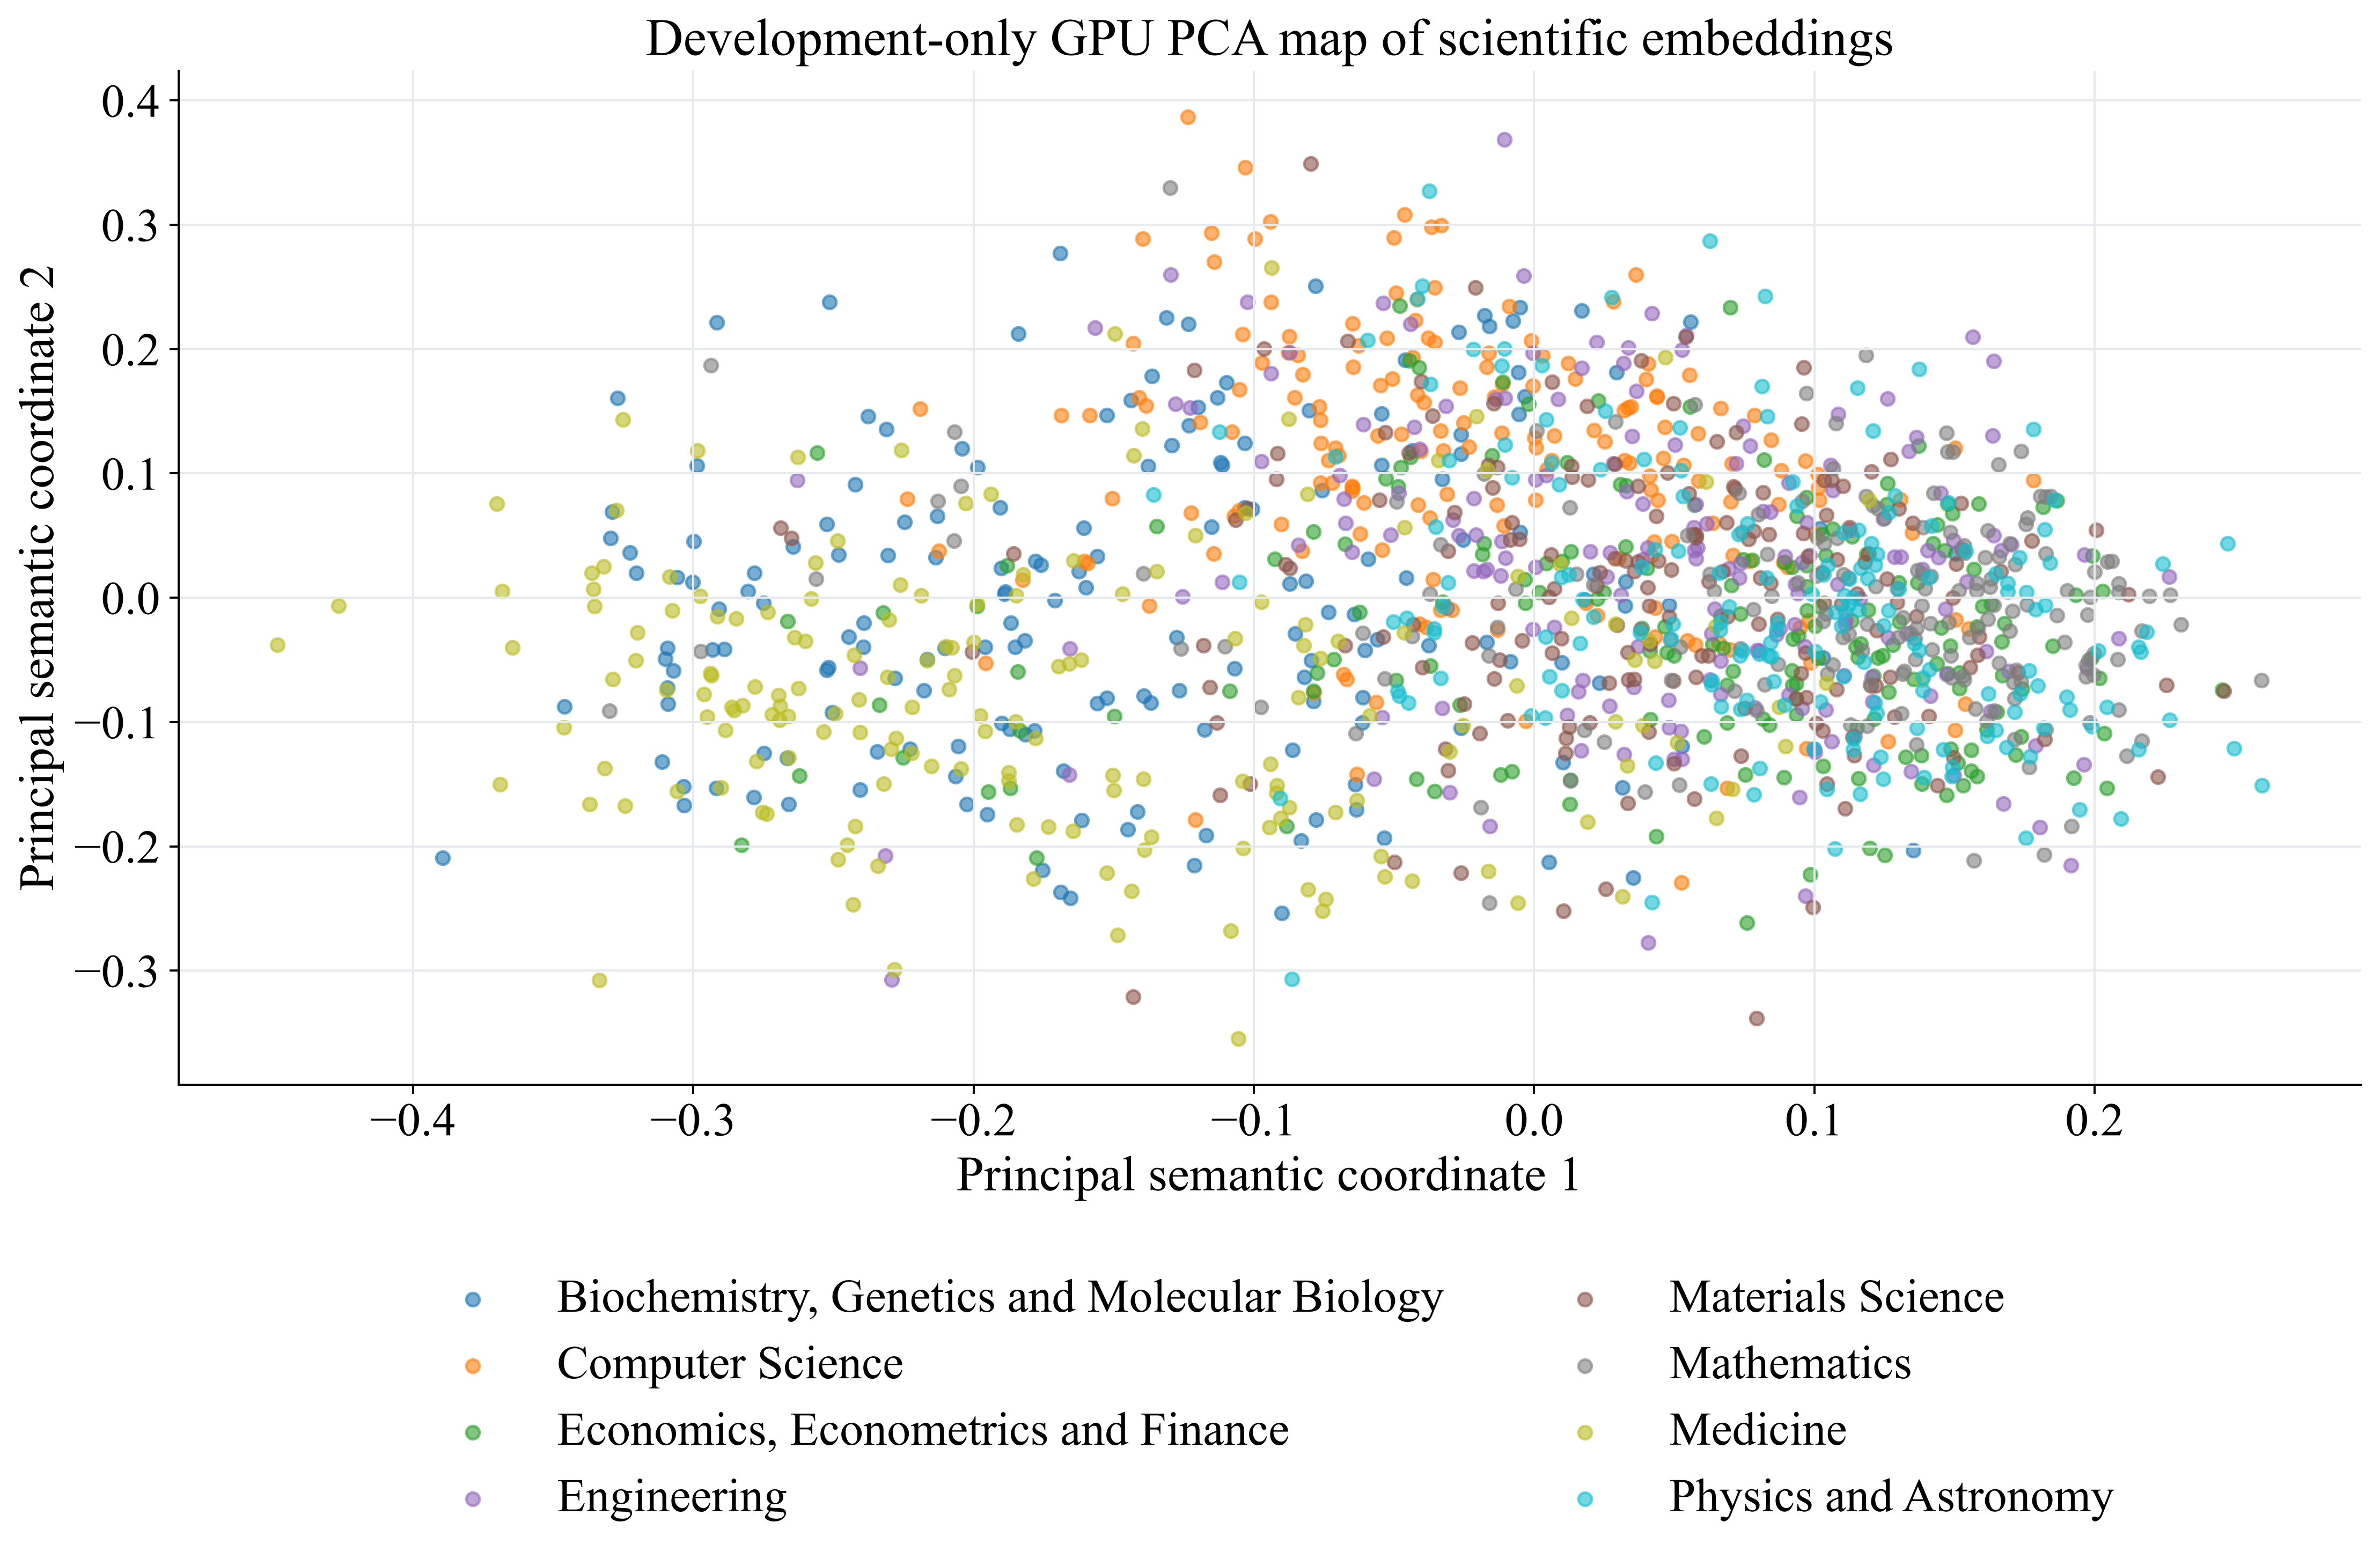

In [33]:
sample_indices = []
development_frame = deduplicated[deduplicated["split"].isin(["train", "validation"])]
for _, group in development_frame.groupby(["split", "thematic_class"]):
    sample_indices.extend(rng.choice(group.index.to_numpy(), min(90, len(group)), replace=False))
sample_indices = np.asarray(sample_indices, dtype=int)
sample_tensor = torch.from_numpy(jina_class_embeddings[sample_indices]).to(device)
centered = sample_tensor - sample_tensor.mean(dim=0, keepdim=True)
_, _, components = torch.pca_lowrank(centered, q=2, center=False)
projection = (centered @ components).cpu().numpy()
plot_meta = deduplicated.iloc[sample_indices].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 10))
colors = plt.cm.tab10(np.linspace(0, 1, len(class_order)))
for class_name, color in zip(class_order, colors):
    part = plot_meta["thematic_class"].eq(class_name)
    ax.scatter(
        projection[part, 0], projection[part, 1], s=26, alpha=0.60, color=color, label=class_name
    )
ax.set_title("Development-only GPU PCA map of scientific embeddings")
ax.set_xlabel("Principal semantic coordinate 1")
ax.set_ylabel("Principal semantic coordinate 2")
ax.grid(color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.34)
plt.show()
del sample_tensor, centered, components
torch.cuda.empty_cache()

### Scientific interpretation

The PCA projection is a two-dimensional diagnostic of high-dimensional semantic features. **Article-ready conclusion:** partial thematic structure is visible, with expected overlap between related fields. **Limitation:** PCA distances are not classifier probabilities and should not be over-interpreted.


## Class-centroid semantic geometry

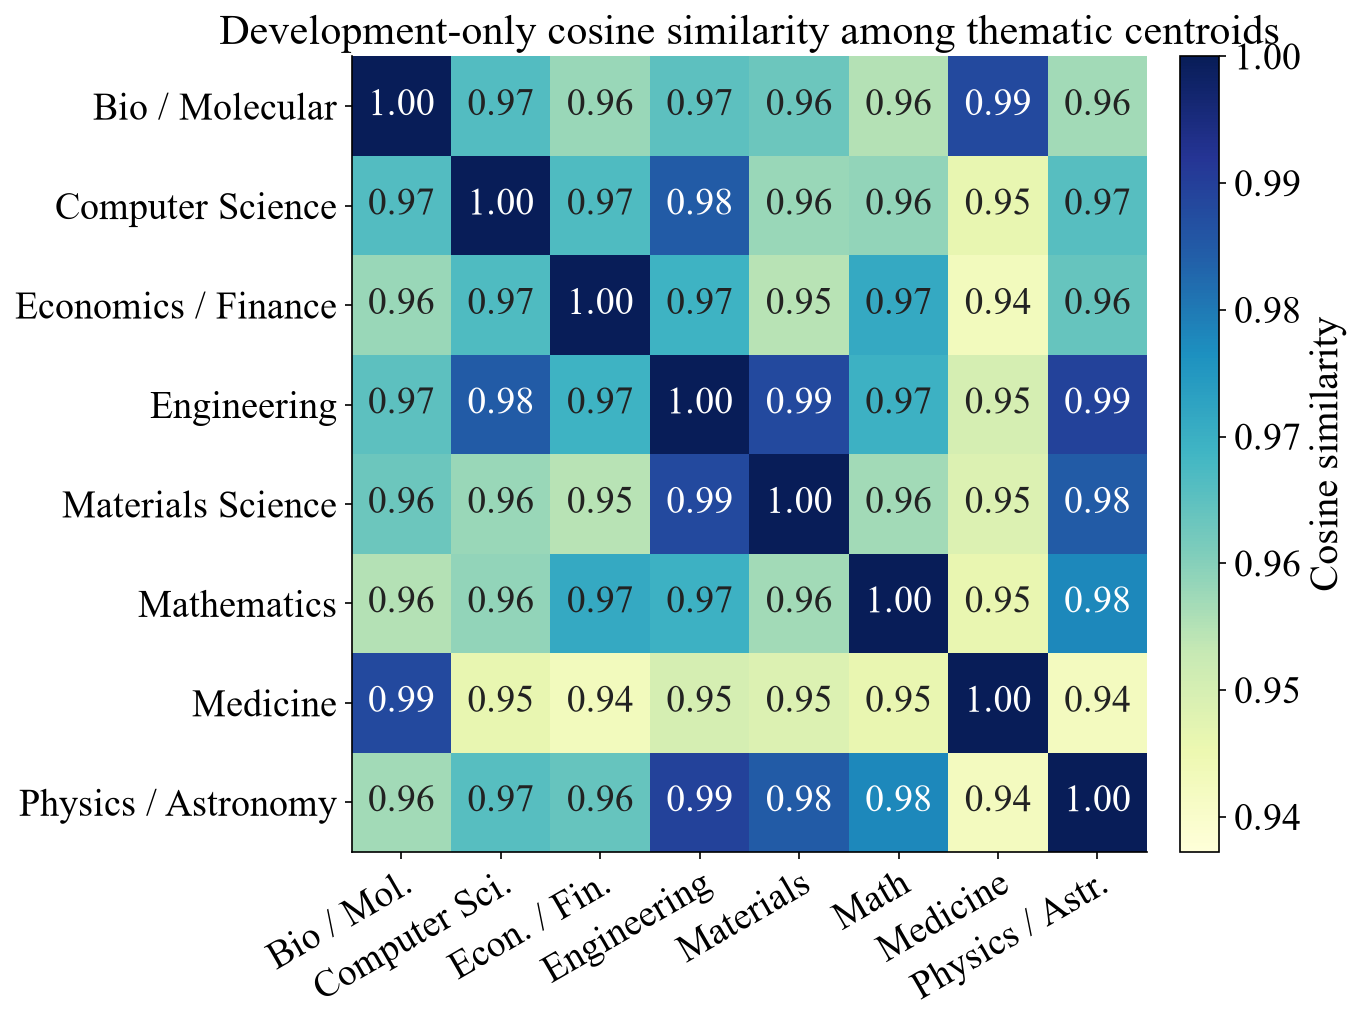

In [34]:
development_mask = deduplicated["split"].isin(["train", "validation"]).to_numpy()
centroids = []
for class_name in class_order:
    values = jina_class_embeddings[
        development_mask & deduplicated["thematic_class"].eq(class_name).to_numpy()
    ].mean(axis=0)
    values /= np.linalg.norm(values)
    centroids.append(values)
centroid_similarity = np.vstack(centroids) @ np.vstack(centroids).T
display_classes = [short_class_labels.get(name, name) for name in class_order]
x_axis_classes = [
    'Bio / Mol.',
    'Computer Sci.',
    'Econ. / Fin.',
    'Engineering',
    'Materials',
    'Math',
    'Medicine',
    'Physics / Astr.',
]
fig, ax = plt.subplots(figsize=(12.0, 7.8))
centroid_off_diagonal = centroid_similarity[~np.eye(len(class_order), dtype=bool)]
centroid_vmin = max(-1.0, float(centroid_off_diagonal.min()) - 0.005)
image = ax.imshow(centroid_similarity, cmap='YlGnBu', vmin=centroid_vmin, vmax=1.0)
ax.set_title('Development-only cosine similarity among thematic centroids')
ax.set_xticks(range(8), x_axis_classes, rotation=30, ha='right', rotation_mode='anchor')
ax.set_yticks(range(8), display_classes)
for i in range(8):
    for j in range(8):
        value = centroid_similarity[i, j]
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            j,
            i,
            f'{value:.2f}',
            ha='center',
            va='center',
            fontsize=18,
            color='white' if luminance < 0.48 else PALETTE['black'],
        )
colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.03)
colorbar.set_label('Cosine similarity')
fig.subplots_adjust(left=0.22, right=0.94, bottom=0.20, top=0.88)
plt.show()

### Scientific interpretation

The matrix compares semantic neighbourhood structure across the eight fields. **Article-ready conclusion:** semantic separability is heterogeneous by class, motivating class-wise rather than global retrieval correction. **Limitation:** the visualization is descriptive and encoder-dependent.


## Within-class versus between-class semantic distance

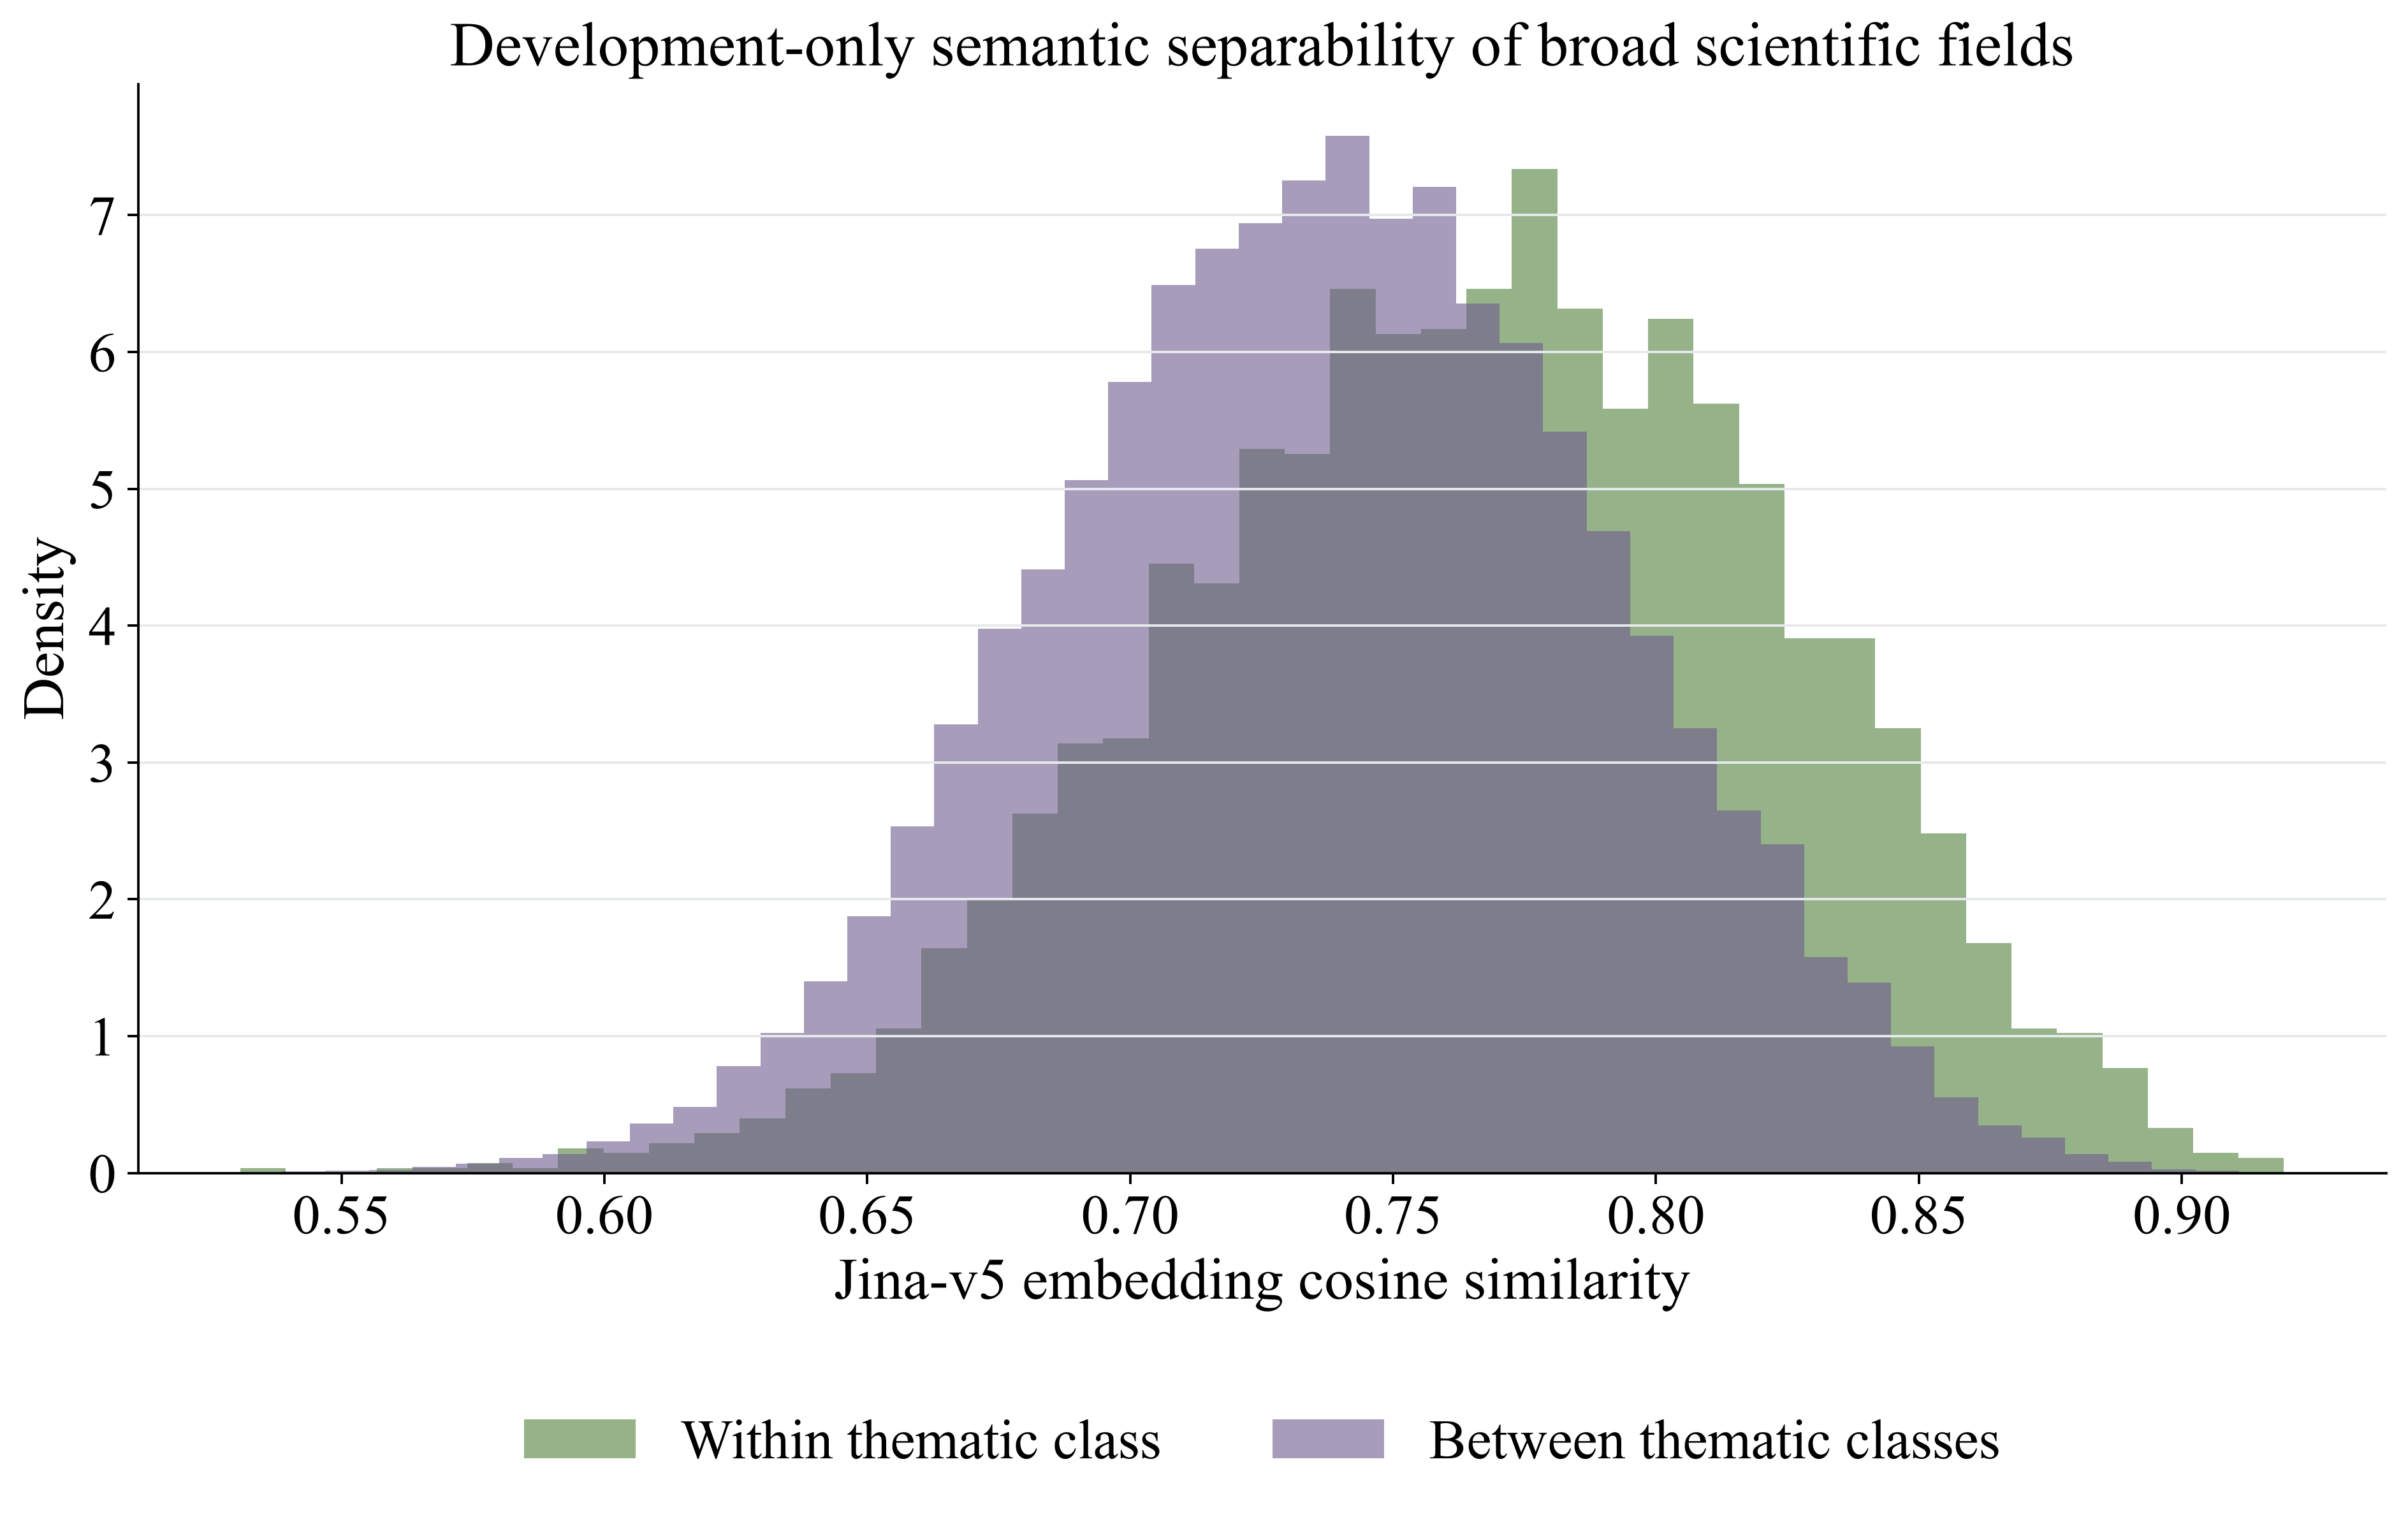

In [35]:
pair_count = 25000
development_indices = np.flatnonzero(deduplicated["split"].isin(["train", "validation"]).to_numpy())
left = rng.choice(development_indices, pair_count, replace=True)
right = rng.choice(development_indices, pair_count, replace=True)
valid = left != right
left, right = left[valid], right[valid]
pair_similarity = np.sum(jina_class_embeddings[left] * jina_class_embeddings[right], axis=1)
same_class = deduplicated["label_id"].to_numpy()[left] == deduplicated["label_id"].to_numpy()[right]
fig, ax = plt.subplots(figsize=(13, 8))
ax.hist(
    pair_similarity[same_class],
    bins=45,
    density=True,
    alpha=0.60,
    color=PALETTE["green"],
    label="Within thematic class",
)
ax.hist(
    pair_similarity[~same_class],
    bins=45,
    density=True,
    alpha=0.60,
    color=PALETTE["purple"],
    label="Between thematic classes",
)
ax.set_title("Development-only semantic separability of broad scientific fields")
ax.set_xlabel("Jina-v5 embedding cosine similarity")
ax.set_ylabel("Density")
ax.grid(axis="y", color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.27)
plt.show()

### Scientific interpretation

This cell audits cached feature dimensions, finiteness, and row alignment. **Article-ready conclusion:** all modelling views are aligned to the same development-row index. **Limitation:** schema integrity does not guarantee semantic correctness of every embedding.


## Class-wise OpenAlex-to-arXiv centroid shift

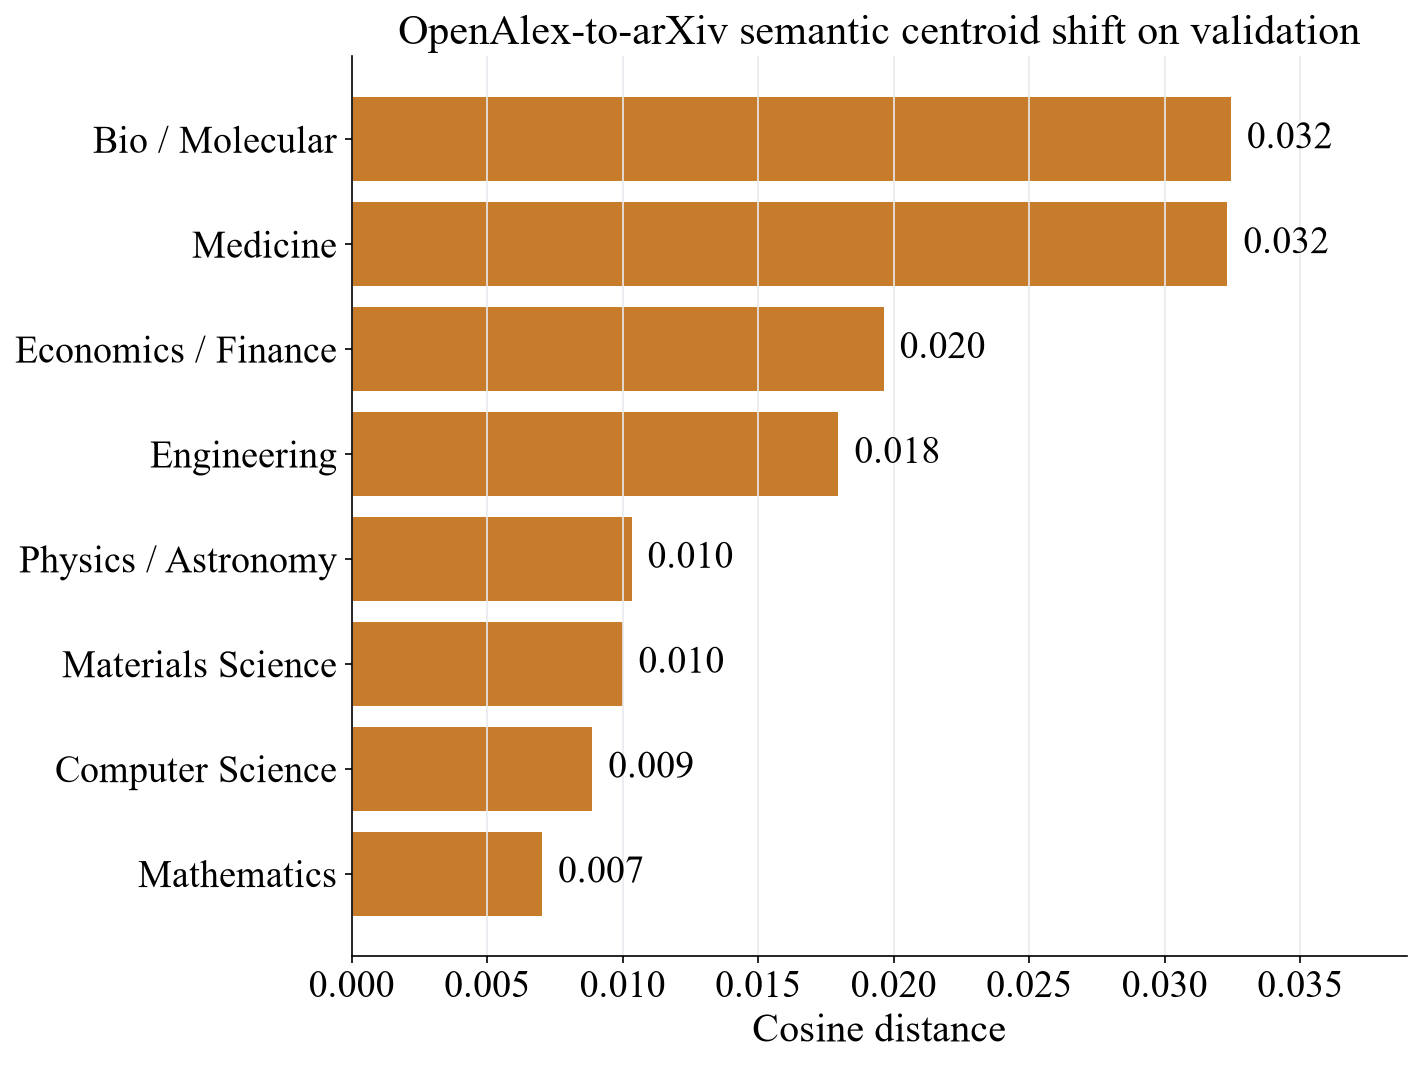

In [36]:
source_shift_rows = []
openalex_validation_mask = (
    deduplicated["split"].eq("validation") & deduplicated["source"].eq("openalex")
).to_numpy()
arxiv_validation_mask = (
    deduplicated["split"].eq("validation") & deduplicated["source"].eq("arxiv")
).to_numpy()
for class_id, class_name in enumerate(class_order):
    left_values = jina_class_embeddings[
        openalex_validation_mask & deduplicated["label_id"].eq(class_id).to_numpy()
    ]
    right_values = jina_class_embeddings[
        arxiv_validation_mask & deduplicated["label_id"].eq(class_id).to_numpy()
    ]
    if len(left_values) and len(right_values):
        left_centroid = left_values.mean(axis=0)
        right_centroid = right_values.mean(axis=0)
        cosine = np.dot(left_centroid, right_centroid) / (
            np.linalg.norm(left_centroid) * np.linalg.norm(right_centroid)
        )
        source_shift_rows.append((class_name, 1 - cosine))
source_shift_df = pd.DataFrame(
    source_shift_rows, columns=["thematic_class", "centroid_cosine_distance"]
).sort_values("centroid_cosine_distance")
source_shift_df['display_class'] = (
    source_shift_df['thematic_class']
    .map(short_class_labels)
    .fillna(source_shift_df['thematic_class'])
)
fig, ax = plt.subplots(figsize=(10.5, 8))
bars = ax.barh(
    source_shift_df['display_class'],
    source_shift_df['centroid_cosine_distance'],
    color=PALETTE['orange'],
)
ax.set_title('OpenAlex-to-arXiv semantic centroid shift on validation')
ax.set_xlabel('Cosine distance')
ax.set_ylabel('')
ax.grid(axis='x', color=PALETTE['light_gray'], linewidth=0.8)
maximum = source_shift_df['centroid_cosine_distance'].max()
ax.set_xlim(0, maximum * 1.20)
for bar, value in zip(bars, source_shift_df['centroid_cosine_distance']):
    ax.text(
        value + maximum * 0.018,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.3f}',
        va='center',
        fontsize=18,
    )
fig.subplots_adjust(left=0.30, right=0.97, bottom=0.13, top=0.88)
plt.show()

### Scientific interpretation

The split-balance view reports class proportions by grouped outer fold. **Article-ready conclusion:** grouped folds retain usable class coverage for repeated outer validation. **Limitation:** exact equality is neither expected nor required under group constraints.


## Class-specific informative log-odds terms

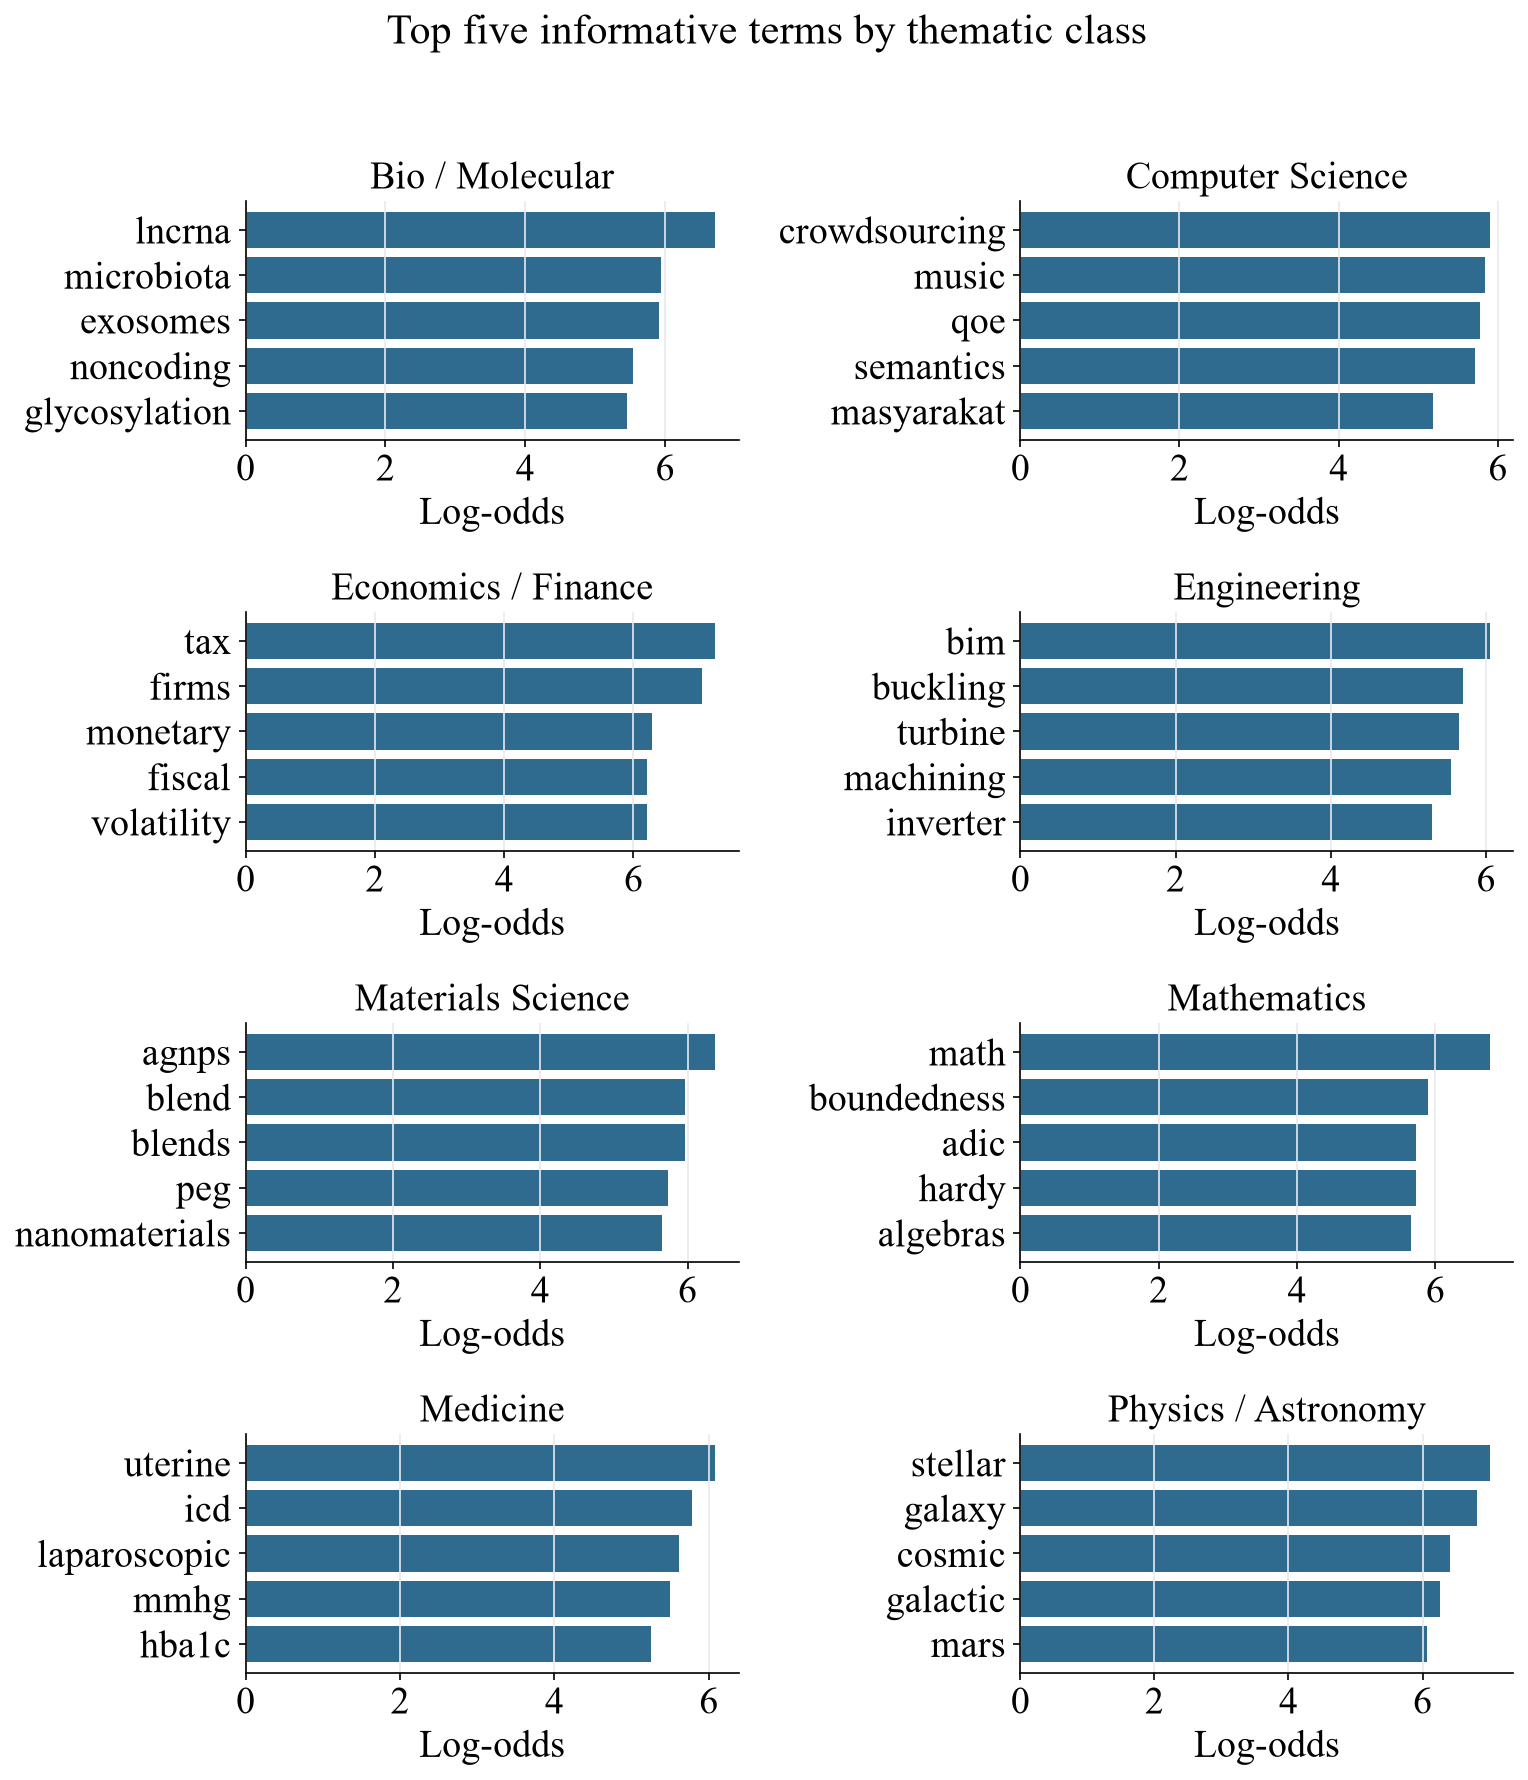

In [37]:
term_counts = CountVectorizer(max_features=20000, min_df=4, stop_words="english").fit_transform(
    deduplicated.loc[train_mask, "paper_text"]
)
term_names = CountVectorizer
# Refit once to retain the exact vocabulary used for the diagnostic.
logodds_vectorizer = CountVectorizer(max_features=20000, min_df=4, stop_words="english")
term_counts = logodds_vectorizer.fit_transform(deduplicated.loc[train_mask, "paper_text"])
term_names = logodds_vectorizer.get_feature_names_out()
train_labels = deduplicated.loc[train_mask, "label_id"].to_numpy()
total_counts = np.asarray(term_counts.sum(axis=0)).ravel()
logodds_rows = []
for class_id, class_name in enumerate(class_order):
    class_counts = np.asarray(term_counts[train_labels == class_id].sum(axis=0)).ravel()
    other_counts = total_counts - class_counts
    score = np.log((class_counts + 0.5) / (class_counts.sum() + 0.5 * len(term_names))) - np.log(
        (other_counts + 0.5) / (other_counts.sum() + 0.5 * len(term_names))
    )
    for index in np.argsort(score)[-5:]:
        logodds_rows.append((class_name, term_names[index], score[index]))
logodds_df = pd.DataFrame(logodds_rows, columns=["thematic_class", "term", "log_odds"])
short_class_labels = {
    'Biochemistry, Genetics and Molecular Biology': 'Bio / Molecular',
    'Economics, Econometrics and Finance': 'Economics / Finance',
    'Physics and Astronomy': 'Physics / Astronomy',
}
fig, axes = plt.subplots(4, 2, figsize=(10.5, 12), sharex=False)
for axis, class_name in zip(axes.flat, class_order):
    part = logodds_df[logodds_df['thematic_class'].eq(class_name)].sort_values('log_odds')
    axis.barh(part['term'], part['log_odds'], color=PALETTE['blue'])
    axis.set_title(short_class_labels.get(class_name, class_name), fontsize=18)
    axis.grid(axis='x', color=PALETTE['light_gray'], linewidth=0.8)
    axis.set_xlabel('Log-odds', fontsize=18)
fig.suptitle('Top five informative terms by thematic class', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

### Scientific interpretation

The term panels summarize the highest-weight class-specific lexical features. **Article-ready conclusion:** learned lexical signals are scientifically interpretable at the field level. **Limitation:** coefficient magnitude is model-specific and not causal feature importance.


## Persist modeling tables, indices, and semantic seed profiles

In [38]:
modeling_columns = [
    "row_index",
    "sample_id",
    "source",
    "cohort",
    "paper_id",
    "doi",
    "title_raw",
    "abstract_raw",
    "title_clean",
    "abstract_clean",
    "paper_text",
    "paper_text_enriched",
    "safe_keyword_text",
    "publication_year",
    "publication_date",
    "language",
    "source_name",
    "source_type",
    "work_type",
    "cited_by_count",
    "citations_per_year",
    "log_citations_per_year",
    "open_access",
    "author_count",
    "title_length",
    "abstract_length",
    "token_count",
    "keyword_count",
    "has_keywords",
    "exact_component",
    "near_component",
    "thematic_class",
    "label_id",
    "split",
    "validation_domain",
]
modeling_df = deduplicated[modeling_columns].copy()
modeling_df.to_parquet(DATASET / "unified/modeling_dataset.parquet", index=False)
deduplicated.to_parquet(DATASET / "unified/unified_dataset.parquet", index=False)
metadata_frame = modeling_df[
    ["row_index", "sample_id", "split", *primary_numeric, *enriched_categorical]
].copy()
metadata_frame.to_parquet(DATASET / "unified/metadata_features.parquet", index=False)
np.savez(
    DATASET / "unified/split_indices.npz",
    train=np.flatnonzero(modeling_df["split"].eq("train")),
    validation=np.flatnonzero(modeling_df["split"].eq("validation")),
    test=np.flatnonzero(modeling_df["split"].eq("test")),
    external_test=np.flatnonzero(modeling_df["split"].eq("external_test")),
)
with (DATASET / "unified/semantic_profiles_seed.jsonl").open("w", encoding="utf-8") as stream:
    for row in modeling_df.itertuples(index=False):
        stream.write(
            json.dumps(
                {
                    "sample_id": row.sample_id,
                    "source": row.source,
                    "paper_id": row.paper_id,
                    "title": row.title_raw,
                    "publication_year": int(row.publication_year),
                    "true_thematic_class": row.thematic_class,
                    "split": row.split,
                },
                ensure_ascii=False,
            )
            + "\n"
        )
print({"modeling_rows": len(modeling_df), "classes": modeling_df["thematic_class"].nunique()})

{'modeling_rows': 9803, 'classes': 8}


In [39]:
split_summary = (
    modeling_df.groupby(["split", "source", "thematic_class"], as_index=False)
    .size()
    .rename(columns={"size": "records"})
)
split_summary.to_csv(TABLES / "split_summary.csv", index=False)
leakage_check_df.to_csv(TABLES / "leakage_check_summary.csv", index=False)

preprocessing_summary = pd.DataFrame(
    [
        ("raw_records", len(raw_cohorts)),
        ("quality_filtered_records", len(working)),
        ("exact_conflict_or_duplicate_removals", len(working) - len(non_conflicting)),
        ("near_conflict_or_duplicate_removals", len(non_conflicting) - len(deduplicated)),
        ("modeling_records", len(modeling_df)),
        ("classes", modeling_df["thematic_class"].nunique()),
        ("author_overlap_test_train", author_overlap_rate),
        ("venue_overlap_test_train_nonempty", venue_overlap_rate),
        ("cross_split_exact_violations", leakage_check_df["violations"].sum()),
    ],
    columns=["metric", "value"],
)
preprocessing_summary.to_csv(TABLES / "preprocessing_summary.csv", index=False)

feature_group_summary = pd.DataFrame(
    [
        ("lexical primary", lexical_matrix.shape[1], "title+abstract; train-only fit"),
        (
            "lexical enriched",
            enriched_lexical_matrix.shape[1],
            "title+abstract+proxy-scrubbed keywords; train-only fit",
        ),
        (
            "semantic backbones",
            len(embedding_manifest),
            "pinned frozen CUDA encoders; matched 512-token context",
        ),
        (
            "metadata primary",
            metadata_primary.shape[1],
            "stable numeric only; no raw venue/source shortcut",
        ),
        (
            "metadata enriched",
            metadata_enriched.shape[1],
            "same information for all all-modal comparators",
        ),
        (
            "concept",
            concept_matrix.shape[1],
            "title+abstract candidates; keywords are supervision only",
        ),
    ],
    columns=["feature_group", "dimensions_or_models", "definition"],
)
feature_group_summary.to_csv(TABLES / "feature_group_summary.csv", index=False)

manifest_payload = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "models": embedding_manifest,
    "package_versions": {
        "torch": torch.__version__,
        "transformers": __import__("transformers").__version__,
        "sentence_transformers": __import__("sentence_transformers").__version__,
    },
}
(DATASET / "unified/semantic_embedding_manifest.json").write_text(
    json.dumps(manifest_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
display(feature_group_summary)

,feature_group,dimensions_or_models,definition
0,lexical primary,65116,title+abstract; train-only fit
1,lexical enriched,47954,title+abstract+proxy-scrubbed keywords; train-...
2,semantic backbones,7,pinned frozen CUDA encoders; matched 512-token...
3,metadata primary,7,stable numeric only; no raw venue/source shortcut
4,metadata enriched,14,same information for all all-modal comparators
5,concept,23431,title+abstract candidates; keywords are superv...


## SPECTER2 classification-adapter representation

In [42]:
adapter_runtime = Path("/tmp/massk_specter2_adapter_runtime")
adapter_output = DATASET / "unified/semantic_embeddings_specter2_classification.npy"
adapter_manifest_path = DATASET / "unified/specter2_classification_adapter_manifest.json"

adapter_program = r"""
import hashlib
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from adapters import AutoAdapterModel
from transformers import AutoTokenizer

root = Path(sys.argv[1])
output_path = Path(sys.argv[2])
manifest_path = Path(sys.argv[3])
frame = pd.read_parquet(root / "dataset/unified/modeling_dataset.parquet").sort_values("row_index")

base_id = "allenai/specter2_base"
base_revision = "3447645e1def9117997203454fa4495937bfbd83"
adapter_id = "allenai/specter2_classification"
adapter_revision = "d843816b414a856d9a5268d5865f188bb589e6e1"
cache = "/home/azyqan/cache/huggingface/hub"

tokenizer = AutoTokenizer.from_pretrained(base_id, revision=base_revision, cache_dir=cache)
model = AutoAdapterModel.from_pretrained(base_id, revision=base_revision, cache_dir=cache)
loaded_adapter = model.load_adapter(adapter_id, version=adapter_revision, set_active=True)
assert model.active_adapters is not None
model = model.cuda().eval()

texts = [
    title + tokenizer.sep_token + abstract
    for title, abstract in zip(frame.title_clean, frame.abstract_clean)
]
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
chunks = []
started = time.perf_counter()

with torch.inference_mode():
    for start in range(0, len(texts), 32):
        batch = tokenizer(
            texts[start : start + 32],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
            return_token_type_ids=False,
        ).to("cuda")
        with torch.autocast("cuda", dtype=torch.bfloat16):
            values = model(**batch).last_hidden_state[:, 0]
        chunks.append(torch.nn.functional.normalize(values.float(), dim=1).cpu().numpy())

torch.cuda.synchronize()
elapsed = time.perf_counter() - started
matrix = np.vstack(chunks).astype("float32")
np.save(output_path, matrix)

manifest = {
    "model_id": base_id,
    "revision": base_revision,
    "adapter_id": adapter_id,
    "adapter_revision": adapter_revision,
    "loaded_as": str(loaded_adapter),
    "pooling": "CLS",
    "max_length": 512,
    "rows": len(matrix),
    "dimensions": matrix.shape[1],
    "seconds": elapsed,
    "peak_vram_gib": torch.cuda.max_memory_allocated() / 2**30,
    "sha256": hashlib.sha256(output_path.read_bytes()).hexdigest(),
}
manifest_path.write_text(json.dumps(manifest, indent=2))
"""

environment = os.environ.copy()
environment["PYTHONPATH"] = str(adapter_runtime)
environment["HF_HOME"] = "/home/azyqan/cache/huggingface/hub"
subprocess.run(
    [
        sys.executable,
        "-c",
        adapter_program,
        str(PROJECT_ROOT),
        str(adapter_output),
        str(adapter_manifest_path),
    ],
    check=True,
    env=environment,
    text=True,
)

specter2_classification_embeddings = np.load(adapter_output)
adapter_manifest = json.loads(adapter_manifest_path.read_text())
display(pd.DataFrame([adapter_manifest]))

,model_id,revision,adapter_id,adapter_revision,loaded_as,pooling,max_length,rows,dimensions,seconds,peak_vram_gib,sha256
0,allenai/specter2_base,3447645e1def9117997203454fa4495937bfbd83,allenai/specter2_classification,d843816b414a856d9a5268d5865f188bb589e6e1,[CLF],CLS,512,9803,768,63.590547,0.921001,e9a1a4acf5e5ea1a64012879ec1e27a6ad8962a0469391...


## SciNCL scholarly representation

In [43]:
SCINCL_ID = "malteos/scincl"
SCINCL_REVISION = "ebc5348d184ba2fc9beee69b4e394263fce57b2e"

scincl_model = SentenceTransformer(
    SCINCL_ID,
    revision=SCINCL_REVISION,
    device="cuda",
)
scincl_model.max_seq_length = 512
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()

scincl_values = scincl_model.encode(
    texts,
    batch_size=48,
    normalize_embeddings=True,
    show_progress_bar=False,
    convert_to_numpy=True,
)
torch.cuda.synchronize()
scincl_elapsed = time.perf_counter() - started
scincl_embeddings = save_embedding(
    "semantic_embeddings_scincl",
    scincl_values,
    SCINCL_ID,
    SCINCL_REVISION,
    "citation-informed scholarly representation",
    scincl_elapsed,
    "model-defined mean pooling",
    "",
    512,
)
scincl_summary = pd.DataFrame(
    [
        {
            "model": "SciNCL",
            "rows": scincl_embeddings.shape[0],
            "dimensions": scincl_embeddings.shape[1],
            "encoding_seconds": scincl_elapsed,
            "peak_vram_gib": torch.cuda.max_memory_allocated() / 2**30,
        }
    ]
)
del scincl_model
torch.cuda.empty_cache()
display(scincl_summary)

## Physical development-only corpus and feature views

No refinement cell may load labels or predictions from the historical test or external-test rows. Original row indices are retained only to make this one-time physical extraction auditable.


In [44]:
development_mask = modeling_df['split'].isin(['train', 'validation']).to_numpy()
development_indices = np.flatnonzero(development_mask)
forbidden_ids = set(modeling_df.loc[~development_mask, 'sample_id'])
development = modeling_df.loc[development_mask].copy()
development.insert(0, 'development_row_index', np.arange(len(development), dtype=np.int64))
development = development.rename(columns={'row_index': 'original_row_index'})
assert set(development['split']).issubset({'train', 'validation'})
assert forbidden_ids.isdisjoint(set(development['sample_id']))
development.to_parquet(DATASET / 'unified/development_dataset.parquet', index=False)
development_identity = (
    deduplicated.set_index('sample_id')
    .loc[
        development['sample_id'],
        ['authors_json', 'institutions_json', 'topics_json', 'fields_json'],
    ]
    .reset_index()
)
development_reference_concepts = (
    concept_frame.set_index('sample_id')
    .loc[development['sample_id'], ['reference_concepts_json', 'keyword_count']]
    .reset_index()
)
assert development_identity['sample_id'].tolist() == development['sample_id'].tolist()
assert development_reference_concepts['sample_id'].tolist() == development['sample_id'].tolist()
development_identity.to_parquet(DATASET / 'unified/development_identity.parquet', index=False)
development_reference_concepts.to_parquet(
    DATASET / 'unified/development_reference_concepts.parquet', index=False
)
sparse.save_npz(
    DATASET / 'unified/development_lexical_features.npz', lexical_matrix[development_indices]
)
sparse.save_npz(
    DATASET / 'unified/development_metadata_features.npz', metadata_enriched[development_indices]
)
sparse.save_npz(
    DATASET / 'unified/development_concept_features.npz', concept_matrix[development_indices]
)
development_embeddings = {
    'qwen3_instruction': DATASET / 'unified/semantic_embeddings_qwen3_0_6b.npy',
    'specter2_classification': adapter_output,
    'jina_v5_classification': DATASET / 'unified/semantic_embeddings_jina_v5_classification.npy',
}
if scincl_embeddings is not None:
    development_embeddings['scincl'] = DATASET / 'unified/semantic_embeddings_scincl.npy'
feature_rows = []
for name, source_path in development_embeddings.items():
    values = np.load(source_path, mmap_mode='r')[development_indices].astype(np.float32)
    target = DATASET / f'unified/development_semantic_{name}.npy'
    np.save(target, values)
    feature_rows.append(
        {
            'feature': name,
            'rows': len(values),
            'dimensions': values.shape[1],
            'sha256': hashlib.sha256(target.read_bytes()).hexdigest(),
        }
    )
display(pd.DataFrame(feature_rows))

,feature,rows,dimensions,sha256
0,qwen3_instruction,6708,1024,0e5819ee2ecdfe6763bd5462e7f4d669f37cad10835f3e...
1,specter2_classification,6708,768,a806ee9ead447344de3f52df3fd9f83cc990bbf96de547...
2,jina_v5_classification,6708,768,6fbbd15f6c8caf493199bd252c9158e9dbb8ebbf3c634b...
3,scincl,6708,768,c3a89a19816f661e36d33c6c46a5f6b51f716f5f891ca2...


## Repeated stratified-group validation assignments


In [45]:
from sklearn.model_selection import StratifiedGroupKFold

year_bin = pd.cut(
    development.publication_year,
    [-np.inf, 2020, 2022, 2024, np.inf],
    labels=['≤2020', '2021–2022', '2023–2024', '≥2025'],
).astype(str)
base_stratum = (
    development.thematic_class.astype(str)
    + ' | '
    + development.source.astype(str)
    + ' | '
    + year_bin
)
counts = base_stratum.value_counts()
collapsed = base_stratum.where(
    base_stratum.map(counts).ge(6),
    development.thematic_class.astype(str) + ' | ' + development.source.astype(str),
)
counts = collapsed.value_counts()
stratum = collapsed.where(collapsed.map(counts).ge(6), development.thematic_class.astype(str))
groups = development.near_component.astype(str)
assignment_parts = []
for repeat, seed in enumerate([20260731, 20260831]):
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    fold_values = np.full(len(development), -1, dtype=np.int64)
    for fold, (_, holdout) in enumerate(splitter.split(development, stratum, groups)):
        fold_values[holdout] = fold
    assert (fold_values >= 0).all()
    audit = pd.DataFrame({'group': groups, 'fold': fold_values}).groupby('group').fold.nunique()
    assert audit.max() == 1
    assignment_parts.append(
        pd.DataFrame(
            {
                'development_row_index': development.development_row_index,
                'sample_id': development.sample_id,
                'repeat': repeat,
                'outer_fold': fold_values,
                'stratum': stratum,
                'group_id': groups,
            }
        )
    )
fold_assignments = pd.concat(assignment_parts, ignore_index=True)
fold_assignments.to_parquet(TABLES / 'nested_fold_assignments.parquet', index=False)
fold_balance = (
    fold_assignments.merge(
        development[['development_row_index', 'thematic_class', 'source']],
        on='development_row_index',
    )
    .groupby(['repeat', 'outer_fold', 'thematic_class', 'source'], as_index=False)
    .size()
    .rename(columns={'size': 'rows'})
)
fold_balance.to_csv(TABLES / 'fold_balance_audit.csv', index=False)
display(
    fold_balance.groupby(['repeat', 'outer_fold'], as_index=False).agg(
        rows=('rows', 'sum'), minimum_cell=('rows', 'min'), maximum_cell=('rows', 'max')
    )
)

,repeat,outer_fold,rows,minimum_cell,maximum_cell
0,0,0,2236,47,294
1,0,1,2236,47,295
2,0,2,2236,47,296
3,1,0,2236,47,295
4,1,1,2236,47,295
5,1,2,2236,47,295


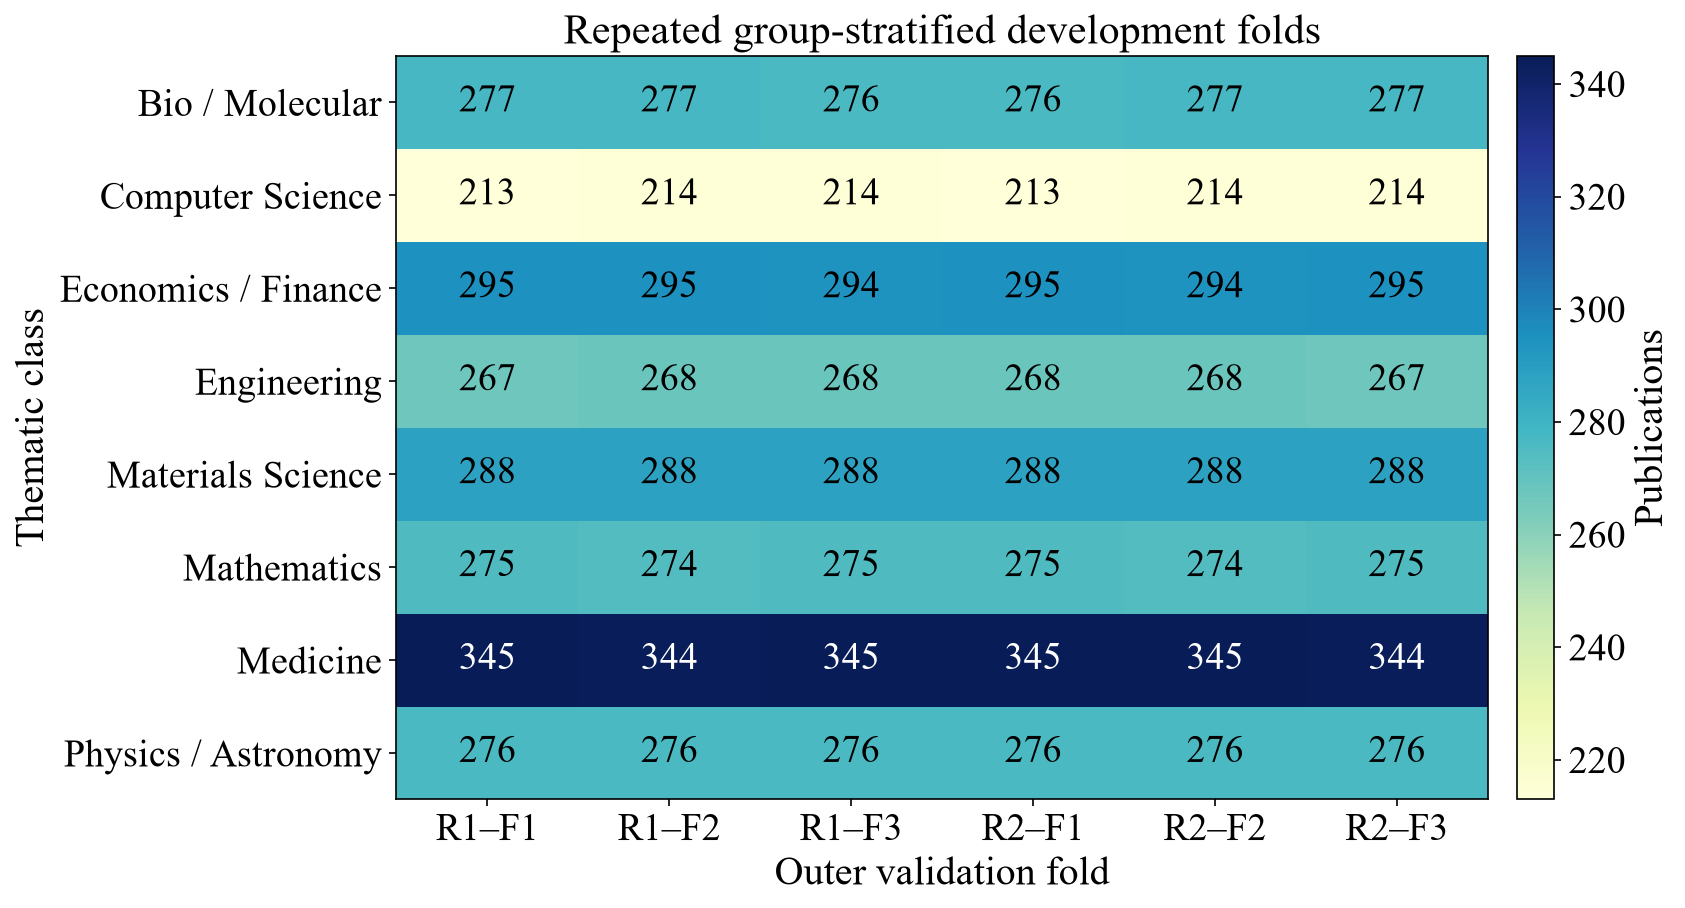

In [49]:
fold_index = 'thematic_class' if 'thematic_class' in fold_balance.columns else 'label_id'
matrix = fold_balance.pivot_table(
    index=fold_index, columns=['repeat', 'outer_fold'], values='rows', aggfunc='sum'
).fillna(0)
class_display = {
    'Biochemistry, Genetics and Molecular Biology': 'Bio / Molecular',
    'Economics, Econometrics and Finance': 'Economics / Finance',
    'Materials Science': 'Materials Science',
    'Physics and Astronomy': 'Physics / Astronomy',
}
if fold_index == 'label_id':
    label_name_map = (
        development[['label_id', 'thematic_class']]
        .drop_duplicates()
        .set_index('label_id')['thematic_class']
        .to_dict()
    )
    row_labels = [
        class_display.get(
            label_name_map.get(label, str(label)), label_name_map.get(label, str(label))
        )
        for label in matrix.index
    ]
else:
    row_labels = [class_display.get(label, label) for label in matrix.index]
fig, ax = plt.subplots(figsize=(11.5, 6.4))
image = ax.imshow(matrix.to_numpy(), cmap='YlGnBu', aspect='auto')
ax.set_yticks(np.arange(len(matrix.index)), row_labels)
ax.set_xticks(np.arange(matrix.shape[1]), [f'R{r+1}–F{f+1}' for r, f in matrix.columns])
ax.set_title('Repeated group-stratified development folds')
ax.set_xlabel('Outer validation fold')
ax.set_ylabel('Thematic class')
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix.iloc[row, column]
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            column,
            row,
            f'{int(value)}',
            ha='center',
            va='center',
            fontsize=18,
            color=PALETTE['white'] if luminance < 0.48 else PALETTE['black'],
        )
colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.025)
colorbar.set_label('Publications')
fig.tight_layout()
path = PROJECT_ROOT / 'results/figures/nested_validation_balance.png'
fig.savefig(path, dpi=350, bbox_inches='tight', facecolor='white')
plt.show()

### Scientific interpretation

The final preprocessing audit consolidates row counts, split roles, and leakage checks. **Article-ready conclusion:** the modelling inputs are traceable to an explicit, group-aware development protocol. **Limitation:** test/external cohorts were historically exposed and cannot serve as confirmatory outcomes.
